# Experiment 2 — the effect of architecture on detecting task-relevant and task-irrelevant features

**PLAN.md, experiment 2.** *(Excessive architecture) + (task-irrelevant topology can be ignored).*
The datasets are the same as in experiment 1: `simple_irrelevant` and `simple_relevant` — a pair in
which the circle is bitwise the same and the only difference is whether it is needed to solve the task.
The variable now is **the size of the network**.

---

## Main goal

Measure how architecture — width and depth — changes the detection of task-relevant and task-irrelevant
features: whether a single witness of the irrelevant circle appears when networks are given more neurons
than the task needs, and what happens to the relevant circle at the minimum and in excess.

---

## What we do — in brief

**Step 0 (technical, not a task).** The minimal solving architectures and the pool. Without it there is
no axis: "excess architecture" is defined only relative to the minimal one, and the minimal one differs
between the two datasets. Three sub-steps: the width–depth trade-off (0.1), the choice of the pool (0.2),
training (0.3).

Then — five tasks. All of them read one and the same trained pool; width and depth are axes within each
task, not separate items.

**A. Task-irrelevant: does excess architecture produce a witness?**
Does detection of the irrelevant circle appear as the number of neurons grows, and does the separation
from the floor grow.

**B. Task-relevant: what happens at the minimum and in excess.**
Does a single witness remain at the minimal architecture, and does the fraction of witnesses hold up in
excess.

**C. Witnesses by layer.**
Extending into depth the profile already measured at 5x5, and whether the break shifts with width.

**D. Width against depth at an equal budget of neurons.**
The same number of neurons, a different shape — the pure effect of arrangement.

**E. Over-training on excess architectures.**
What happens if a network is given not only more neurons than it needs but also more time than it
needs. It is also the designated control of the confound "width against training duration".

**There is no sweep over the criterion's hyperparameters.** The configuration of experiment 1
(`resolution = 200`, `n_levels = 101`, `level_eps = "adaptive"`, `tau = 0.1`, `max_sample_points = 7000`)
is inherited as is: the box is the same, the circle is the same, `N_A ~ 40` holds.

In [1]:
# IMPORTANT: before any import of torch. Training and evaluation run as a pool of
# processes, one thread each; if the parent brings up a BLAS pool of 14-32
# threads, the workers will fight over cores and everything gets slower, not faster.
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

# Repository root as CWD, src/ on sys.path — the convention of the persistence layer.
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "src" / "analysis").is_dir():
    assert root != root.parent, "repository root not found"
    root = root.parent
os.chdir(root)
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))
print("CWD:", Path.cwd())

CWD: /home/serdabel/Desktop/proga/task-relevance-of-topological-features


---

# Step 0 (technical). The minimal solving architectures and the pool

Not a task of the experiment and not a result — without it there is simply no axis. "Excess
architecture" is defined only relative to the minimal one, and the minimal one differs between the two
datasets.

## 0.1 The width–depth trade-off

The question is not "what width is needed at depth 1" but where the boundary of solvability runs in the
(width, depth) plane at all: can one take width 1–2 and make up for it with depth, and what lies in
between.

For `simple_relevant` (a disk r = 1 inside a circle r = 1.5, different classes) there are two
**analytical** answers to this, not empirical ones.

**Width 1 does not work at any depth.** If every hidden layer has width 1, the whole network is
`phi(w·x + b)` for a scalar chain `phi`. Its level curves are straight lines, and its decision regions are
unions of strips. A strip containing the disk r = 1 must have a half-width >= 1 and therefore takes in
part of the circle r = 1.5.

**Width 2 does not work at any depth.** At width 2 the map `x -> h_l` is a composition of invertible
affine maps R^2 -> R^2 and the coordinate-wise `tanh` (a diffeomorphism onto `(-1, 1)`), that is, **a
diffeomorphism of R^2 onto an open set**. The output is a linear functional of `h_last`, so the decision
boundary is the preimage of a straight line under a diffeomorphism, and that is always a union of arcs and
**never a closed curve**. Such a boundary cannot enclose the disk.

The same argument implies something that matters more for the experiment itself:

> **A witness of the circle requires width >= 3 and layer >= 1.** A neuron of layer l >= 1 at width 2 is
> `tanh(row · h_{l-1} + b)`; its level curves are again the preimage of a straight line under a
> diffeomorphism, that is, arcs. In a network of width 2 no neuron on any layer has closed level curves.
> At width 3 the image of the first layer is a two-dimensional surface in R^3, and a plane can cut a
> closed loop out of a curved surface; exactly at three this becomes possible. Layer 0 gives straight lines
> at any width — this has already been confirmed by the data of experiment 1 (0 witnesses out of 250 on
> both datasets).

That is, the cells `w1`, `w2` and `d1` are **analytically dead**, and in them the instrument must return
exactly zero. This is a free validity control: a non-zero witness there means a broken instrument, not
an effect found.

A caveat that has to be checked rather than postulated: the circle in the data is 500 **points**, not a
curve, with a gap of ~ 0.019 between neighbours. Formally a network of width 2 could slip an arc through
a gap. In practice this is a degenerate solution, and step 0 will show whether gradient descent finds it.

**What we do — a ladder search, not a full grid.** We are interested in the boundary, and architectures
known to lie above it tell us nothing: they solve the task by construction. So for each depth d = 1…6 we
go up from width 1 and stop at the first width where >= 8 seeds out of 10 solve the task.

> **The 8/10 threshold is a stopping condition for the ladder, not an estimate of the boundary.** It
> turns a noisy binomial fraction into a binary answer: with a true success probability p = 0.9 and ten
> seeds a cell fails the threshold in 7% of cases, and over six depths at least one fails with probability
> **0.35**. This is exactly how a ragged boundary appears that does not exist in nature. Conclusions are
> drawn from the fraction with a confidence interval (`capacity_probe.frontier_rates`), not from "passed /
> failed". The gate is the same as in 0.3 (`target = 1.0`, `min_epochs = 0`,
`patience = 5`, a ceiling of 300 epochs), the networks are tiny, training saves nothing: these are probes,
not members of ensembles.

For each seed we record not only "reached / did not reach" but also `stopped_epoch` — because a failure
has two different causes, and they have to be told apart: there is no solution in principle
(expressivity), or there is a solution but gradient descent does not find it (optimisation). The second is
recognised by part of the seeds reaching the gate while the rest run into the epoch ceiling.

Prediction: for `simple_relevant` the boundary runs along width 3 and barely moves with depth; for
`simple_irrelevant` the minimum is one neuron in one layer.

The result is `analysis/results/experiments/exp2_arch_sweep/step0_minimal_architectures.csv`
(one row per (dataset, depth)) and `step0_capacity_frontier.csv` (one row per seed).

---

### Result

Computed twice: first with a budget of 300 epochs, then with 3000. **The numbers at 3000 are the right
ones** — at 300 epochs the narrow and deep networks simply did not have time to train, and almost all the
oddities of the first table turned out to be that.

#### The minimal width equals 3 at any depth

`simple_relevant`, width 3, a budget of 3000 epochs — how many networks out of 10 trained to 100% test
accuracy and held it for 5 epochs in a row:

| depth | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| reached, of 10 | 6 | 10 | 9 | 10 | 10 | 8 |
| 95% CI | .31–.83 | .72–1.0 | .60–.98 | .72–1.0 | .72–1.0 | .49–.94 |
| median gate epoch | **2439** | 111 | 109 | 90 | 225 | 118 |

Pooled over depths 2–6: **47/50 = 0.94**. The test of homogeneity across depths: chi2 = 5.67, dof = 4,
**p = 0.22** — the differences between depths are indistinguishable from binomial noise. Hence the
verdict:

> **The minimal width for `simple_relevant` equals 3 at any depth; for `simple_irrelevant` it is 1 at any
> depth.** There is no trade-off between width and depth: the boundary of solvability is a vertical line,
> not a staircase.

The earlier (depth, min. width) = (3, 4) and (6, 4) were an artefact of the hard threshold, not a property
of the network, and this is not a guess: at p = 0.94 a cell fails the 8/10 threshold in 1.9% of cases,
and at least one of six depths fails in 11%.

#### Why the minimal width cannot grow with depth in principle

The class of functions is monotone in depth: `tanh(eps*x)/eps -> x` as `eps -> 0`, so a layer with small
weights approximates the identity map arbitrarily well, and a network of depth d+1 approximates everything
that a network of depth d of the same width approximates. Hence **the minimal width cannot grow with
depth**, and any such growth in a measurement is an artefact of the estimate. This was the main signal
that something was wrong with the threshold.

#### Width 3 is n + 1, and this is a theorem, not a coincidence

The input dimension is n = 2, the minimal width 3 = n + 1. This coincides with a known bound:

* **Johnson, ICLR 2019, "Deep, Skinny Neural Networks are not Universal Approximators".** If all hidden
  layers have width <= n, then **every level set of the network is unbounded**, at any depth. This is
  exactly the diffeomorphism argument written down above, only in general form and with a proof.
* **Nguyen, Mukkamala, Hein, ICML 2018, "Neural networks should be wide enough to learn disconnected
  decision regions".** A network all of whose widths are <= n cannot produce a bounded or disconnected
  decision region.
* **Lu, Pu, Wang, Hu, Wang, NeurIPS 2017** and **Hanin, Sellke 2017**: width n + 1 suffices for universal
  approximation at unbounded depth, width n does not.

Our task **requires** a bounded decision region: a disk inside a circle, different classes. So width >= 3
is necessary by the theorem, not by measurement. The measurement showed that it is also sufficient: widths
1 and 2 gave **0 successes on 180 seeds** (depths 1–6 at 300 epochs, plus d = 7 and d = 10 at 3000), with
an accuracy ceiling of 0.665 at w1 and 0.895 at w2.

#### Depth buys not expressivity but trainability

The median gate epoch at width 3: **2439** at d = 1 against 90–225 at d >= 2. One extra layer speeds
training up twentyfold without changing what the network *can* represent. This is the standard picture:
the class of functions is monotone in depth, but optimisability is not (the canonical example is the
degradation problem of He et al. 2016, where a deeper plain network gives a **larger** training error,
which is what motivated ResNet; the mechanism for tanh is saturation and vanishing gradients, Glorot,
Bengio 2010, and the finite depth of signal propagation in mean-field theory, Poole et al. 2016,
Schoenholz et al. 2017).

This also withdraws my earlier claim that depth 1 is "a separate regime where the solution is found but
not held". At 300 epochs it looked that way because the network was still far from convergence and the
accuracy oscillated. At 3000 epochs depth 1 converges and holds: w3 — 6/10, w4 — 10/10. There is no
separate regime; there is one axis — how many epochs are needed to converge — and depth 1 is the slowest
on it.

#### A cell has two outcomes and only two

`train_probe` stops early **only** at the gate: accuracy >= 1.0 for `patience` = 5 epochs in a row after
`min_epochs` = 0. Otherwise the loop runs to `n_epochs`. There is no early stopping on a plateau, none on a
growing loss, no guard against divergence — none of that. So "did not reach" means exactly one thing:
within the allotted budget it did not hold 100% for five epochs in a row. To tell "there is no solution"
from "ran out of time", `best_test_acc` over the whole run is recorded: at w1 the ceiling is 0.665, at w2
0.895, at w3 exactly 1.0.

#### Minimal architectures

| dataset | minimal width | minimal neurons | practical minimum |
|---|---|---|---|
| `simple_relevant` | **3** at any depth | 3 (w3 d1) | **w3 d2 = 6 neurons** (d = 1 costs 2439 epochs against 111) |
| `simple_irrelevant` | **1** at any depth | 1 (w1 d1) | w1 d1 = 1 neuron (53 epochs) |

The 5x5 reference (25 neurons) is an **8.3-fold** excess in neurons for the relevant task (against the
practical minimum of 6) and a **25-fold** one for the irrelevant task. In width — 1.7x and 5x.

#### The confound of task E, measured on the side

The median gate epoch on `simple_irrelevant`: 53.5 at w1 d1, 34–41 at d >= 2, and **12** at w5 d5
(experiment 1). The number of epochs to the gate falls 4.4-fold from the minimal architecture to the
reference — this is exactly the quantity that task E changes at a fixed architecture.

#### A practical consequence for 0.3

`train_many_mlps_on_dataset_instance` makes exactly `n_models` attempts and saves only the successful
ones, i.e. `n_models` is ATTEMPTS, not models. At a success rate of 0.94 at width 3, 50 models need ~54
attempts; at width >= 4 there is practically no drop-out.

### 0.1 Repeat with a larger epoch budget

Hypothesis: the non-monotonicity in depth (at w3 the fraction falls from 8/10 at d = 2–4 to 6/10 at
d = 5–6) is not a property of the architecture but a shortage of epochs. A narrow and deep network trains
more slowly, while the budget was the same for all — 300 epochs. This is checked directly: the same ladder
search with a larger budget.

Widths 1 and 2 are excluded from the search. There the issue is not the budget: no solution exists at any
training duration (diffeomorphism, see above), and 120 seeds at 300 epochs gave exactly 0 successes with
an accuracy ceiling of 0.67 and 0.825. A separate cell below checks this at a large budget too — one point
is enough, because the statement is analytical, not statistical.

Depth 1 is also taken out of the main search: there the regime is different (the solution is reached but
not held), and probe 0.1b answers it more cheaply than the ladder. Its own cell is below.

**Cost.** A successful cell costs as many epochs as it takes to reach the gate (tens); a failed one costs
the whole budget. The measured cost of an epoch: 25 ms at w7 d1, 30 ms at w3 d2, 42 ms at w5 d9. So one
failed seed at a budget of 3000 epochs costs 76–125 s, and a cell of 10 seeds where all failed costs
13–21 minutes.

| budget | main search (d = 2…6) | + depth 1 | + probe 0.1b |
|---|---|---|---|
| 1000 | ~7 min | +24 min | +2 min |
| **3000** | **~20 min** | +72 min | +7 min |
| 10000 | ~65 min | +4 h | +22 min |

The results are cached per cell, and the cache key includes the epoch budget, so the 300-epoch numbers
will not get mixed in, and an interrupted run will continue from where it stopped.

In [2]:
import torch, pandas as pd
torch.set_num_threads(2)   # tiny networks: 14 threads on an 8x8 matmul are slower than 2

from training.capacity_probe import frontier_scan, frontier_table

N_EPOCHS  = 3000      # epoch budget; it was 300
SEEDS     = 10
DEPTHS    = (1, 2, 3, 4, 5, 6)
THRESHOLD = 1.       # a cell solves the task if >= 10 seeds out of 10 reached the gate

In [3]:
# The gate is the same as in experiment 1 and in 0.3; there is nothing to change here:
# target_test_acc=1.0, min_epochs=0, patience=5, lr=1e-3, batch 64, adam.

# relevant: widths 1 and 2 are excluded (no solution exists, see the markdown above)
fr_rel, seeds_rel = frontier_scan(
    datasets=("relevant",), widths=(3, 4, 5, 6, 7, 8),
    depths=DEPTHS, seeds=SEEDS, n_epochs=N_EPOCHS, threshold=THRESHOLD,
)

# irrelevant: there width 1 solves at once, so the ladder starts from it and stops right away
fr_irr, seeds_irr = frontier_scan(
    datasets=("irrelevant",), widths=(1, 2, 3, 4),
    depths=DEPTHS, seeds=SEEDS, n_epochs=N_EPOCHS, threshold=THRESHOLD,
)

frontier = pd.concat([fr_rel, fr_irr], ignore_index=True)
per_seed = pd.concat([seeds_rel, seeds_irr], ignore_index=True)

OUT = "analysis/results/experiments/exp2_arch_sweep"
frontier.to_csv(f"{OUT}/step0_minimal_architectures_ep{N_EPOCHS}.csv", index=False)
per_seed.to_csv(f"{OUT}/step0_capacity_frontier_ep{N_EPOCHS}.csv", index=False)
frontier

relevant   w3 d1: 6/10 reached, median epoch 2732


relevant   w4 d1: 10/10 reached, median epoch 1907


  -> minimal width at d=1: 4



relevant   w3 d2: 10/10 reached, median epoch 111


  -> minimal width at d=2: 3



...

irrelevant w1 d5: 10/10 reached, median epoch 35


  -> minimal width at d=5: 1



irrelevant w1 d6: 10/10 reached, median epoch 37


  -> minimal width at d=6: 1



,dataset,depth,min_width,min_neurons,n_epochs_budget,note
0,relevant,1,4,4,3000,
1,relevant,2,3,6,3000,
2,relevant,3,4,12,3000,
3,relevant,4,3,12,3000,
4,relevant,5,3,15,3000,
5,relevant,6,4,24,3000,
6,irrelevant,1,1,1,3000,
7,irrelevant,2,1,2,3000,
8,irrelevant,3,1,3,3000,
9,irrelevant,4,1,4,3000,


In [4]:
for ds in ("relevant", "irrelevant"):
    piv, n = frontier_table(per_seed, ds, seeds=SEEDS)
    print(f"\n=== simple_{ds}, budget {N_EPOCHS} epochs ===")
    print(f"in a cell — how many networks out of {n} trained to 100% test accuracy and held it for 5 epochs in a row")
    print("rows — layer width, columns — number of hidden layers")
    print("empty — not computed: the ladder stopped further left, the boundary was already found")
    print(piv.to_string(na_rep=" ."))

print("\n=== minimal architecture at each depth ===")
print(frontier.to_string(index=False))


=== simple_relevant, budget 3000 epochs ===
in a cell — how many networks out of 10 trained to 100% test accuracy and held it for 5 epochs in a row
rows — layer width, columns — number of hidden layers
empty — not computed: the ladder stopped further left, the boundary was already found
depth   1     2   3     4     5   6
width                              
3       6    10   9    10    10   8
4      10  <NA>  10  <NA>  <NA>  10

=== simple_irrelevant, budget 3000 epochs ===
in a cell — how many networks out of 10 trained to 100% test accuracy and held it for 5 epochs in a row
rows — layer width, columns — number of hidden layers
empty — not computed: the ladder stopped further left, the boundary was already found
depth   1   2   3   4   5   6
width                        
1      10  10  10  10  10  10

=== minimal architecture at each depth ===
   dataset  depth  min_width  min_neurons  n_epochs_budget note
  relevant      1          4            4             3000     
  relevant    

In [5]:
# The boundary from fractions with confidence intervals, not from a "passed / failed" threshold.
from training.capacity_probe import frontier_rates, homogeneity_test

rates = frontier_rates(per_seed)
print(rates.to_string(index=False))

chi2, pval, dof, pooled = homogeneity_test(per_seed, "relevant", width=3, depths=(2, 3, 4, 5, 6))
print(f"\nwidth 3, depths 2-6: pooled {pooled:.3f}; "
      f"homogeneity across depths chi2={chi2:.2f}, dof={dof}, p={pval:.3f}")
print("p is large -> the differences between depths are indistinguishable from binomial noise,")
print("i.e. the minimal width is one and the same at all depths.")

   dataset  width  depth  reached  n  rate    ci_lo    ci_hi  median_gate_epoch
irrelevant      1      1       10 10   1.0 0.722467 1.000000               53.5
irrelevant      1      2       10 10   1.0 0.722467 1.000000               41.5
irrelevant      1      3       10 10   1.0 0.722467 1.000000               34.5
irrelevant      1      4       10 10   1.0 0.722467 1.000000               37.0
irrelevant      1      5       10 10   1.0 0.722467 1.000000               35.0
irrelevant      1      6       10 10   1.0 0.722467 1.000000               37.5
  relevant      3      1        6 10   0.6 0.312674 0.831820             2439.0
  relevant      3      2       10 10   1.0 0.722467 1.000000              111.5
  relevant      3      3        9 10   0.9 0.595850 0.982124              109.0
  relevant      3      4       10 10   1.0 0.722467 1.000000               90.5
  relevant      3      5       10 10   1.0 0.722467 1.000000              225.0
  relevant      3      6        8 10   0

In [6]:
# Optional. A check that widths 1 and 2 are not rescued by a larger budget:
# the statement is analytical, so one depth is enough.
# Cost: 2 cells x 10 seeds x the whole budget ~ 25-40 min at N_EPOCHS = 3000.

# fr_w12, seeds_w12 = frontier_scan(
#     datasets=("relevant",), widths=(1, 2), depths=(7,),
#     seeds=SEEDS, n_epochs=N_EPOCHS, threshold=THRESHOLD,
# )
# g = seeds_w12.groupby("width").agg(reached=("reached", "sum"),
#                                    accuracy_ceiling=("best_test_acc", "max"))
# print(g.to_string())

In [7]:
# Optional. A check that widths 1 and 2 are not rescued by a larger budget:
# the statement is analytical, so one depth is enough.
# Cost: 2 cells x 10 seeds x the whole budget ~ 25-40 min at N_EPOCHS = 3000.

# fr_w12, seeds_w12 = frontier_scan(
#     datasets=("relevant",), widths=(2,), depths=(10,),
#     seeds=SEEDS, n_epochs=N_EPOCHS, threshold=THRESHOLD,
# )
# g = seeds_w12.groupby("width").agg(reached=("reached", "sum"),
#                                    accuracy_ceiling=("best_test_acc", "max"))
# print(g.to_string())

## 0.2 The pool of architectures

Step 0.1 showed that the boundary of solvability is **a vertical line at width 3**, not a staircase. So
there is no width–depth trade-off, the excess splits into two independent axes, and the pool is a cross
plus one diagonal, not a grid.

**The widths are geometric, not arithmetic.** The multiplicity law from experiment 1 is a power law
(`N^(-0.28)`), and the PLAN's mechanism is multiplicative too; a power-law dependence shows up on points
that are uniform in the logarithm.

| row | `simple_irrelevant` | `simple_relevant` | what it buys |
|---|---|---|---|
| width at d = 5 | 1, 2, 3, **5**, 10, 20 | 3, **5**, 10, 20 | the PLAN's main axis |
| depth at w = 5 | 1, 2, 3, **5**, 8 | the same | the axis along which a witness becomes possible |
| equal budget ~24 | (24,1), (12,2), (8,3), **(5,5)**, (3,8) | the same | width against depth at a constant number of attempts |

**Widths 1 and 2 only on `simple_irrelevant`** — on `simple_relevant` there is nothing to train there, the
task is unsolvable by the theorem, and we evaluate only networks with 100% accuracy. On
`simple_irrelevant` networks of width 1 reach 100% at any depth (measured, 10/10 on all six), and this is
the only check in the whole experiment where the right answer is known in advance from Johnson's theorem:
zero witnesses, because in a network of width <= the input dimension every level set is unbounded. A
non-zero witness there means a broken instrument, not an effect found.

**N = 50 in all cells.** A varying N would save about 15% of the evaluation, but would make the cells
unequally precise: the confidence interval on a fraction at 25 models is twice as wide as at 50, and the
curve along width would be read through an error that changes along with it.

**The width row stands at d = 5, not at d = 3 or 4.** The argument is not about reusing the reference but
about conclusiveness: experiment 1 measured at d = 5 that the detector is in its working range (94%
witnesses on the last layer for relevant, zero for irrelevant). At d = 3 the profile by layer is unknown,
and if it turns out weak, the whole row will lie near zero — then a null result along width becomes
uninterpretable: "width does not help" and "at this depth there are no witnesses at all" are
indistinguishable. This is the question of task E, and until it is answered the main axis must not be
staked on it.

**The depth row stands at w = 5, not at the minimal w = 3** — for two methodological reasons, not for
convenience. First: at width 3 the success rate is 0.94, and at (3, d=1) it is 0.6, i.e. the ensemble is
conditioned on success, and the conditioning depends on depth; the curve along depth would mix "depth
changes witnessing" with "depth changes which seeds survived". At width >= 4 there is no drop-out. Second:
at the minimal width there is no excess by definition, while incidental witnessing is a phenomenon of
excess — measuring it there means measuring it in the only regime where the subject is absent. The minimal
width stays in the design as the cell (3, 8) of the equal-budget row.

**The reference cell (5,5) is reused as is.** Its tag is `tanh_w5_d5_mass-train`, not `tanh_w5_d5`: that is
how experiment 1 saved it. `Cell(model_name=...)` pins the tag, so experiment 2 reads exactly the ensemble
that experiment 1 measured, not a similar one trained anew.

In [8]:
from analysis.parallel_eval import Cell, SECONDS_PER_ROW
from experiments.registry import EXPERIMENTS
import pandas as pd

SPEC = EXPERIMENTS["exp2_arch_sweep"]
N_FEATURES = 1 + len(SPEC.eval.null_placements)   # target + two null placements
REF = "tanh_w5_d5_mass-train"                     # tag of the experiment-1 ensemble

N_MODELS = 50          # the same in all cells: comparability matters more than savings

WIDTH_ROW  = [(1, 5), (2, 5), (3, 5), (5, 5), (10, 5), (20, 5)]
DEPTH_ROW  = [(5, 1), (5, 2), (5, 3), (5, 5), (5, 8)]
BUDGET_ROW = [(24, 1), (12, 2), (8, 3), (5, 5), (3, 8)]

POOL = []
for dataset in ("simple_irrelevant", "simple_relevant"):
    seen = set()
    for width, depth in WIDTH_ROW + DEPTH_ROW + BUDGET_ROW:
        if (width, depth) in seen:
            continue
        # width <= 2 is solvable only on irrelevant: on relevant there are no such networks
        if width <= 2 and dataset == "simple_relevant":
            continue
        seen.add((width, depth))
        POOL.append(Cell(
            dataset=dataset, width=width, depth=depth, n_models=N_MODELS,
            model_name=REF if (width, depth) == (5, 5) else None,
        ))

est = pd.DataFrame([{
    "dataset": c.dataset, "w": c.width, "d": c.depth, "neurons": c.n_neurons,
    "N": c.n_models, "tag": c.tag,
    "rows": c.n_neurons * c.n_models * N_FEATURES,
} for c in POOL])
rows = int(est["rows"].sum())
print(est.to_string(index=False))
print(f"\ncells {len(POOL)}, rows {rows}, features per neuron {N_FEATURES}")
print(f"criteria evaluation: {rows * SECONDS_PER_ROW / 3600:.1f} h sequentially")
for j in (8, 16, 32):
    print(f"   on {j:2d} workers ~ {rows * SECONDS_PER_ROW / 60 / j:.0f} min")

# The evaluation box is set in the spec EXPLICITLY and is the same for both
# datasets. We check this by eye before the run: N_A = diam(A)/max(h) is the
# only transferable quantity from experiment 1, and it must coincide between the
# datasets (and with its 44.2).
import torch
from management.experiment_management import load_dataset_instance, get_feature_points
from analysis.parallel_eval import config_fingerprint, parts_dir_for

print(f"\nbox: {SPEC.eval.bounds} | resolution = {SPEC.eval.resolution}")
for ds in SPEC.datasets:
    L = load_dataset_instance(f"data/dataset_instances/{ds.name}/{ds.name}_0",
                              map_location="cpu", reconstruct_data=False)
    A = get_feature_points(L, ds.target_feature)
    diam = float(torch.cdist(A, A).max())
    h = max((hi - lo) / (SPEC.eval.resolution - 1) for lo, hi in SPEC.eval.bounds)
    print(f"  {ds.name:18s} diam(A) = {diam:.3f}  h = {h:.4f}  N_A = {diam / h:.1f}")
print(f"\nconfiguration fingerprint: {config_fingerprint(SPEC)} -> {parts_dir_for(SPEC)}")

          dataset  w  d  neurons  N                   tag  rows
simple_irrelevant  1  5        5 50            tanh_w1_d5   750
simple_irrelevant  2  5       10 50            tanh_w2_d5  1500
simple_irrelevant  3  5       15 50            tanh_w3_d5  2250
simple_irrelevant  5  5       25 50 tanh_w5_d5_mass-train  3750
simple_irrelevant 10  5       50 50           tanh_w10_d5  7500
simple_irrelevant 20  5      100 50           tanh_w20_d5 15000
simple_irrelevant  5  1        5 50            tanh_w5_d1   750
simple_irrelevant  5  2       10 50            tanh_w5_d2  1500
simple_irrelevant  5  3       15 50            tanh_w5_d3  2250
simple_irrelevant  5  8       40 50            tanh_w5_d8  6000
simple_irrelevant 24  1       24 50           tanh_w24_d1  3600
simple_irrelevant 12  2       24 50           tanh_w12_d2  3600
simple_irrelevant  8  3       24 50            tanh_w8_d3  3600
simple_irrelevant  3  8       24 50            tanh_w3_d8  3600
  simple_relevant  3  5       15 50     

## 0.3 Training

All cells on both datasets, in one run, with the gate **as in experiment 1, unchanged**:

```
target_test_acc = 1.0
min_epochs      = 0
patience        = 5
n_epochs        = 300
batch 64, lr 1e-3, adam
```

The stopping medians measured there: **12 epochs** on `simple_irrelevant` (6–19) and **41** on
`simple_relevant` (25–219).

With this gate a confound remains: the task is linearly separable, a wider network reaches 100% faster,
i.e. **width is confounded with training duration**. It is not removed but carried into the reporting:
`stopped_epoch` is recorded for every cell and shown next to every curve of tasks A and B. If a curve
correlates with it across cells, that is an alternative explanation, and it is resolved by **task E**,
where the same large networks are deliberately trained longer than needed for 100%. That is, E is not an
add-on to the experiment but the designated control of its main confound.

---

### Run order

Run in sequence: **the bootstrap cell (the very first in the notebook), then the whole of section 0.2, then
the whole of 0.3**. Section 0.1 is needed only to obtain the boundary of solvability anew — its result is
already recorded, and it is not required for training and evaluation.

0.2 defines `SPEC` and `POOL`; 0.3 uses them and defines `N_JOBS`. Nothing else needs to be run in between.

### How it runs

Both stages run as a pool of processes and both are **resumable**: an interrupted run continues from where
it stopped, and nothing already computed is recomputed.

**Training** — `training/parallel_train.py::train_pool` over `scripts/train_cell.py`, one process per
(dataset, architecture). A cell counts the successful runs of its tag already saved and trains only the
shortfall; a cell whose ensemble is already full does nothing. There are no races by construction: each
cell writes into its own namespace `{instance}_{tag}_model{id}`.

Remember that `train_many_mlps_on_dataset_instance` takes **attempts**, not models. `train_cell.py` inflates
the budget of attempts by the measured success rate (0.94 at width 3, 1.0 at width >= 4) and after the run
recounts the actual number; a shortfall is printed as a warning, not swallowed.

**Criteria evaluation** — `analysis/parallel_eval.py::evaluate_parallel` over `scripts/eval_shard.py`. A
shard is (dataset, architecture, a chunk of the list of models); the chunk size is chosen by a target number
of rows, so all shards take roughly the same time despite the twentyfold difference between cells. One CSV
part per shard; a part appears only when it is complete.

The merge writes exactly the layout that `runner.evaluate` produces — `neuron_stats_{tag}.csv` plus a
sidecar — so stage 4 (`runner.aggregate`) works without a single change.

**About the evaluation box.** `EvalSpec.bounds` is set explicitly and is shared by both datasets. By default
the box is derived from each dataset's data and stretched to fit the null placements — and then it turns out
to be a function not only of the task but also of the set of nulls. The first run of experiment 2 stepped on
exactly this: dropping two of the four placements of experiment 1 shrank the box on `simple_relevant` (the
data there are at the origin) from a side of 13.5 to 7.5, leaving `simple_irrelevant` at 13.0. At one and
the same `resolution` these are different grids: **N_A = 79.6 against 45.9**, the detector 1.7 times sharper
on one of the two. Scores are not compared across such a difference.

The value is taken equal to the box of experiment 1, not to the union of the current ones: it costs the same,
but gives a real reproducibility check — the reference cell must return its numbers.

**About threads.** Every shard pins `torch.set_num_threads(1)`, and this is not only about oversubscribing
cores: the number of BLAS threads changes the order of reductions in float32, and one and the same neuron at
1 and at 2 threads gives scores that differ by ~6e-8. Nothing changes in the fourth decimal, but **the whole
pool must be computed at one number of threads**, otherwise the cells are not comparable with one another at
this precision. The numbers of experiment 1 were obtained at the default number of threads, so they differ
at the same level — orders of magnitude below anything reported.

The equivalence of the parallel path to the sequential one is checked by
`scripts/check_parallel_equivalence.py`: the verdicts and non-numeric columns coincide exactly, the numeric
ones within 1e-12 (measured: 8 values of 225 differ by exactly 1 ULP).

In [9]:
# A trainability pre-check of the cells that are not in the window checked by step 0.
# The cell is SELF-CONTAINED: it does not require section 0.1 to have been run.
#
# Two risk groups are checked:
#   (5,8) and (3,8) — depth 8 is outside the window d = 2...6;
#   (5,1) and (24,1) on relevant — step 0 measured that at depth 1 convergence
#   takes a MEDIAN of 1907 epochs (w4 d1) and 2439 (w3 d1), and w24 d1 was not measured at all.
# Takes a few minutes; without it we would learn about drop-out only after the fact.
from training.capacity_probe import frontier_scan, frontier_rates

PRECHECK_EPOCHS = SPEC.train.n_epochs      # 3000, as in the spec
PRECHECK = [(5, 8), (3, 8), (5, 1), (24, 1)]

pre = []
for w, d in PRECHECK:
    _, seeds = frontier_scan(datasets=("relevant",), widths=(w,), depths=(d,),
                             seeds=10, n_epochs=PRECHECK_EPOCHS, threshold=0.8,
                             verbose=False)
    pre.append(seeds)

rates = frontier_rates(pd.concat(pre, ignore_index=True))
print(rates.to_string(index=False))
print("\nsuccess rate below ~0.9 -> raise n_models for this cell, "
      "or report the actual N (train_cell.py will print a warning)")

 dataset  width  depth  reached  n  rate    ci_lo    ci_hi  median_gate_epoch
relevant      3      8        8 10   0.8 0.490162 0.943318              136.5
relevant      5      1       10 10   1.0 0.722467 1.000000             1269.0
relevant      5      8       10 10   1.0 0.722467 1.000000               41.5
relevant     24      1       10 10   1.0 0.722467 1.000000               48.0

success rate below ~0.9 -> raise n_models for this cell, or report the actual N (train_cell.py will print a warning)


In [10]:
# Training of the whole pool. Resumable: a re-run trains only the shortfall.
from training.parallel_train import train_pool, ensemble_table

N_JOBS = min(32, os.cpu_count())
after = train_pool(SPEC, POOL, n_jobs=N_JOBS)

          dataset  width  depth  n_neurons            model_name  have  need  missing
simple_irrelevant      1      5          5            tanh_w1_d5    56    50        0
simple_irrelevant      2      5         10            tanh_w2_d5    56    50        0
simple_irrelevant      3      5         15            tanh_w3_d5    56    50        0
simple_irrelevant      5      5         25 tanh_w5_d5_mass-train   100    50        0
simple_irrelevant     10      5         50           tanh_w10_d5    50    50        0
simple_irrelevant     20      5        100           tanh_w20_d5    50    50        0
simple_irrelevant      5      1          5            tanh_w5_d1    50    50        0
simple_irrelevant      5      2         10            tanh_w5_d2    50    50        0
simple_irrelevant      5      3         15            tanh_w5_d3    50    50        0
simple_irrelevant      5      8         40            tanh_w5_d8    50    50        0
simple_irrelevant     24      1         24           t

In [11]:
# Criteria evaluation by a pool of processes. Resumable: parts already computed are not recomputed.
from analysis.parallel_eval import evaluate_parallel, plan_shards

# First the estimate — it prints how many shards remain and how long that will take.
shards = plan_shards(SPEC, POOL, target_rows=800)

[plan] configuration fingerprint: 447c9dd1  (analysis/results/experiments/exp2_arch_sweep/eval_parts/447c9dd1)



[plan] shards to compute: 0, rows 0
[plan] already computed: 109050 rows — these shards are skipped
[plan] estimate: 0.00 h sequentially
        on  8 workers ~ 0 min
        on 16 workers ~ 0 min
        on 32 workers ~ 0 min


In [12]:
frames = evaluate_parallel(SPEC, POOL, n_jobs=N_JOBS, target_rows=800)

summary = pd.DataFrame([
    {"tag": tag, "rows": len(df), "models": df.model_path.nunique(),
     "neurons": df.groupby("model_path").size().max() // (1 + len(SPEC.eval.null_placements)),
     "features": df.feature_name.nunique()}
    for tag, df in frames.items()
]).sort_values("rows", ascending=False)
print(summary.to_string(index=False))
print(f"\ntotal rows: {summary['rows'].sum()}")

[plan] configuration fingerprint: 447c9dd1  (analysis/results/experiments/exp2_arch_sweep/eval_parts/447c9dd1)



[plan] shards to compute: 0, rows 0
[plan] already computed: 109050 rows — these shards are skipped
[plan] estimate: 0.00 h sequentially
        on  8 workers ~ 0 min
        on 16 workers ~ 0 min
        on 32 workers ~ 0 min


  [merge] neuron_stats_tanh_w1_d5.csv: 750 rows from 1 parts
  [merge] neuron_stats_tanh_w2_d5.csv: 1500 rows from 2 parts
  [merge] neuron_stats_tanh_w3_d5.csv: 4500 rows from 6 parts
  [merge] neuron_stats_tanh_w5_d5_mass-train.csv: 7500 rows from 10 parts


  [merge] neuron_stats_tanh_w10_d5.csv: 15000 rows from 20 parts


  [merge] neuron_stats_tanh_w20_d5.csv: 30000 rows from 50 parts
  [merge] neuron_stats_tanh_w5_d1.csv: 1500 rows from 2 parts
  [merge] neuron_stats_tanh_w5_d2.csv: 3000 rows from 4 parts
  [merge] neuron_stats_tanh_w5_d3.csv: 4500 rows from 6 parts


  [merge] neuron_stats_tanh_w5_d8.csv: 12000 rows from 18 parts
  [merge] neuron_stats_tanh_w24_d1.csv: 7200 rows from 10 parts


  [merge] neuron_stats_tanh_w12_d2.csv: 7200 rows from 10 parts
  [merge] neuron_stats_tanh_w8_d3.csv: 7200 rows from 10 parts


  [merge] neuron_stats_tanh_w3_d8.csv: 7200 rows from 10 parts
                  tag  rows  models  neurons  features
          tanh_w20_d5 30000     100      100         4
          tanh_w10_d5 15000     100       50         4
           tanh_w5_d8 12000     100       40         4
tanh_w5_d5_mass-train  7500     100       25         4
           tanh_w8_d3  7200     100       24         4
          tanh_w12_d2  7200     100       24         4
           tanh_w3_d8  7200     100       24         4
          tanh_w24_d1  7200     100       24         4
           tanh_w3_d5  4500     100       15         4
           tanh_w5_d3  4500     100       15         4
           tanh_w5_d2  3000     100       10         4
           tanh_w2_d5  1500      50       10         3
           tanh_w5_d1  1500     100        5         4
           tanh_w1_d5   750      50        5         3

total rows: 109050


    ---

# How we read the results

Three conventions, common to all tasks.

**1. The primary statistic is the distribution of the score over all neurons, not the best neuron.**

There are two different questions, and experiment 1 answered the second:

* *"What does a typical neuron look like?"* -> the distribution of the score over **all** neurons of all
  models of the cell. Width here simply gives a larger sample from the same distribution. There is no bias,
  only the precision of the estimate grows.
* *"Does the model have at least one witness?"* -> the best neuron of the model. This quantity grows with
  width **by itself**: the minimum of N independent attempts decreases even if the distribution has not
  moved one bit. Experiment 1 measured the rate: `N^(-0.28)`.

This is the built-in dependence of best-of-N on the number of attempts, and it is removed by the choice of
statistic: if one counts over all neurons, there is no problem at all, and no subsamples are needed. So
here the distribution over neurons is the main statistic, and best-of-N remains only where the question
really is about existence ("the fraction of models with a witness"), and there it is read against a floor
measured on the **same** architecture, where the same effect acts in the same way.

**2. The reference is 5x5.** Everything is reported as a difference from it, not in absolute terms. The data
already exist: 50 models per dataset, 12,500 neuron scores at the frozen configuration, zero cost. The axis
of excess is dimensionless: `neurons in the cell / neurons in the minimal solving one` (from step 0). It
differs between the two datasets, and this is not a defect but content: 5x5 is a 25x excess for the
irrelevant task and, if the minimum turns out to be 3–4 neurons, 6–8x for the relevant one.

**3. Both datasets are measured with one instrument.** The evaluation box is set in the spec explicitly —
`((-8.0, 5.5), (-2.0, 5.5))`, the box of experiment 1 — so `N_A = diam(A)/max(h) = 44.2` is the same for
`simple_relevant` and `simple_irrelevant` and coincides with experiment 1. Without this the box would be a
function of the set of nulls, and the datasets would end up on different grids (79.6 against 45.9).

**4. The floor is measured in each cell.** The transfer rule from experiment 1: a fraction at width W is
compared only with the floor at width W. The set of nulls is two placements following the guideline of
experiment 1 (`far_right` — the softest, and `above_target`), with a third one in the corridor only if the
width of the floor is needed.

---

# A. Task-irrelevant: does excess architecture produce a witness?

Dataset `simple_irrelevant`: the same circle as in relevant, bitwise, but the task is solved without it.
The PLAN's question: if a network is given more neurons than it needs, will there appear among the extra
ones a neuron that singles this circle out after all.

**Three outcomes to be told apart.**

* (a) the separation from the floor is flat around zero regardless of the excess;
* (b) the separation grows with the excess — the quantitative incidental effect the PLAN asks for;
* (c) the target stays worse than the floor — the network does not encode the irrelevant feature even by
  chance.

---

## Three conventions without which the numbers below cannot be read

**The unit of observation is a (model, feature) pair, scored by its BEST neuron.** On all strip plots one
point is one such pair: the target has 50 points (one per model), the floor 100 (50 models × 2
placements). The placements are not merged into one "best of all nulls" — otherwise the floor would get a
multiplicity that the target does not have.

**`p_superior` is the probability that a random target unit turns out better than a random null unit**
(ties count as a half). This is the common-language effect size, also known as the AUC. `0.5` — the target
is indistinguishable from its own copy put in another place; `1.0` — the target is systematically closer;
**below `0.5` — the target is WORSE than the floor**. The measure is non-parametric on purpose: the score is
a minimum over ~200 (level, ε) combinations, that is, an extreme-value statistic with a skewed distribution,
and a test on means is invalid for it.

**The floor is measured in the same cell.** Transfer rule No. 3 of experiment 1: the floor itself falls with
the number of attempts as `N^(−0.28)`, so "the target improved with width" means nothing until the floor of
the same width stands next to it.

**Two classes of neurons cannot give a witness, by theorem.** A neuron of layer 0 is `tanh(w·x + b)` — its
level curves are straight lines. A network of width ≤ 2 on the plane is a diffeomorphism onto its image, so
the level curve of any of its neurons is the preimage of a straight line and there is no closed loop
(Johnson, ICLR 2019). Such cells are left in the pool as a check of the instrument's validity and are marked
on the plots with a grey band — their value is not a measurement but an identity.

In [13]:
# Common loading for A and B. All the logic is in analysis/arch_sweep.py; here is the driver.
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

from analysis import arch_sweep as aw
from analysis.calibration import equivalence
from analysis.parallel_eval import config_fingerprint
from experiments.registry import EXPERIMENTS
from visualization.calibration_plots import plot_unit_strips, plot_populations
from visualization import arch_sweep_plots as ap

pd.set_option("display.width", 200)

SPEC = EXPERIMENTS["exp2_arch_sweep"]
ES = SPEC.eval
RESULTS = Path(SPEC.results_dir)
AGG, FIG = RESULTS / "aggregates", RESULTS / "figures"
AGG.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
IRR, REL = "simple_irrelevant", "simple_relevant"

# Two cells — w40 d5 and w5 d10 — were computed in a separate run and live in
# their own results directory; its evaluation spec is copied from the main one
# without a single change, and the configuration fingerprint confirms this. The
# separate directory is needed not for them but for the over-training rungs and
# the other activations (parts E and F): load_neuron_stats collects everything by
# mask, and they would silently end up in the w5 d5 cell. Here exactly the two
# pure-tanh cells are mixed in; from then on they do not differ from the rest.
EXT = EXPERIMENTS["exp2_extended"]
_ext = aw.load_neuron_stats(EXT.results_dir)
assert config_fingerprint(SPEC) == config_fingerprint(EXT), \
    "the evaluation configurations have diverged — the numbers are not comparable"

df = pd.concat([aw.load_neuron_stats(RESULTS),
                _ext[_ext.tag.isin(["tanh_w40_d5", "tanh_w5_d10"])]],
               ignore_index=True)

# The axes of the pool: a cross of the width row at d = 5 and the depth row at
# w = 5, plus the equal-budget diagonal (~24 neurons in each cell).
W_ROW_I = [(1, 5), (2, 5), (3, 5), (5, 5), (10, 5), (20, 5), (40, 5)]  # w1/w2 only here
W_ROW_R = [(3, 5), (5, 5), (10, 5), (20, 5), (40, 5)]
D_ROW = [(5, 1), (5, 2), (5, 3), (5, 5), (5, 8), (5, 10)]
D_ROW_CAP = [(5, 2), (5, 3), (5, 5), (5, 8), (5, 10)]   # without d1: zero capable neurons
BUDGET_ROW = [(24, 1), (12, 2), (8, 3), (5, 5), (3, 8)]
ALL_R = list(dict.fromkeys(W_ROW_R + D_ROW_CAP + BUDGET_ROW))

def show(path):
    display(Image(filename=str(path)))

# Slopes accumulate here and at the end of part B go to arch_trends.csv: the
# printout is read by a human, and the table is needed so that a number can be
# re-read.
TRENDS = []

def trend(axis_cells, statistic, dataset, label, n_boot=2000):
    t = aw.axis_trend(df, axis_cells, statistic, dataset, n_boot=n_boot)
    TRENDS.append({k: v for k, v in t.items() if k != "values"}
                  | {"cells": " ".join(f"w{w}d{d}" for w, d in t["cells"]),
                     "label": label})
    print(f"{label:52s} slope {t['slope']:+.4f} "
          f"[{t['slope_lo']:+.4f}, {t['slope_hi']:+.4f}] per decade, "
          f"zero inside: {t['includes_zero']}")
    return t

scores = aw.to_scores(df)
cells = aw.cell_table(df, n_boot=2000)
cells.to_csv(AGG / "arch_cells.csv", index=False)

l0, w2 = df[df.layer_id == 0], df[df.hidden_dim <= 2]
print(f"rows {len(df)}, models {df.model_path.nunique()}, cells {len(cells)}")
print(f"theorem controls: layer 0 — {int(l0.witness.sum())} witnesses of {len(l0)}; "
      f"width <= 2 — {int(w2.witness.sum())} of {len(w2)}")
print("training duration along the width row (the gate fires the earlier, "
      "the wider the network):")
for ds in (IRR, REL):
    d = aw.duration_table(df, ds, W_ROW_R)
    print(f"  {ds}: " + "  ".join(f"{r.arch} — {r.median_epochs:.0f}" for r in d.itertuples()))

rows 184050, models 1500, cells 30
theorem controls: layer 0 — 0 witnesses of 45450; width <= 2 — 0 of 2250
training duration along the width row (the gate fires the earlier, the wider the network):
  simple_irrelevant: w3 d5 — 16  w5 d5 — 12  w10 d5 — 9  w20 d5 — 7  w40 d5 — 6
  simple_relevant: w3 d5 — 124  w5 d5 — 41  w10 d5 — 21  w20 d5 — 13  w40 d5 — 9


### A1. The simple thing first: does anything come close to the threshold

The first question is not about trends but about a fact: is there, in any of the sixteen ensembles, a model
in which a neuron below `τ = 0.1` was found.

**How to read.** One row is one population: either the target of a cell or its floor. A point is one (model,
feature) pair scored by its best neuron; the thick segment is the interquartile range, the black tick is the
median, and the median, the minimum and the number of points are written on the right. The red dashed line
is the threshold `τ`. The scale is a distance, so **detection is to the left**: the further left the cloud,
the closer the level curve to the circle.

Two figures in a row, because the question is one and the same, and there are two axes: the width row at
depth 5 and the depth row at width 5.

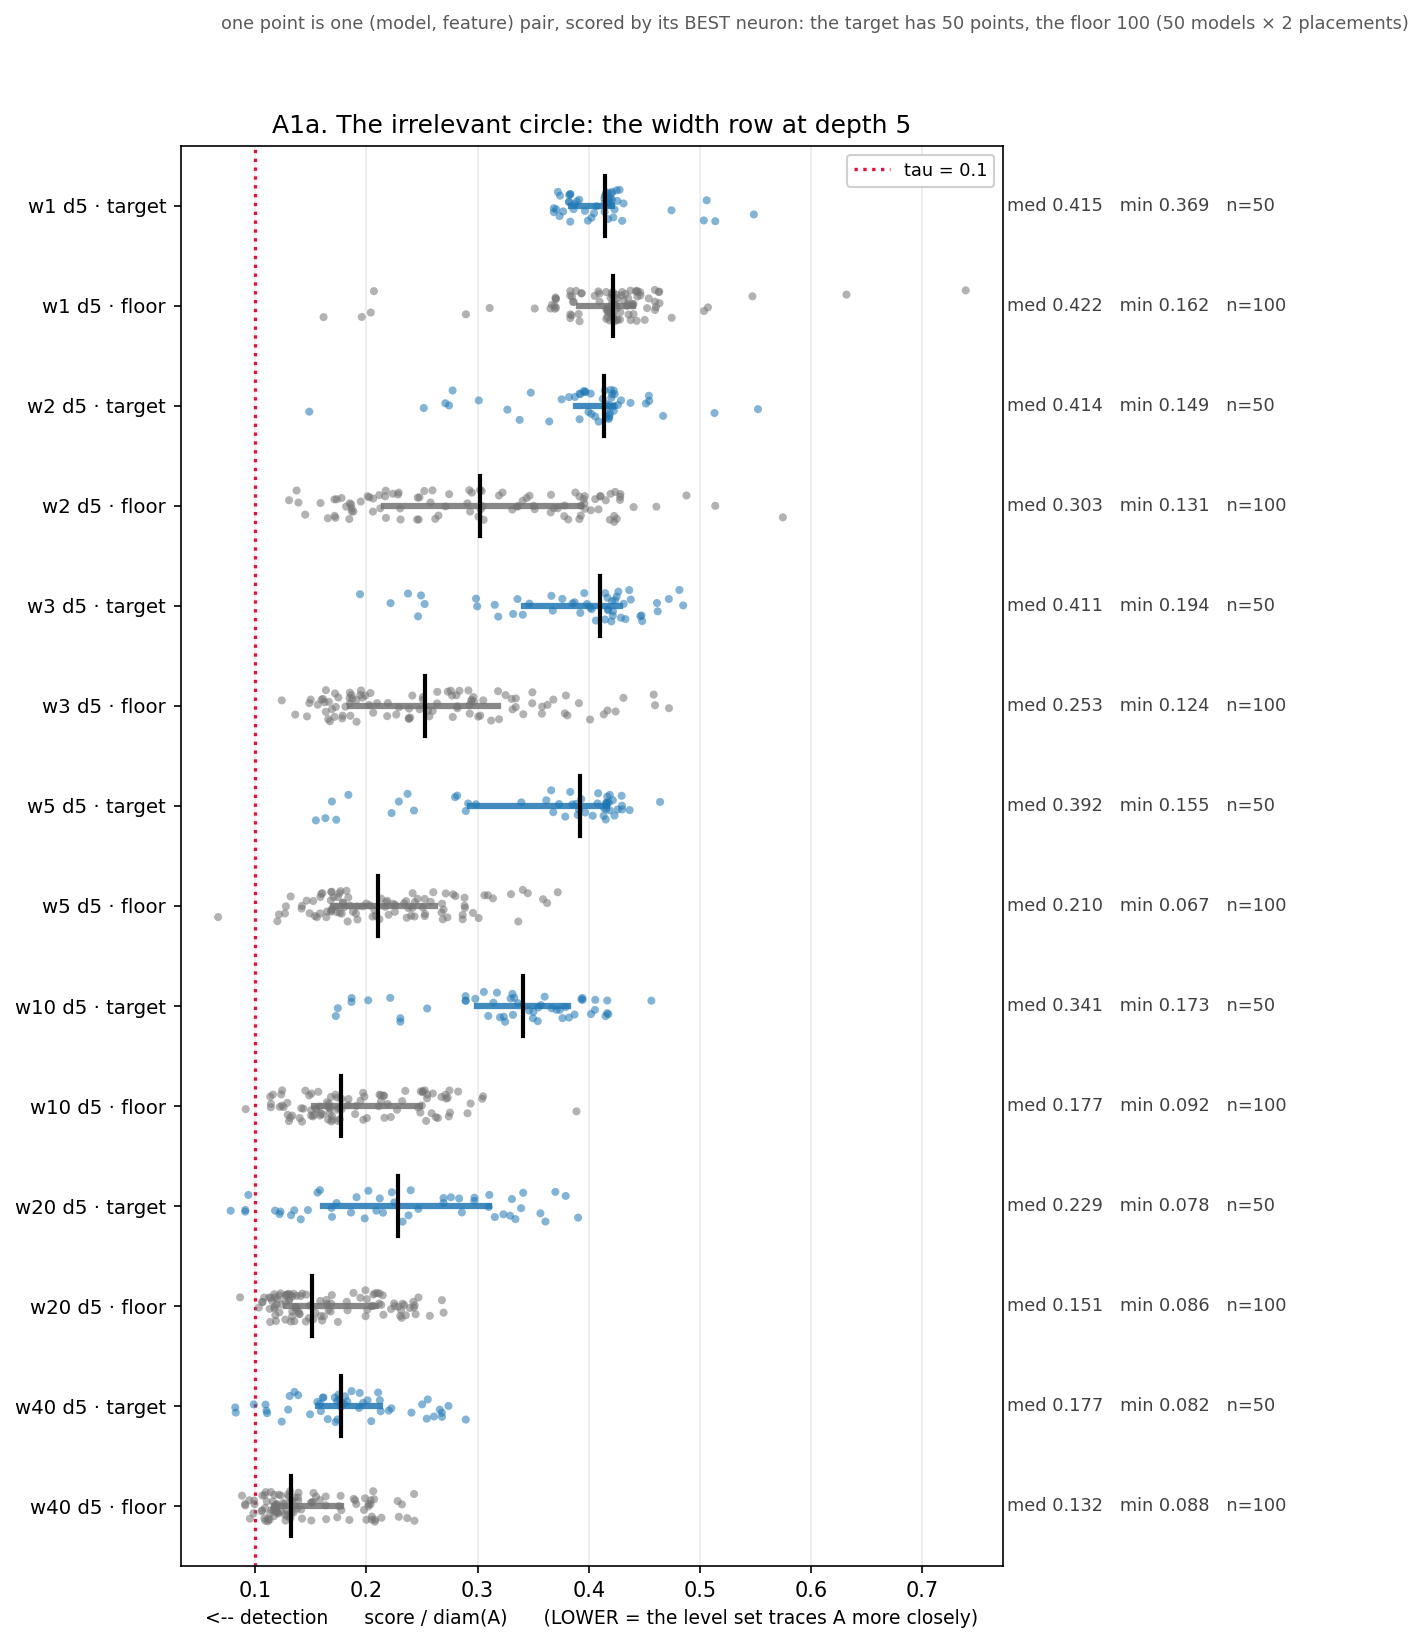

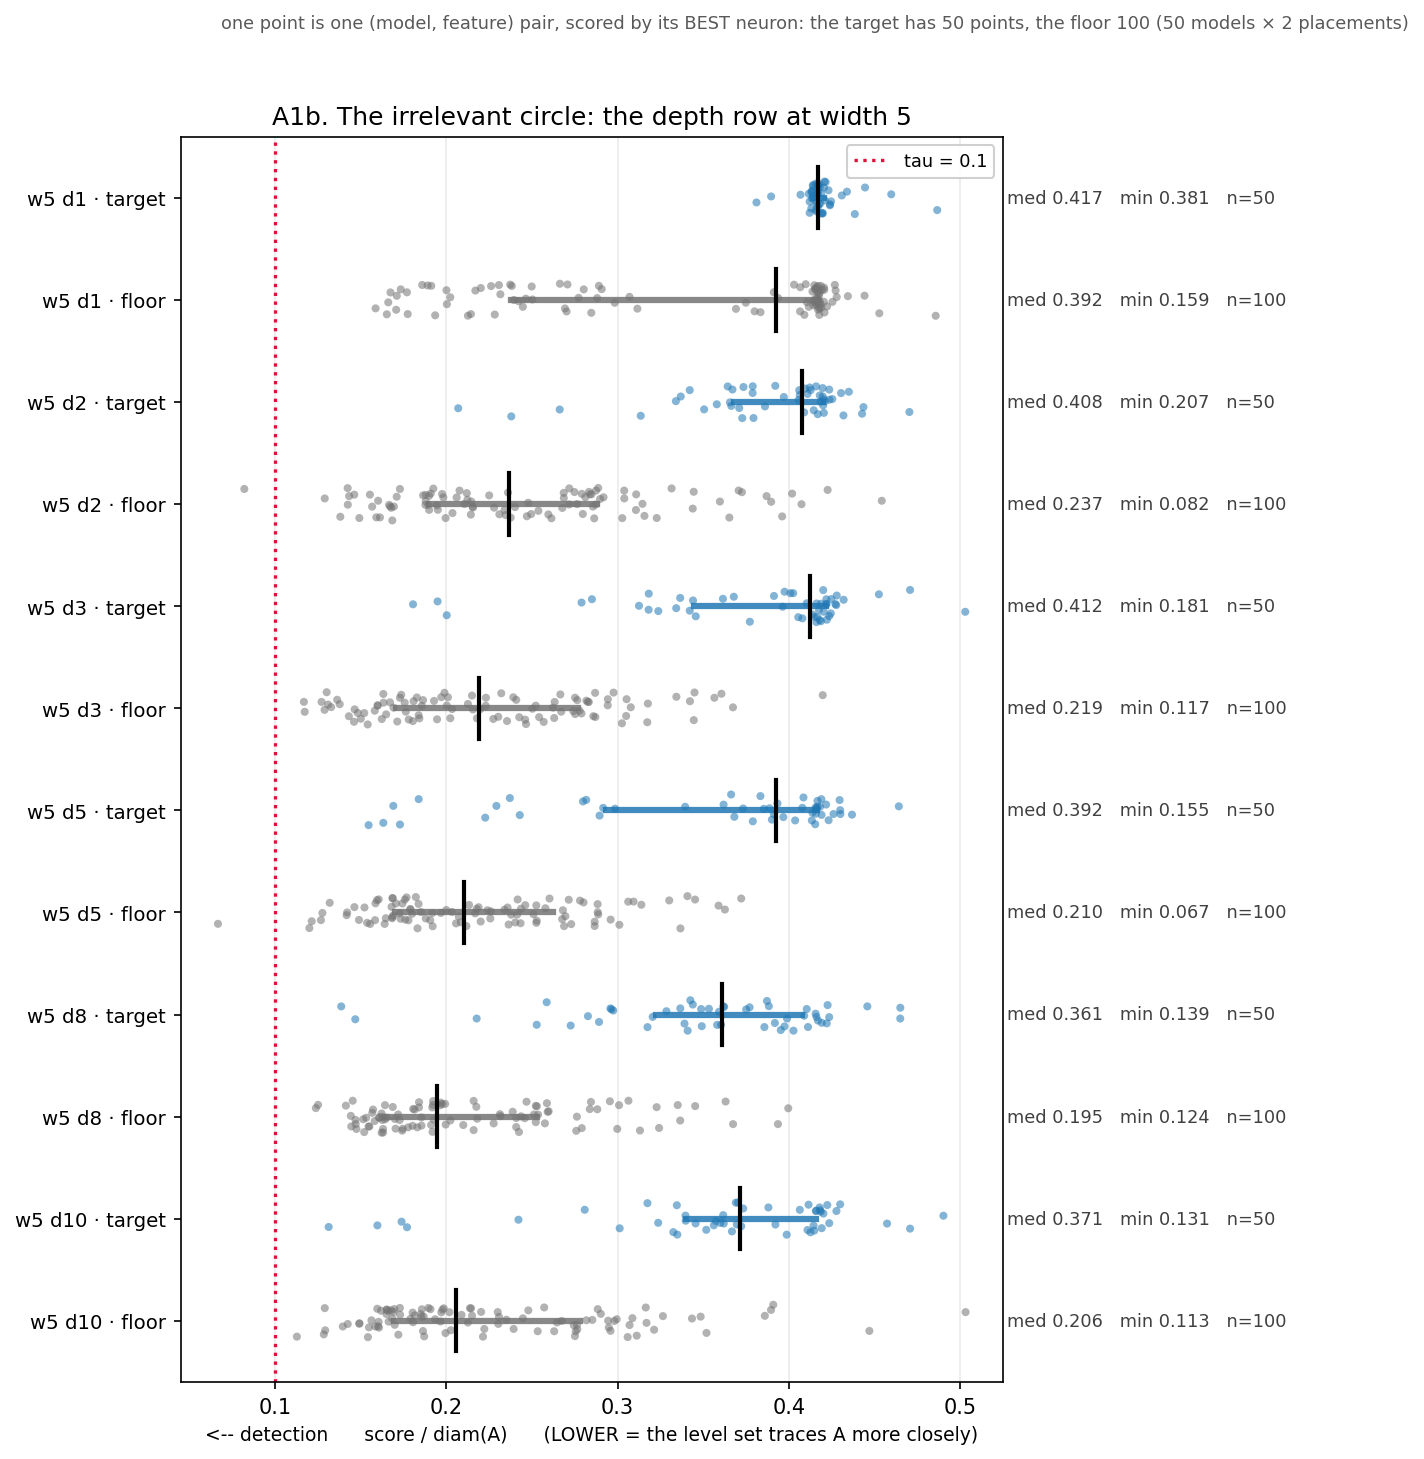

In [14]:
CAPTION = ("one point is one (model, feature) pair, scored by its BEST neuron: "
           "the target has 50 points, the floor 100 (50 models × 2 placements)")

def strips(dataset, axis, name, title):
    groups = []
    for w, d in axis:
        arch = f"w{w} d{d}"
        groups.append((f"{arch} · target", {"dataset": dataset, "arch": arch,
                                          "role": "target"}, "tab:blue"))
        groups.append((f"{arch} · floor", {"dataset": dataset, "arch": arch,
                                         "role": "null"}, "0.45"))
    plot_unit_strips(scores, "structural", groups, threshold=aw.TAU,
                     title=title, caption=CAPTION, save_path=FIG / name)
    show(FIG / name)

strips(IRR, W_ROW_I, "A1a_irrelevant_width.png",
       "A1a. The irrelevant circle: the width row at depth 5")
strips(IRR, D_ROW, "A1b_irrelevant_depth.png",
       "A1b. The irrelevant circle: the depth row at width 5")

### What A1 shows

**No cloud reaches the threshold.** All the blue medians stand at 0.23–0.41, that is, two to four times
above `τ`. Individual points do come close to the threshold: **seven** (model, feature) pairs out of eight
hundred end up below `τ` — four in `w20 d5` (0.078–0.094) and three in `w40 d5` (0.082–0.099). All seven
are examined separately in A4.

**But the null placements also come close to the threshold, and more often.** They have **twelve** units out
of one thousand six hundred below `τ`, and eight of the twelve are in the same `w40 d5`. Moreover, **the
lowest score on the whole irrelevant dataset belongs to a null, not to the target**: 0.0667 for a null
placement in `w5 d5` against 0.0780 for the best target one. Threshold crossings here are a property of
large ensembles in general, not a property of the circle.

**The blue lies to the right of the grey in all cells but one.** That is, a typical model describes the
irrelevant circle **worse** than the very same placement, specially chosen as a lower estimate. The
exception is `w1 d5`, the cell under the grey band, where no neuron can give a closed level curve; there two
ways of missing are compared, and the order between them is random.

**Both the target and the floor drift left as width grows.** This has to be noted at once, because from here
on all curves are read only as a pair: one cloud without the other means nothing.

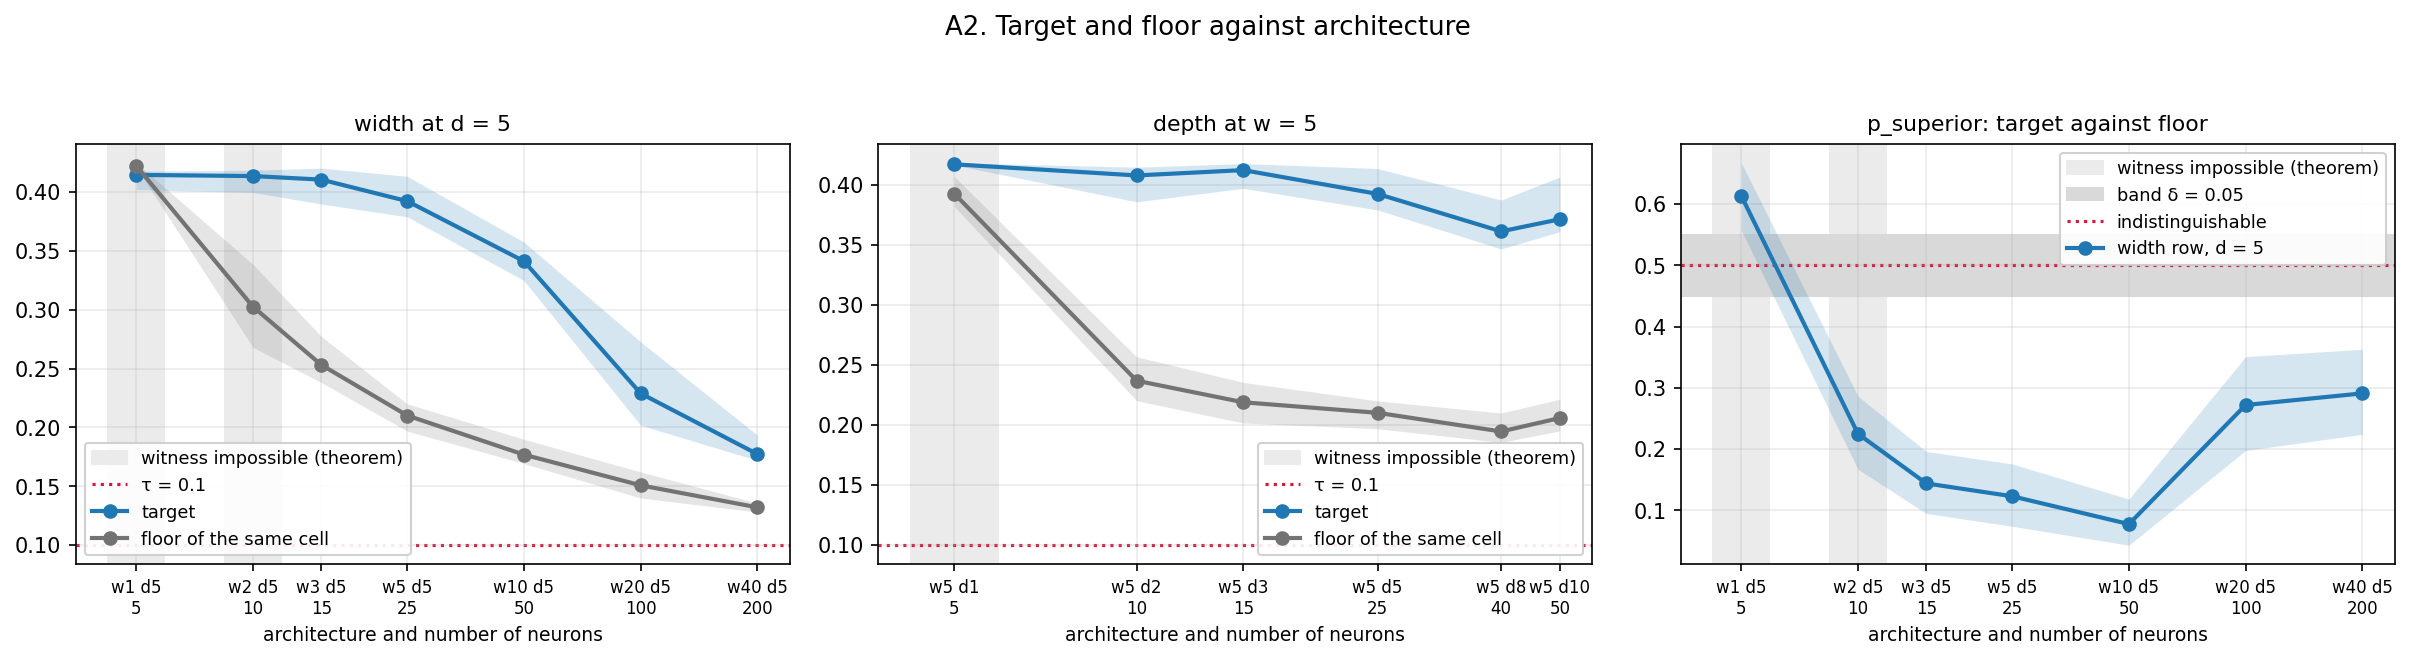

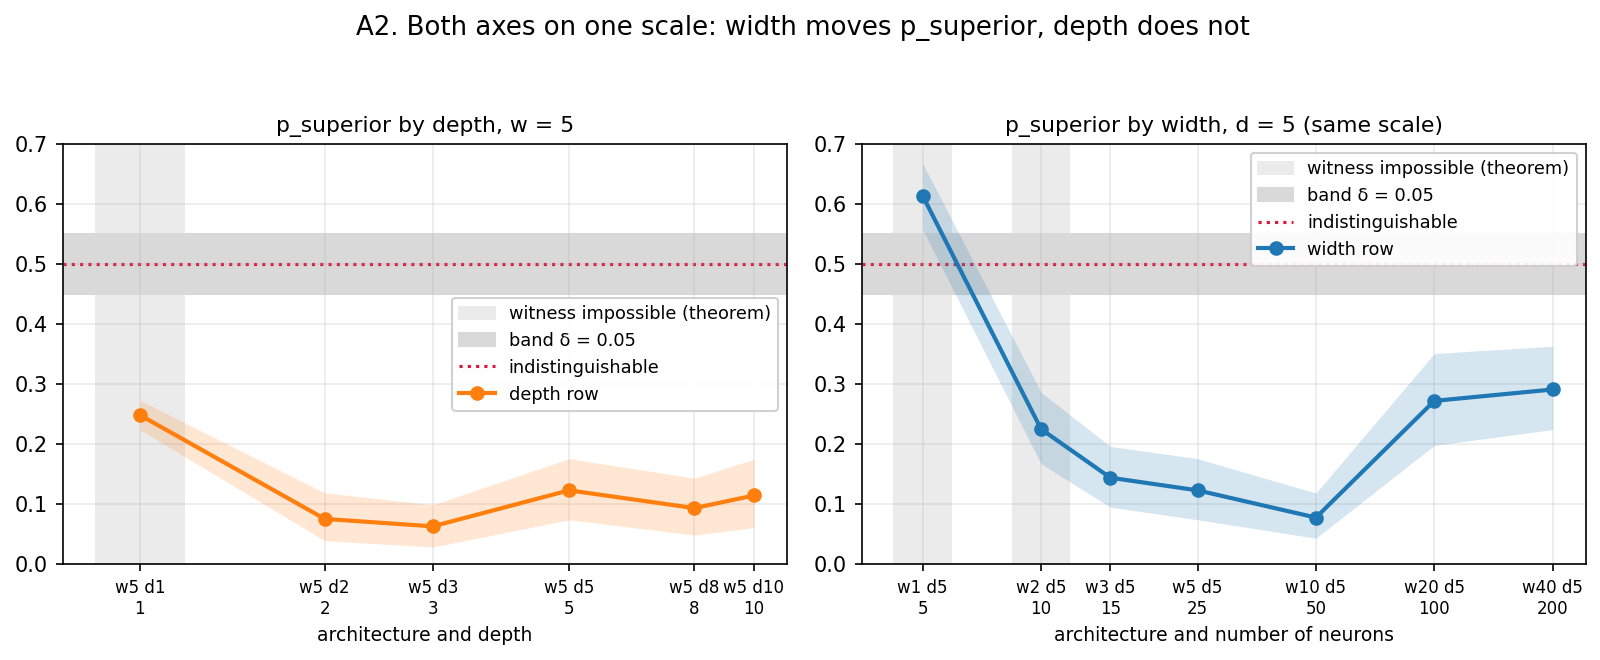

exponents measured on this pool (log-log):


  target by width: N^(-0.341) [-0.366, -0.302]; local slopes [-0.09, -0.2, -0.58, -0.37]


  floor by width: N^(-0.247) [-0.278, -0.218]; local slopes [-0.37, -0.25, -0.23, -0.19]


irrelevant · p_superior · width                      slope +0.1598 [+0.0881, +0.2303] per decade, zero inside: False


irrelevant · p_superior · depth                      slope +0.0601 [-0.0200, +0.1436] per decade, zero inside: True


In [15]:
ap.plot_axis_panels(cells, [
    dict(title="width at d = 5", dataset_type=IRR, cells=W_ROW_I,
         series=[("median_best", "target", "tab:blue"),
                 ("median_best_null", "floor of the same cell", "0.45")],
         hline=(aw.TAU, "τ = 0.1")),
    dict(title="depth at w = 5", dataset_type=IRR, cells=D_ROW,
         series=[("median_best", "target", "tab:blue"),
                 ("median_best_null", "floor of the same cell", "0.45")],
         hline=(aw.TAU, "τ = 0.1")),
    dict(title="p_superior: target against floor", dataset_type=IRR, cells=W_ROW_I,
         series=[("p_superior", "width row, d = 5", "tab:blue")],
         hline=(0.5, "indistinguishable"), band=(0.45, 0.55, "band δ = 0.05")),
], suptitle="A2. Target and floor against architecture",
   save_path=FIG / "A2a_irrelevant_axis.png")
show(FIG / "A2a_irrelevant_axis.png")

# p_superior by depth — in a separate panel, otherwise the axes do not line up.
ap.plot_axis_panels(cells, [
    dict(title="p_superior by depth, w = 5", dataset_type=IRR, cells=D_ROW,
         x="depth", series=[("p_superior", "depth row", "tab:orange")],
         hline=(0.5, "indistinguishable"), band=(0.45, 0.55, "band δ = 0.05"),
         ylim=(0.0, 0.7)),
    dict(title="p_superior by width, d = 5 (same scale)", dataset_type=IRR,
         cells=W_ROW_I, x="n_neurons",
         series=[("p_superior", "width row", "tab:blue")],
         hline=(0.5, "indistinguishable"), band=(0.45, 0.55, "band δ = 0.05"),
         ylim=(0.0, 0.7)),
], suptitle="A2. Both axes on one scale: width moves p_superior, depth does not",
   save_path=FIG / "A2b_irrelevant_p_superior.png")
show(FIG / "A2b_irrelevant_p_superior.png")

print("exponents measured on this pool (log-log):")
for st, name in (("median_best", "target"), ("median_best_null", "floor")):
    e = aw.loglog_exponent(df, W_ROW_R, IRR, st, n_boot=2000)
    print(f"  {name:5s} by width: N^({e['exponent']:+.3f}) "
          f"[{e['exponent_lo']:+.3f}, {e['exponent_hi']:+.3f}]; "
          f"local slopes {[round(v, 2) for v in e['local_slopes']]}")
for st, name in (("p_superior", "p_superior"),):
    for cs, ax_name in ((W_ROW_R, "width"), (D_ROW_CAP, "depth")):
        trend(cs, st, IRR, f"irrelevant · {st} · {ax_name}")

### What A2 shows

The left two panels are **the width row at `d = 5`**, the right ones **the depth row at `w = 5`**; they
cannot be compared with each other directly, because the number of neurons grows differently along them.

**Along width both curves fall — the target and the floor.** The median of the best for the target goes
0.41 → 0.18 from `w3` to `w40`, for the floor 0.25 → 0.13. The target meanwhile stays **above** the floor
all the time: the ratio along the row goes 1.62 → 1.87 → 1.93 → 1.52 → 1.34, i.e. it first grows and only
then shrinks. There is no uniform convergence, and this row is not described by a single curve.

**Along depth the floor practically does not move.** Along the depth row it goes 0.237 → 0.219 → 0.210 →
0.195 → 0.206 as the number of neurons grows from ten to fifty, whereas along the width row over the same
range it goes from 0.253 to 0.177. This difference matters, and it is worth coming back to, because it is
the only thing here that explains the fall itself.

> **Why the floor falls at all, and why along width and not along depth.** The floor is a minimum over the
> model's neurons, and it is natural to expect that the more neurons, the lower the minimum. But then depth
> should have worked in the same way, and it does not. The data distinguish these two axes directly: **at an
> equal number of neurons the floor is lower for the architecture that is wider.** At `N = 15` the floor is
> 0.253 for `w3 d5` and 0.219 for `w5 d3`; at `N = 50` it is 0.177 for `w10 d5` and 0.206 for `w5 d10`; on
> the equal-budget diagonal (`N ≈ 24`) it goes 0.198 → 0.211 → 0.210 → 0.246 from `w12 d2` to `w3 d8`. Three
> independent comparisons, and all in one direction.
>
> A plausible explanation: the neurons of **one** layer are parallel attempts, while the neurons of the next
> layer are not attempts but functions of the previous ones. A deep stack is not more attempts but a longer
> chain. The multiplicity that lowers the floor is therefore counted by the width of a layer, not by the
> total number of neurons. This is an interpretation; what has been checked is what stands before it — the
> asymmetry between the axes.
>
> **A practical consequence for the whole experiment:** "how much multiplicity alone would give" is
> estimated not by theory but by **the measured floor of the same cells**. This is exactly how it is done in
> B4.

**`p_superior` grows significantly** — from 0.144 at `w3 d5` to 0.272 at `w20 d5` and **0.291** at
`w40 d5`, a slope of +0.160 [+0.088, +0.230] per decade, zero outside the interval. It is more sensitive
than the median, because it sees the whole distribution, not one point. But the absolute level stays low:
at two hundred neurons the target is still **worse** than its own floor in two cases out of three.

**Along depth there is nothing:** the slope of `p_superior` is +0.060 [−0.020, +0.144], zero inside.

**There is no acceleration — and this is visible only because the row is taken up to `w40`.** The local
slopes of the target by segment go **−0.09, −0.20, −0.58, −0.37**: at the fourth step the fall did not
accelerate but slowed down. If the row stopped at `w20`, the first three numbers would read as an
accelerating fall, from which a crossing of `τ` somewhere outside the pool would follow; the fourth point
removes this reading. **There is no extrapolation to detection here.**

---

### A2b. One remark about the floor, and after that it is used as is

The floor here is low by construction: of the five placements of experiment 1 two are kept, and the
hardest one is excluded by the guideline. This is a **deliberate choice**: the set of null features is
chosen by hand, from considerations of covering the task, and the placements kept are those that give a low
score — then the floor works as a lower estimate and the verdict against it is only stricter.

Printed below is how the place of the soft null differs from the place of the target — three quantities
that are computed together with the score and lie in the same rows of the table. This is **a reference,
not a subject of study**: the question "how the score depends on how alive the field is at this place" is a
separate experiment, which is not in the plan, and it is not posed here.

In [16]:
diag = aw.placement_diagnostics(df, IRR, 20, 5)
diag.to_csv(AGG / "placement_diagnostics.csv", index=False)
print("simple_irrelevant, w20 d5 — medians over 5,000 neurons for each feature:")
display(diag.rename(columns={
    "feature_name": "feature", "role": "role", "grad_norm": "|∇f| on the feature",
    "value_std": "spread of f", "value_abs_mean": "|f|", "median_score": "median score",
    "n_rows": "rows"}).round(4))

d2 = aw.placement_diagnostics(df, REL, 20, 5)
print("\nfor comparison, simple_relevant w20 d5:")
display(d2.rename(columns={
    "feature_name": "feature", "role": "role", "grad_norm": "|∇f| on the feature",
    "value_std": "spread of f", "value_abs_mean": "|f|", "median_score": "median score",
    "n_rows": "rows"}).round(4))

simple_irrelevant, w20 d5 — medians over 5,000 neurons for each feature:


,feature,role,|∇f| on the feature,spread of f,|f|,median score,rows
0,null_far_right,null,0.0223,0.0160,0.8539,0.2529,5000
1,null_above_target,null,0.1131,0.1113,0.6361,0.3463,5000
2,irrelevant,target,0.1686,0.1505,0.6030,0.5518,5000



for comparison, simple_relevant w20 d5:


,feature,role,|∇f| on the feature,spread of f,|f|,median score,rows
0,relevant,target,0.4497,0.1538,0.3919,0.1824,5000
1,null_far_right,null,0.1026,0.0819,0.6779,0.2803,5000
2,null_above_target,null,0.1034,0.0828,0.6790,0.3693,5000


### What A2b shows

**The soft null sits in the saturated tail of the field.** On `simple_irrelevant` at `w20 d5`:

| feature | \|∇f\| on the feature | \|f\| | median score |
|---|---|---|---|
| `irrelevant` (target) | 0.169 | 0.60 | 0.552 |
| `null_above_target` | 0.113 | 0.64 | 0.346 |
| `null_far_right` | **0.022** | **0.85** | **0.253** |

At `far_right` the gradient is 7.6 times smaller than on the target, and the absolute value is close to one
— `tanh` is saturated there and the field is almost flat. This is exactly the mechanism by which a low score
is obtained, and at the same time the reason why such a null gives precisely a **lower** estimate. That is
exactly why it was chosen.

**What follows from this and what does not.**

* **Follows:** the floor of 0.15–0.25 is a lower estimate of the score of an irrelevant feature in this
  task, and the target (0.18–0.41) lies above it. This is exactly what should be said.
* **Does not follow:** that the score distributions on null features and on irrelevant features differ. We
  ourselves kept the nulls that give a low score.
* **Does not follow:** that the network "suppresses" the irrelevant circle.

**The verdict of part A does not depend on this:** it rests on the threshold, not on the ordering. Neither
the target nor the floor crosses `τ` systematically, and for the target it is 0 of 16,050 rows in fourteen
cells of sixteen.

From here on the floor is used as is. How to choose null features in general — how many of them are needed,
how to measure their diversity and how much the resulting estimate is biased low — is the question of a
separate experiment, which is not in the plan; here a manual choice from considerations of covering the task
is adopted, and that is enough.

---

### A3. The shape of the distribution, not only the summary

A median is one number; it does not say whether the distribution has a tail reaching to the threshold. So
here, for each cell of the width row, the full distribution of the score **over all neurons** is drawn
(a pale histogram, normalised to the size of the population) together with **the median of the best per
unit** (a thick vertical line) — the only one of the two on which a verdict may rest.

Seven panels in a row, one per cell: they are about one and the same thing, and the question is precisely
how the shape changes along the axis. The first two are theorem cells; they are here as the reference for
"no structure at all".

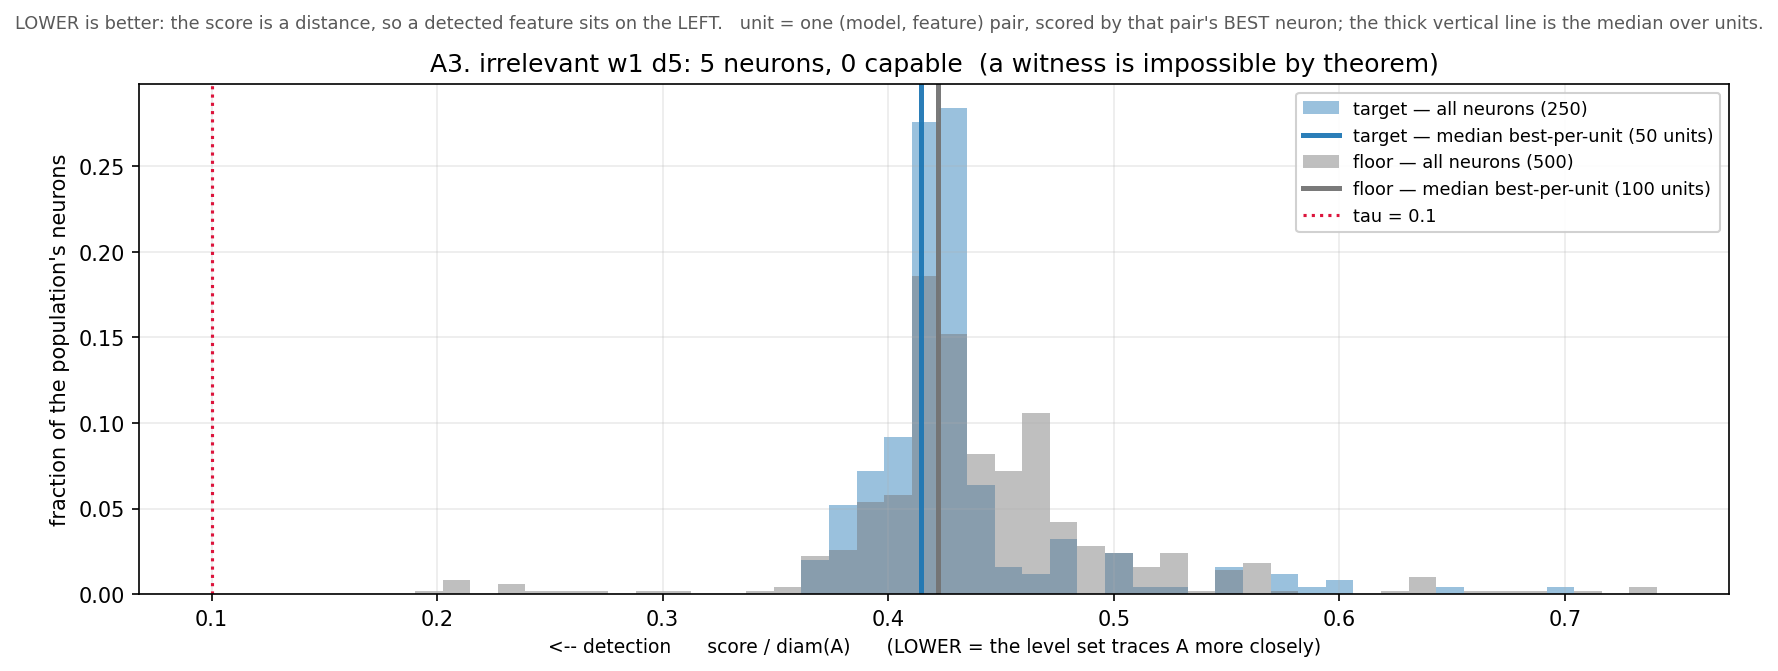

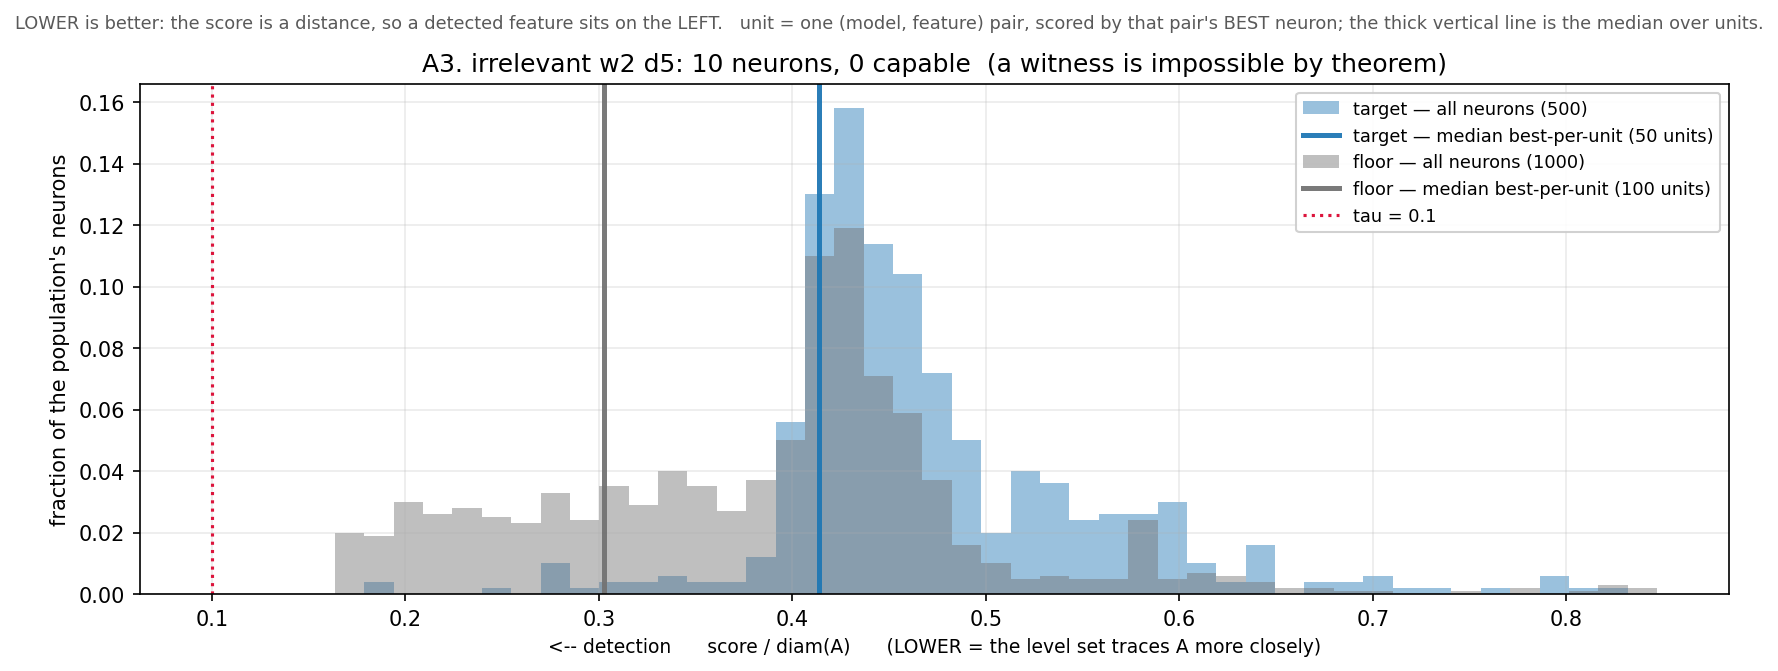

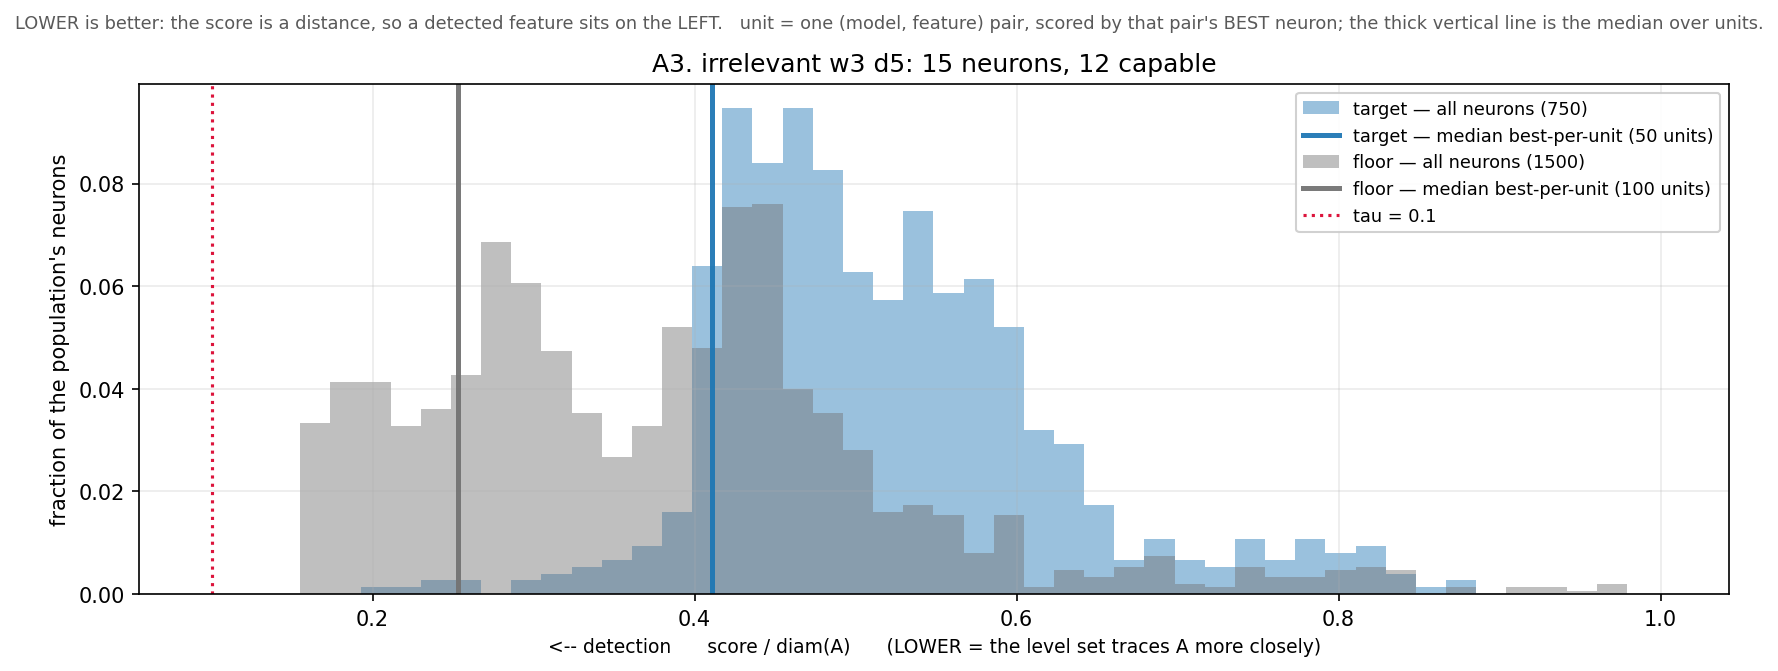

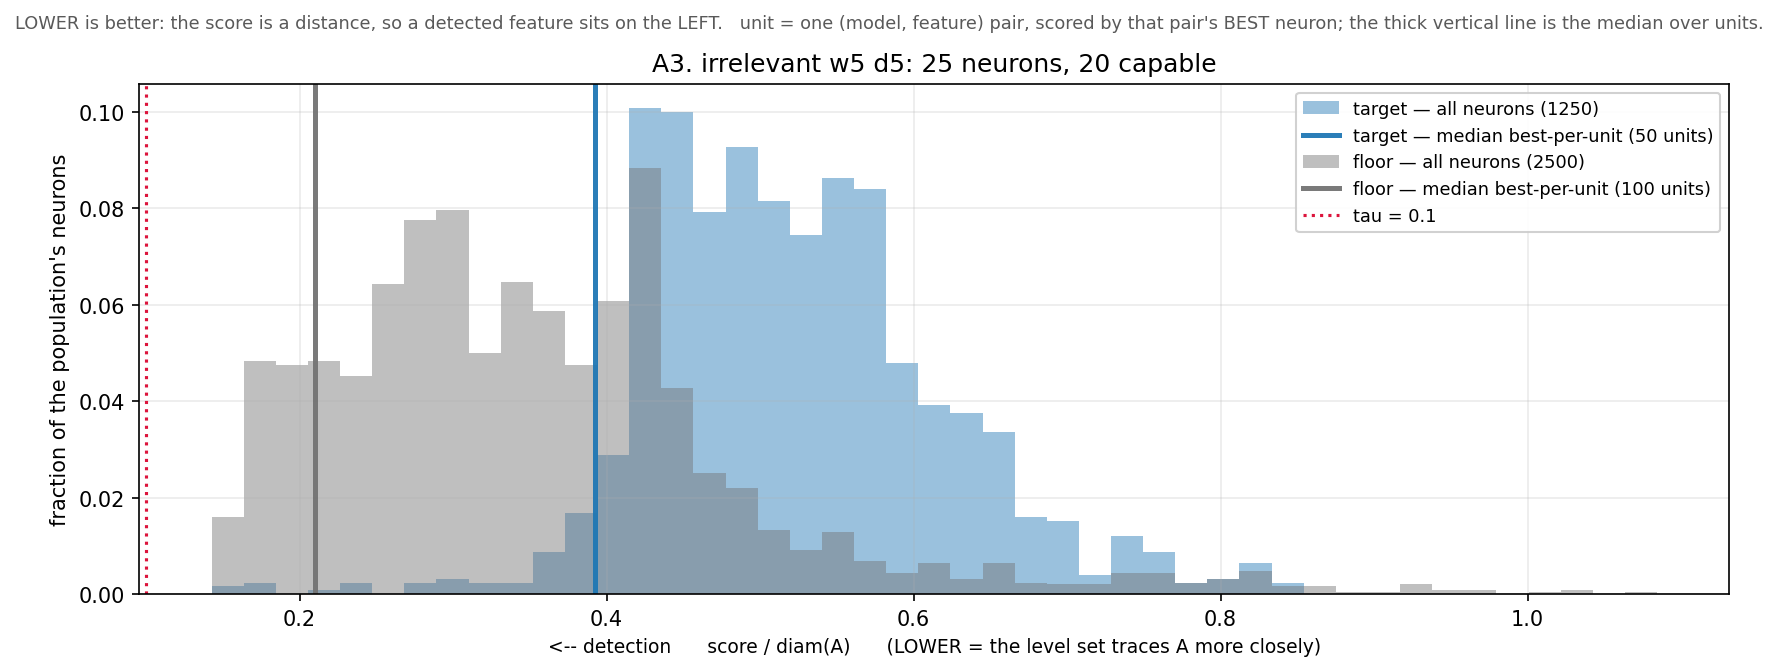

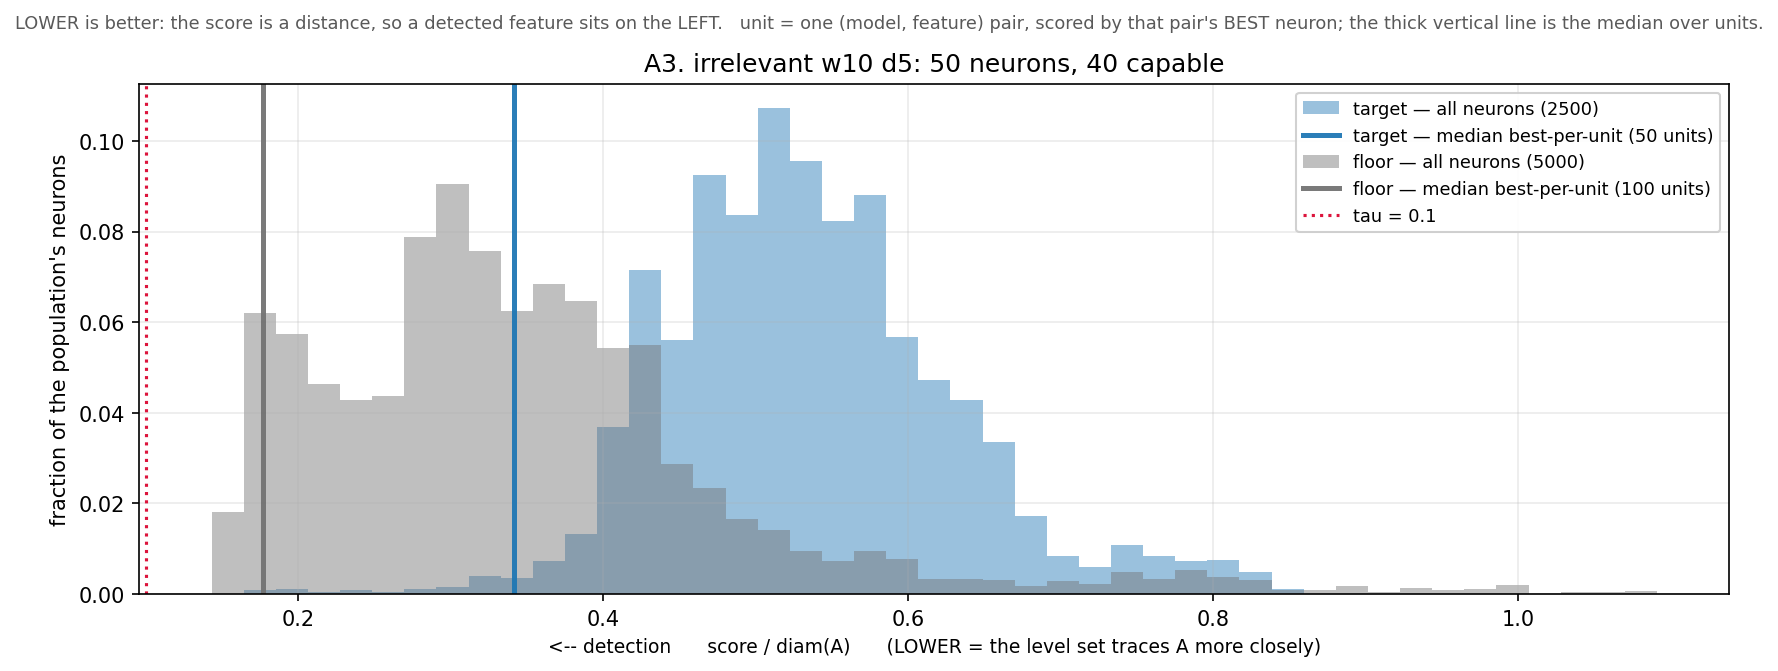

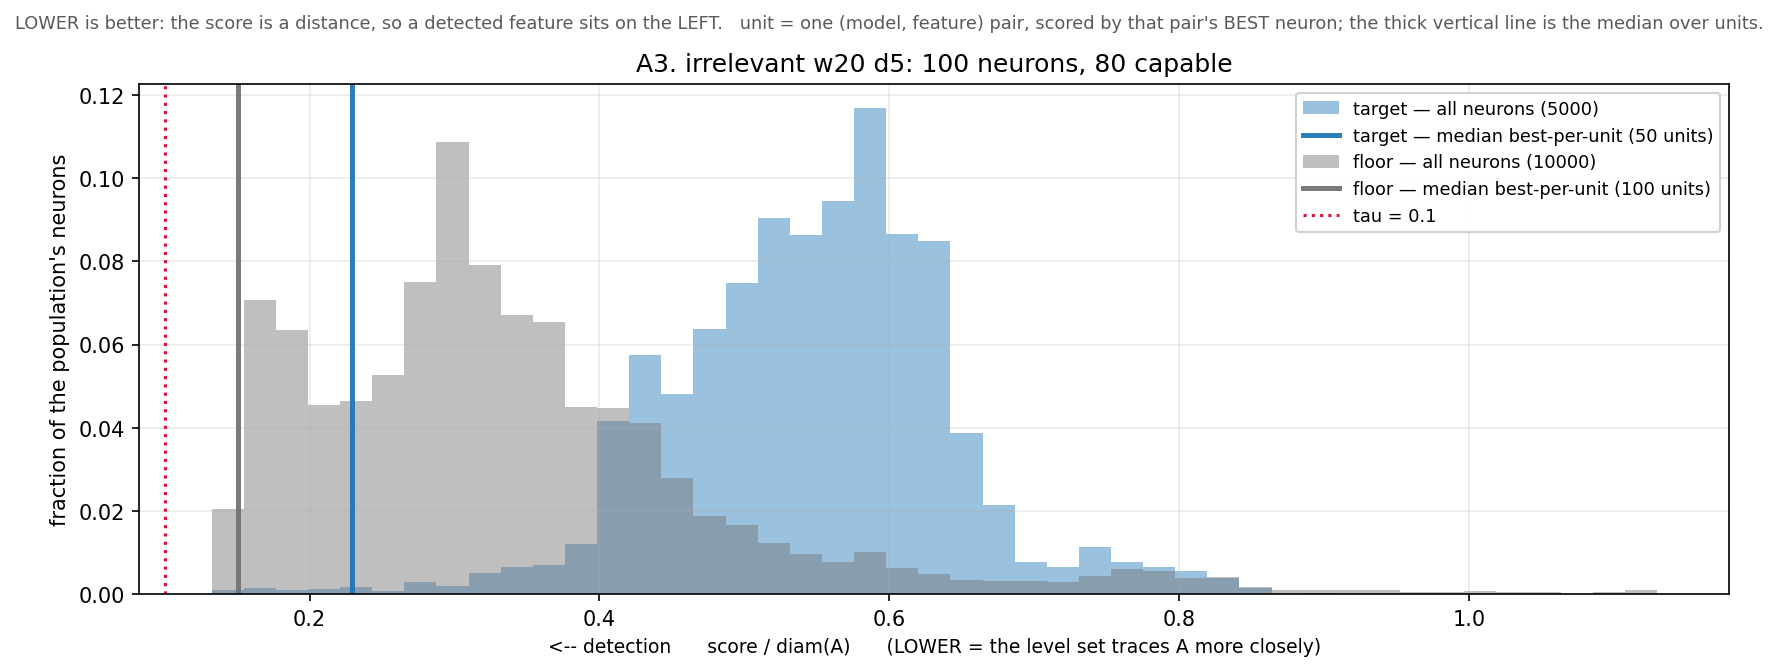

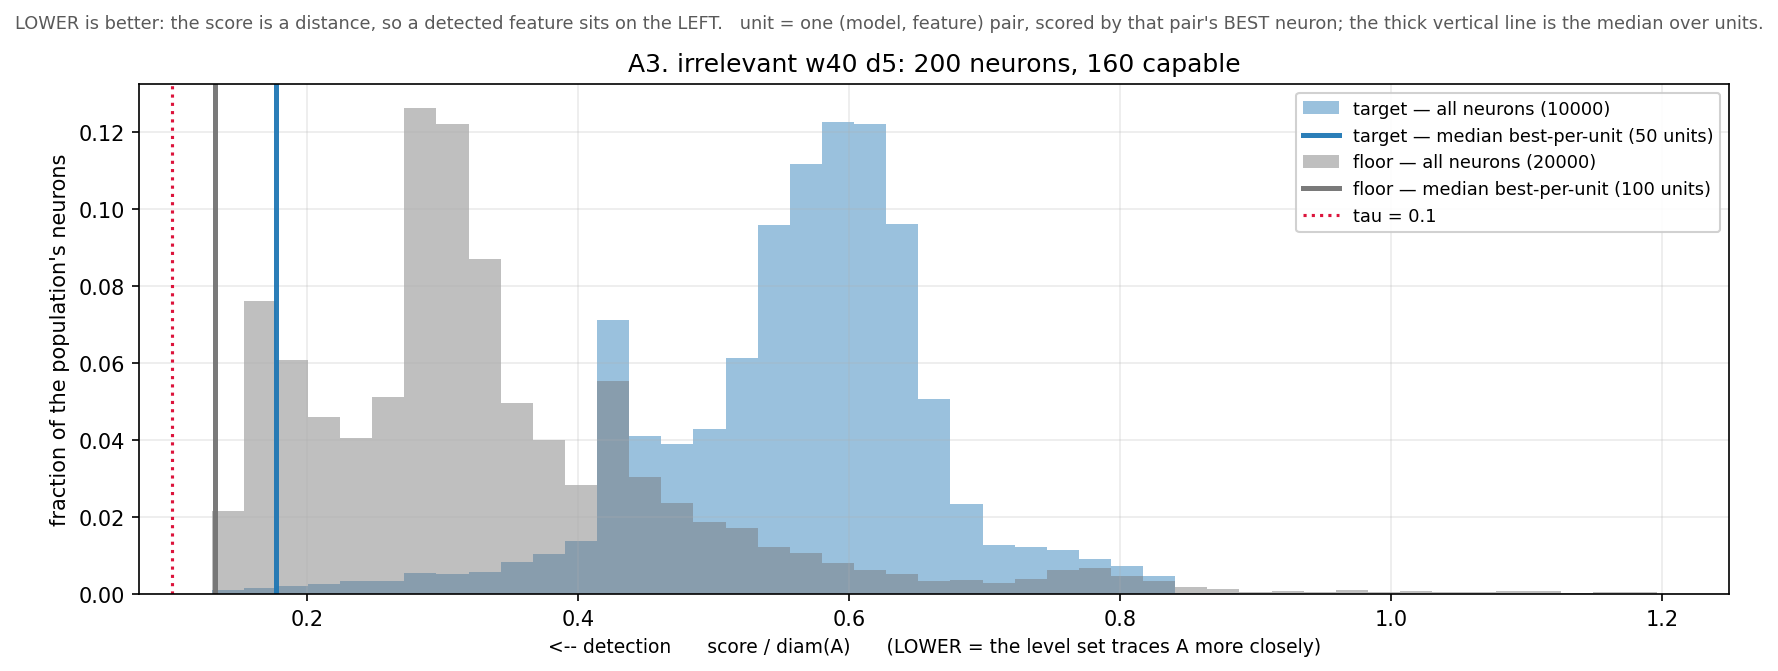

In [17]:
for w, d in W_ROW_I:
    arch = f"w{w} d{d}"
    name = f"A3_irrelevant_{arch.replace(' ', '')}.png"
    n_cap = int(cells[(cells.dataset_type == IRR) & (cells.arch == arch)].n_capable.iat[0])
    mark = "" if n_cap else "  (a witness is impossible by theorem)"
    plot_populations(scores, "structural", [
        ("target", {"dataset": IRR, "arch": arch, "role": "target"}, "tab:blue"),
        ("floor", {"dataset": IRR, "arch": arch, "role": "null"}, "0.45")],
        threshold=aw.TAU, save_path=FIG / name,
        title=f"A3. irrelevant {arch}: {w * d} neurons, {n_cap} capable{mark}")
    show(FIG / name)

### What A3 shows

**The separation of the distributions holds at all widths.** At `w1 d5` the blue and the grey almost
coincide — as expected, there neither population can single anything out. From `w3` on the blue moves to the
right of the grey and stays there: a typical neuron describes the irrelevant circle **worse** than the very
same placement specially chosen as a lower estimate for the null features. This is a comparison with a lower
bound, not with an arbitrary alternative.

**A tail appears in the two widest cells.** At `w20 d5` the left edge of the blue distribution for the first
time reaches the region of the threshold, at `w40 d5` likewise. These are those **seven** neurons — four and
three — and the only way to understand what they are is to look at them.

---

### A4. What exactly the criterion matched for these seven

A number cannot tell a closed level curve going around the circle from a piece of a curve that happened to
lie nearby. So here we draw what the criterion actually matched — `return_best_component_points` — over the
neuron's field, with the feature `A` on top.

The component is drawn **wide and underneath**, the feature — thin and on top: a match reads as a green halo
around a black curve, and a mismatch as pure green or pure black.

For each panel one more quantity is computed: **the `H_1` persistence of the component itself**, normalised by
`diam(A)`. It answers the question "is there a hole at all, and of what size" independently of how close the
component is to `A`.

The bottom panels are controls: **the best null neuron of the whole irrelevant dataset** (it scores lower than
any target neuron anywhere), a typical neuron of `w20 d5` and, for contrast, witnesses of the relevant circle
at the very same `τ`.

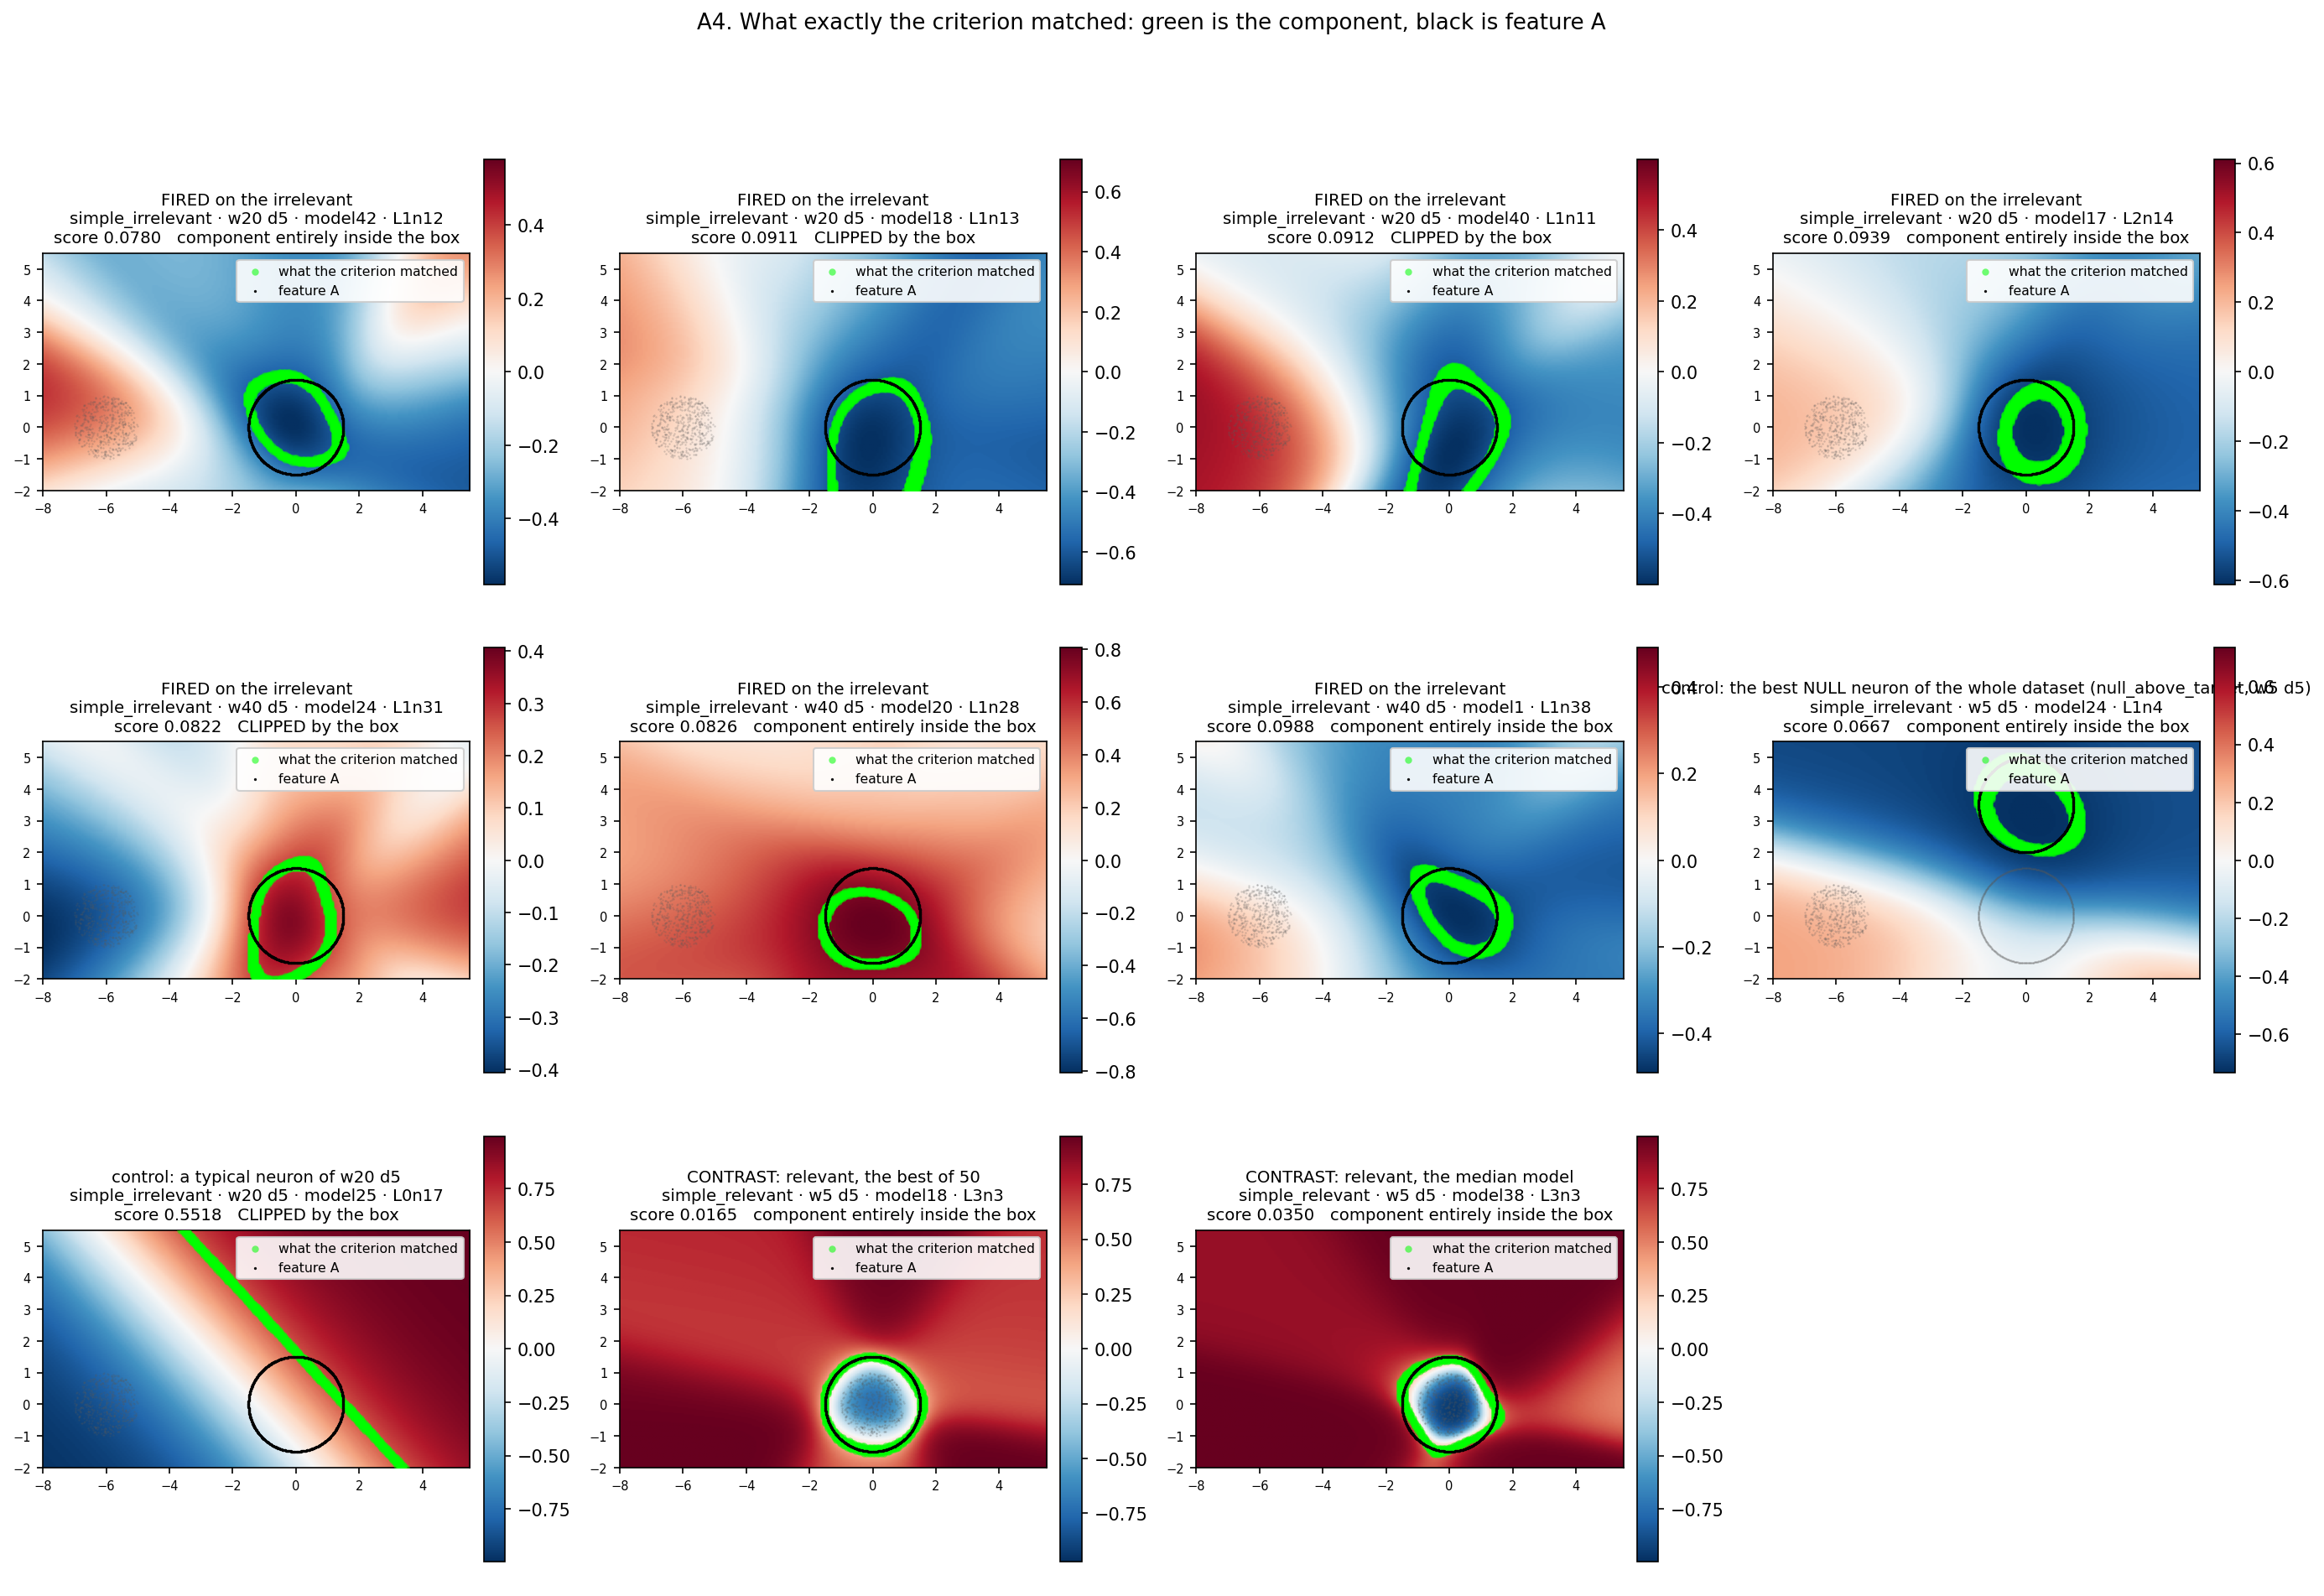

In [18]:
A_irr = aw.feature_points_for(IRR, "irrelevant")
A_rel = aw.feature_points_for(REL, "relevant")

irr = df[df.dataset_type == IRR]
fired = irr[(irr.feature_role == "target") & irr.witness].sort_values(["hidden_dim", "score"])
fired.to_csv(AGG / "irrelevant_witnesses.csv", index=False)
cell20 = irr[(irr.hidden_dim == 20) & (irr.n_layers == 5)]

# A component that runs into the edge of the box is clipped: both its score and
# any of its topology are about the box, not about the network. This has to be
# visible on the label.
(bx0, bx1), (by0, by1) = ES.bounds
STEP = max(bx1 - bx0, by1 - by0) / (ES.resolution - 1)

def clipped(component):
    K = np.asarray(component)
    return int((((np.abs(K[:, 0] - bx0) < 1.5 * STEP) | (np.abs(K[:, 0] - bx1) < 1.5 * STEP)
                 | (np.abs(K[:, 1] - by0) < 1.5 * STEP) | (np.abs(K[:, 1] - by1) < 1.5 * STEP))).sum())

def panel(row, feature_points, tag, dataset):
    it = aw.neuron_field_and_component(row.model_path, int(row.layer_id),
                                       int(row.coord_id), feature_points, ES)
    n_edge = clipped(it["component_points"])
    arch = f"w{int(row.hidden_dim)} d{int(row.n_layers)}"
    model = Path(row.model_path).name.split("_")[-1]
    it["label"] = (f"{tag}\n{dataset} · {arch} · {model} · L{row.layer_id}n{row.coord_id}\n"
                   f"score {it['score']:.4f}   "
                   f"{'CLIPPED by the box' if n_edge else 'component entirely inside the box'}")
    it["data_points"] = aw.dataset_points(dataset)
    return it

items = [panel(r, A_irr, "FIRED on the irrelevant", IRR) for r in fired.itertuples()]

# A stronger control than the former "best null of this cell": the best null
# neuron of the WHOLE irrelevant dataset scores lower than any target one.
best_null = irr[irr.feature_role == "null"].nsmallest(1, "score").iloc[0]
items.append(panel(best_null, aw.feature_points_for(IRR, best_null.feature_name, ES),
                   f"control: the best NULL neuron of the whole dataset "
                   f"({best_null.feature_name}, w{int(best_null.hidden_dim)} "
                   f"d{int(best_null.n_layers)})", IRR))

target20 = cell20[cell20.feature_role == "target"].sort_values("score")
items.append(panel(target20.iloc[len(target20) // 2],
                   A_irr, "control: a typical neuron of w20 d5", IRR))

ref = df[(df.dataset_type == REL) & (df.model_name == "tanh_w5_d5_mass-train")
         & (df.feature_role == "target")]
per_model = ref.groupby("model_path").score.min().sort_values()
median_model = per_model.index[len(per_model) // 2]
items.append(panel(ref.nsmallest(1, "score").iloc[0],
                   A_rel, "CONTRAST: relevant, the best of 50", REL))
items.append(panel(ref[ref.model_path == median_model].nsmallest(1, "score").iloc[0],
                   A_rel, "CONTRAST: relevant, the median model", REL))

ap.plot_neuron_fields(items, ncols=4, save_path=FIG / "A4_irrelevant_fired_fields.png",
    title="A4. What exactly the criterion matched: green is the component, black is feature A")
show(FIG / "A4_irrelevant_fired_fields.png")

### What A4 shows

**Three components of seven are clipped by the box.** At `w20 d5` these are `L1n13` (0.0911) and `L1n11`
(0.0912), at `w40 d5` — `L1n31` (0.0822): part of the component's points lie on the edge of the evaluation
window, the level curve runs out of the box and inside it is seen as an arc. For such components **both the
score and any of their geometry are about the box, not about the network**: the criterion compares `A` with a
truncated set.

**The remaining four look like honest firings.** `L1n12` (0.0780) and `L2n14` (0.0939) at `w20 d5`,
`L1n28` (0.0826) and `L1n38` (0.0988) at `w40 d5` — closed level curves going around the circle with an
offset, but going around it. By their look this is not an artefact: the criterion fired on what it is
supposed to fire on.

Hence the precise statement of the result: **on the two widest architectures four models out of a hundred
give a plausible witness of the irrelevant circle**, and three more firings are unreliable because of the
clipping. Whether this is enough to speak of a rate is decided in A6 — by a rule announced in advance, not
by eye.

**And right away a control that answers almost at once.** The best NULL neuron of the whole irrelevant
dataset scores **0.0667** — less than any of the seven — and its component is entirely inside the box and
honestly goes around its placement. That is, **the most convincing firing on this dataset belongs to a
feature that the task did not mention at all.** It is the same range of values and the same quality of
going around, not something worse.

**The contrast with the relevant circle at the same `τ`** is qualitative, not quantitative: there the
component is a dense closed ring hugging `A`, with a score of 0.017–0.035.

**Why 0.09 passes the threshold at all.** `geometry.max_chamfer_distance` is the maximum over the two
directions of the **mean** nearest-neighbour distances, not of the maximal ones. Averaging makes the
criterion robust to holes in the grid, but right at the threshold it means that 0.09 is the region of loose
encirclements.

---

### A5. A second criterion, independent of the first

The homological criterion asks something else: does the FIELD have a loop of the required dimension,
without reference to where `A` stands. That is exactly why its agreement with the structural verdict is
evidence, not bookkeeping.

**We look at the score, not at the fraction.** The fraction that fired on `simple_irrelevant` is 52 neurons
out of 31,050, and comparing fractions to four decimals is meaningless. The informative quantity is the
`persistence_margin` itself, taken as **the best per model** (for it higher = better, unlike the structural
score). `NaN` means "no bar of the required dimension was found at all" and does not enter the maximum; how
many such there are is printed separately.

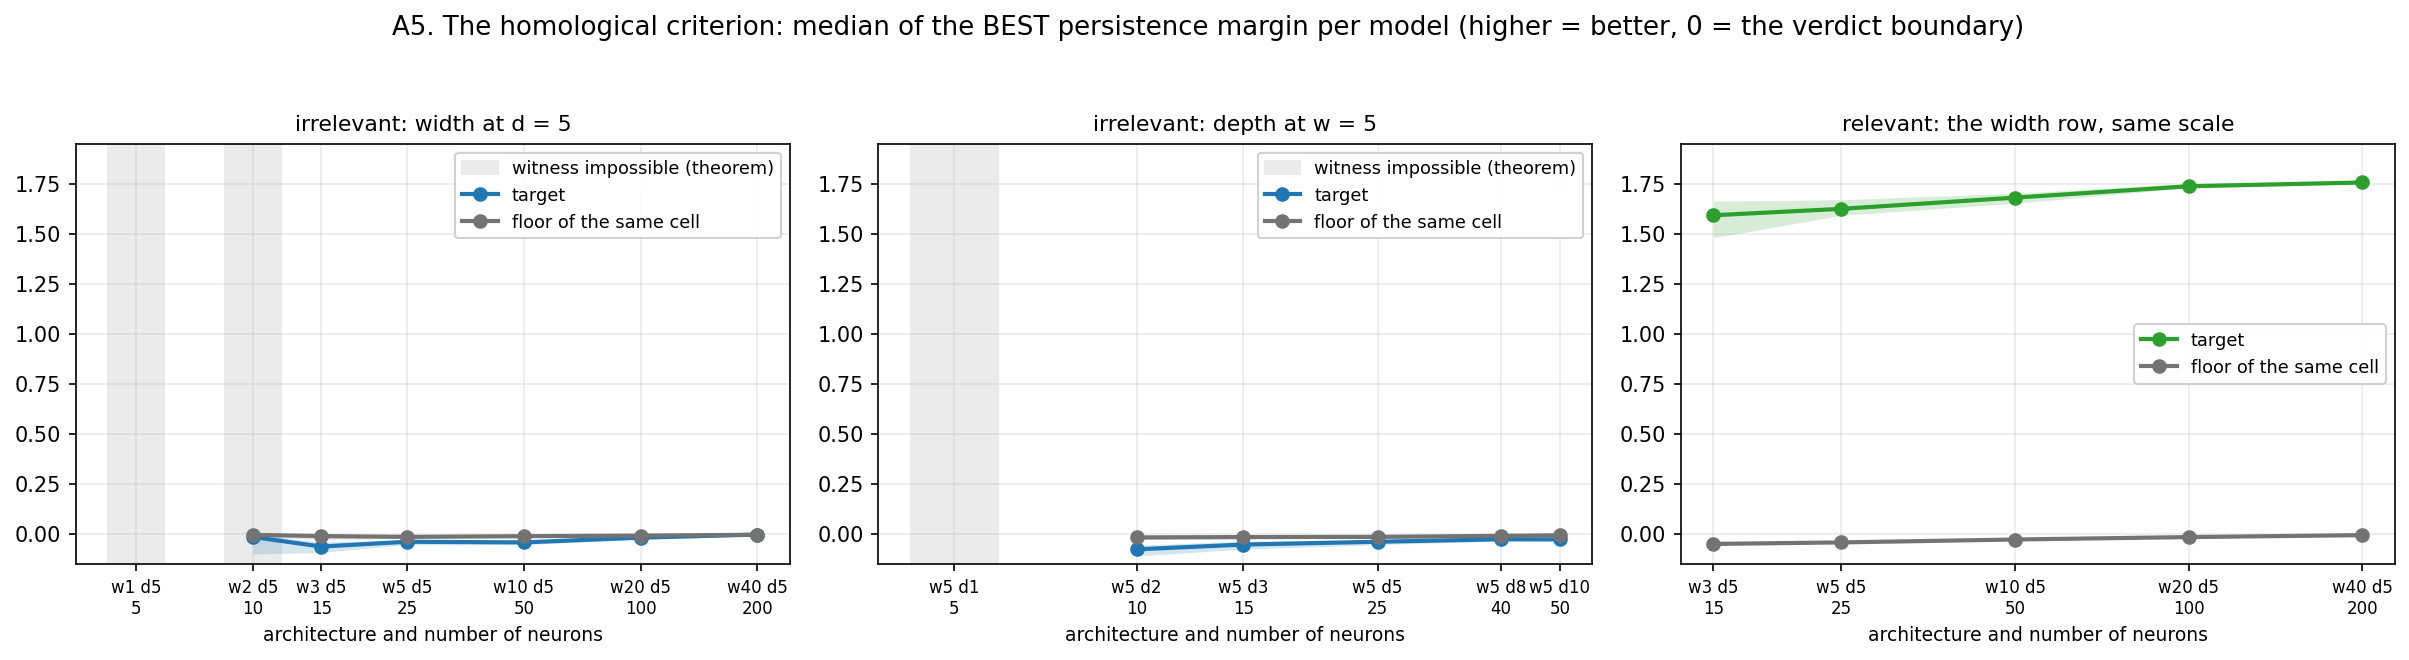

  irrelevant  target  (w20 d5): no bar for 86.4% of neurons; the verdict fired for 16 of 5000
  irrelevant  null    (w20 d5): no bar for 90.5% of neurons; the verdict fired for 29 of 10000
  relevant    target  (w20 d5): no bar for 35.4% of neurons; the verdict fired for 2693 of 5000
  relevant    null    (w20 d5): no bar for 75.1% of neurons; the verdict fired for 18 of 10000
in total over all cells irrelevant : the homological verdict for 52 neurons of 31050
in total over all cells relevant   : the homological verdict for 15048 neurons of 30300


In [19]:
YL = (-0.15, 1.95)
ap.plot_axis_panels(cells, [
    dict(title="irrelevant: width at d = 5", dataset_type=IRR, cells=W_ROW_I,
         series=[("hom_median_best", "target", "tab:blue"),
                 ("hom_median_best_null", "floor of the same cell", "0.45")], ylim=YL),
    dict(title="irrelevant: depth at w = 5", dataset_type=IRR, cells=D_ROW,
         series=[("hom_median_best", "target", "tab:blue"),
                 ("hom_median_best_null", "floor of the same cell", "0.45")], ylim=YL),
    dict(title="relevant: the width row, same scale", dataset_type=REL, cells=W_ROW_R,
         series=[("hom_median_best", "target", "tab:green"),
                 ("hom_median_best_null", "floor of the same cell", "0.45")], ylim=YL),
], suptitle="A5. The homological criterion: median of the BEST persistence margin per model "
            "(higher = better, 0 = the verdict boundary)",
   save_path=FIG / "A5_homological.png")
show(FIG / "A5_homological.png")

for ds, name in ((IRR, "irrelevant"), (REL, "relevant")):
    g = df[(df.dataset_type == ds) & (df.hidden_dim == 20) & (df.n_layers == 5)]
    for role in ("target", "null"):
        b = g[g.feature_role == role]
        nan = b.homological_persistence_margin.isna().mean()
        k, n = int(b.hom_witness.sum()), len(b)
        print(f"  {name:11s} {role:7s} (w20 d5): no bar for {nan:5.1%} of neurons; "
              f"the verdict fired for {k} of {n}")
for ds, name in ((IRR, "irrelevant"), (REL, "relevant")):
    tot = df[(df.dataset_type == ds) & (df.feature_role == "target")]
    print(f"in total over all cells {name:11s}: the homological verdict for "
          f"{int(tot.hom_witness.fillna(False).sum())} neurons of {len(tot)}")

### What A5 shows

**Separation by score, not by fraction — by two orders of magnitude and with a change of sign.** The best
`persistence_margin` per model: on `simple_relevant` the median is **+1.74** with the floor at −0.014, on
`simple_irrelevant` **−0.017** with the floor at −0.007. A negative margin means that the bar of the required
dimension did not survive the check; that is, on the irrelevant target the second criterion, built in a
completely different way, comes to the same verdict as the first.

**In counts this is 52 neurons out of 31,050** over all `irrelevant` cells — against 15,048 out of 30,300 on
`relevant`. It is the count, not a fraction to four decimals, that is worth keeping in mind.

**Does the target's margin grow with width** on `irrelevant` — yes, from −0.075 to −0.017, i.e. the target
creeps up to the verdict boundary. But the floor does exactly the same (−0.016 → −0.007), and both stay
negative.

---

### A6. The formal verdict on existence

What remains is to check the only cell with a signal. The rule is announced in advance: an excess over the
floor is considered established only if the exact binomial interval of the fraction of models with a witness
does not overlap the interval of the same quantity for the floor in the same cell.

In [20]:
from scipy.stats import beta

def clopper_pearson(k, n, alpha=0.05):
    lo = 0.0 if k == 0 else float(beta.ppf(alpha, k, n - k + 1))
    hi = 1.0 if k == n else float(beta.ppf(1 - alpha, k + 1, n - k))
    return lo, hi

rows = []
for r in cells[cells.dataset_type == IRR].itertuples():
    k = int(round(r.p_has_witness * r.n_models))
    lo, hi = clopper_pearson(k, r.n_models)
    g = df[(df.dataset_type == IRR) & (df.hidden_dim == r.width)
           & (df.n_layers == r.depth) & (df.feature_role == "null")]
    unit = g.groupby(["model_path", "feature_name"]).witness.any()
    lo_n, hi_n = clopper_pearson(int(unit.sum()), len(unit))
    rows.append({"arch": r.arch, "target": f"{k}/{r.n_models}",
                 "target interval": f"[{lo:.3f}, {hi:.3f}]",
                 "floor": f"{int(unit.sum())}/{len(unit)}",
                 "floor interval": f"[{lo_n:.3f}, {hi_n:.3f}]",
                 "excess established": lo > hi_n})
existence = pd.DataFrame(rows)
existence.to_csv(AGG / "irrelevant_existence.csv", index=False)

signal = existence[existence["target"] != "0/50"]
print(f"cells with a non-zero rate: {len(signal)} of {len(existence)}; "
      f"in the other {len(existence) - len(signal)} — exactly 0/50")
display(signal)

DELTA = 0.05
eq = pd.DataFrame([
    {"arch": r.arch, "p_superior": round(r.p_superior, 4),
     "interval": f"[{r.p_superior_lo:.3f}, {r.p_superior_hi:.3f}]",
     "equal to 0.5": equivalence(r.p_superior, r.p_superior_lo, r.p_superior_hi,
                              DELTA, 0.5)["equivalent"],
     "target worse than floor": r.p_superior_hi < 0.5 - DELTA}
    for r in cells[cells.dataset_type == IRR].itertuples()])
eq.to_csv(AGG / "irrelevant_equivalence.csv", index=False)
worse = eq[eq["target worse than floor"]]
print(f"\nthe target is significantly worse than the floor in {len(worse)} cells of {len(eq)}; "
      f"not in this list only {list(eq[~eq['target worse than floor']].arch)} "
      f"— the cell without a single capable neuron")

cells with a non-zero rate: 2 of 16; in the other 14 — exactly 0/50


,arch,target,target interval,floor,floor interval,excess established
11,w20 d5,4/50,"[0.028, 0.174]",1/100,"[0.001, 0.047]",False
12,w40 d5,3/50,"[0.017, 0.148]",8/100,"[0.040, 0.140]",False



the target is significantly worse than the floor in 15 cells of 16; not in this list only ['w1 d5'] — the cell without a single capable neuron


### What A6 shows

**Fourteen cells out of sixteen give exactly 0/50.** A non-zero rate exists only in two, and in both the
excess over the floor is **not established** by the announced rule:

| cell | target | target interval | floor | floor interval |
|---|---|---|---|---|
| `w20 d5` | 4/50 | [0.028, 0.174] | 1/100 | [0.001, 0.047] |
| `w40 d5` | 3/50 | [0.017, 0.148] | **8/100** | [0.040, 0.140] |

**At two hundred neurons the floor fires more often than the target.** This is the answer to the question
that `w20 d5` left open: doubling the width did not strengthen the signal but levelled it with the
background. The rate on the target even went down (4/50 → 3/50), while on the null placements it grew
eightfold.

**And the firings themselves are indistinguishable between the target and the floor.** All three target
neurons of `w40 d5` sit on **layer 1** (as do three of the four at `w20 d5`), with scores 0.0822 / 0.0826 /
0.0988; the eight null ones are on layers 1 and 2, with scores 0.0883–0.0995. The same layer, the same range
of values, the same side of the threshold. This is the behaviour of **a wide early layer**: the more neurons
in it, the higher the chance that someone's level curve will lie next to an arbitrarily chosen figure.

It is printed separately that the target is significantly **worse** than the floor in 15 cells of 16; the
only exception is `w1 d5`, where there are no capable neurons at all.

---

## Summary of A

**Excess architecture does not produce a witness — but outcome (a), "nothing happens", is also wrong.**

1. **There is no detection, and it does not appear as width grows.** 0 witnesses out of 16,050 target rows
   in fourteen cells of sixteen. All seven firings live in the two widest cells and on the first two layers:
   four in `w20 d5`, three in `w40 d5`. Of the seven, three components are clipped by the box and
   unreliable, four look like honest closed level curves. When the width doubles, the rate **does not grow**
   (4/50 → 3/50), while the floor starts firing **more often** than the target (8/100). In neither of the two
   cells does the binomial interval separate from the floor, and **the best null neuron of the whole dataset
   (0.0667) scores lower than any target one** and goes around its placement with an honest closed curve.
2. **The second criterion confirms this independently.** The best `persistence_margin` on the target is
   −0.017 against +1.74 on the relevant task; in counts, 52 neurons out of 31,050 on `irrelevant` against
   15,048 out of 30,300 on `relevant`.
3. **Width narrows the gap, depth does not.** `p_superior` grows from 0.144 to 0.291 (a slope of +0.160
   [+0.088, +0.230] per decade), along depth zero is inside the interval. This is the quantitative
   incidental effect the PLAN looked for — weak and not reaching detection.
4. **The gap narrows not only from the target's side.** In log-log the target falls faster than the floor
   (`N^(−0.341)` against `N^(−0.247)`, the intervals do not overlap), but the target/floor ratio is
   non-monotone: 1.62 → 1.93 → 1.34, i.e. up to `w10` the target moves away from the floor. And the local
   slopes of the target, which accelerated up to `w20` (−0.09, −0.20, −0.58), slow down to −0.37 at the last
   step. **There is no extrapolation to detection**, and this is established by measurement, not by an
   interval estimate.
5. **The floor is a lower estimate, and that is how it has to be stated.** Of the five placements of
   experiment 1 two are kept, and the hardest one (`in_between`, floor 0.368) is excluded by the guideline;
   the mechanism is seen in A2b — the soft null stands in the saturated tail of the field, where the gradient
   is 7.6 times smaller than on the target. So the correct statement of the result is: **the score on the
   irrelevant circle lies above the lower estimate obtained on the null placements**. These data do not
   allow us to claim that the distributions on null features and on irrelevant features differ — let alone
   that the network "suppresses" the irrelevant circle: we ourselves kept the nulls that give a low score.
   The verdict rests on the threshold, not on the ordering.

**Limits of applicability.** Everything said is about a circle in a dataset where it stands inside one class
and does not get in the way of the solution. The absolute value of the floor, by the guideline of
experiment 1, transfers neither to another task nor to another feature shape. And one more caveat, important
for reading this part: along the width row it is not only the number of neurons per model that changes but
also **the training duration** — from 16 epochs at `w3 d5` to 6 at `w40 d5`. Part E separates these two
explanations.

---

# B. Task-relevant: what happens at the minimum and in excess

The same criterion, the same threshold, the same box — and the same circle, bitwise. The only difference is
that now the task cannot be solved without it.

**The reference point.** `w5 d5`: 49/50 models with a witness, the median of the best 0.0349, 41.9% of all
neurons below `τ`. All three numbers reproduced experiment 1 to the sixth decimal — this is exactly the
check that the new box shifted nothing.

**Two questions.**

* In excess — does the fraction of 41.9% hold. A constant fraction means that the feature is reused by the
  whole network; a falling one with an unchanged best means that the task is solved by a fixed small group,
  and the rest stand idle.
* Did the best neuron become better along the way — or did there simply become more of them.

A third question, which stood here in the first version ("does a single witness remain"), is withdrawn: in
the formulation "one neuron for the whole network" it is internally contradictory — then there is no
witness on the subsequent layers, and the network's head does not use the feature. The meaningful version —
within a layer — is indexed by the layer and assigned to task C.

**An asymmetry with part A, declared in advance.** On relevant the target scores as much as a known witness
(0.0349 against the planted 0.0343), so the fraction and the shape of the distribution are informative. On
irrelevant the target is at the floor, and there it is the other way round. The two datasets are read with
different statistics — this follows from experiment 1, not from choosing a convenient metric.

### B1. The same first figure as in A — and it is different at once

It is read exactly the same way: a point is a (model, feature) pair by its best neuron, the red dashed line
is `τ`, detection is to the left. Two panels: the width row and the depth row.

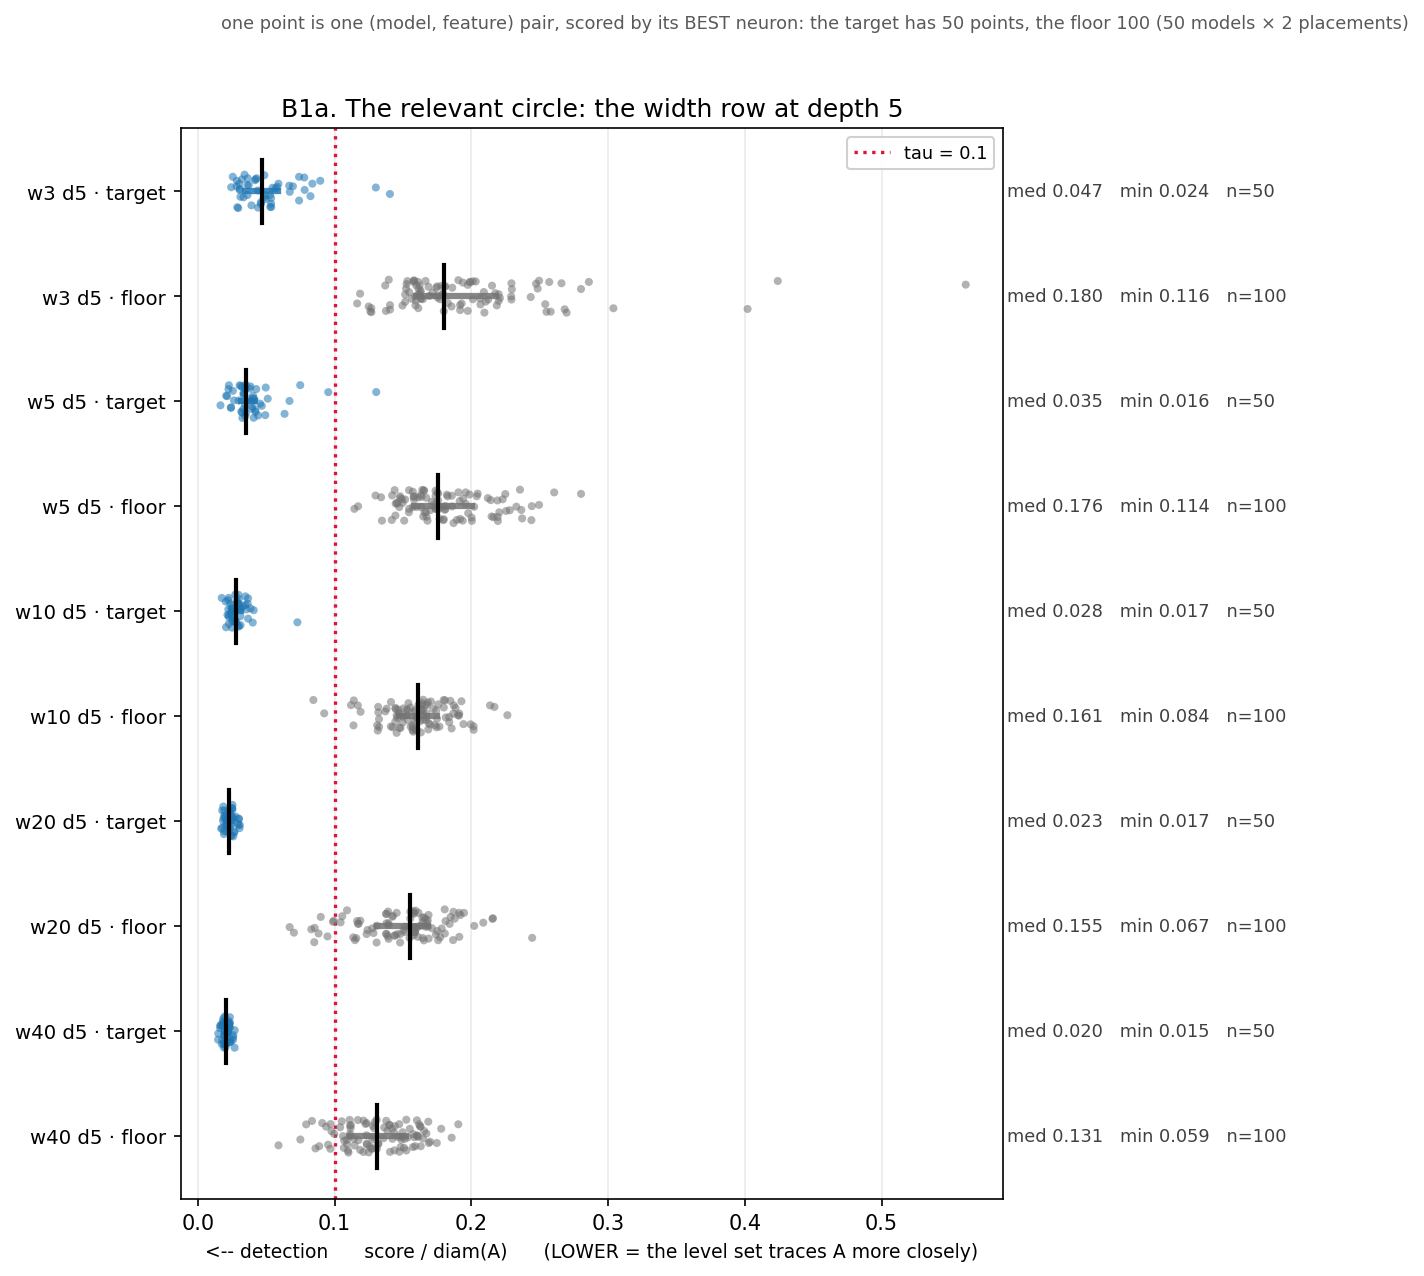

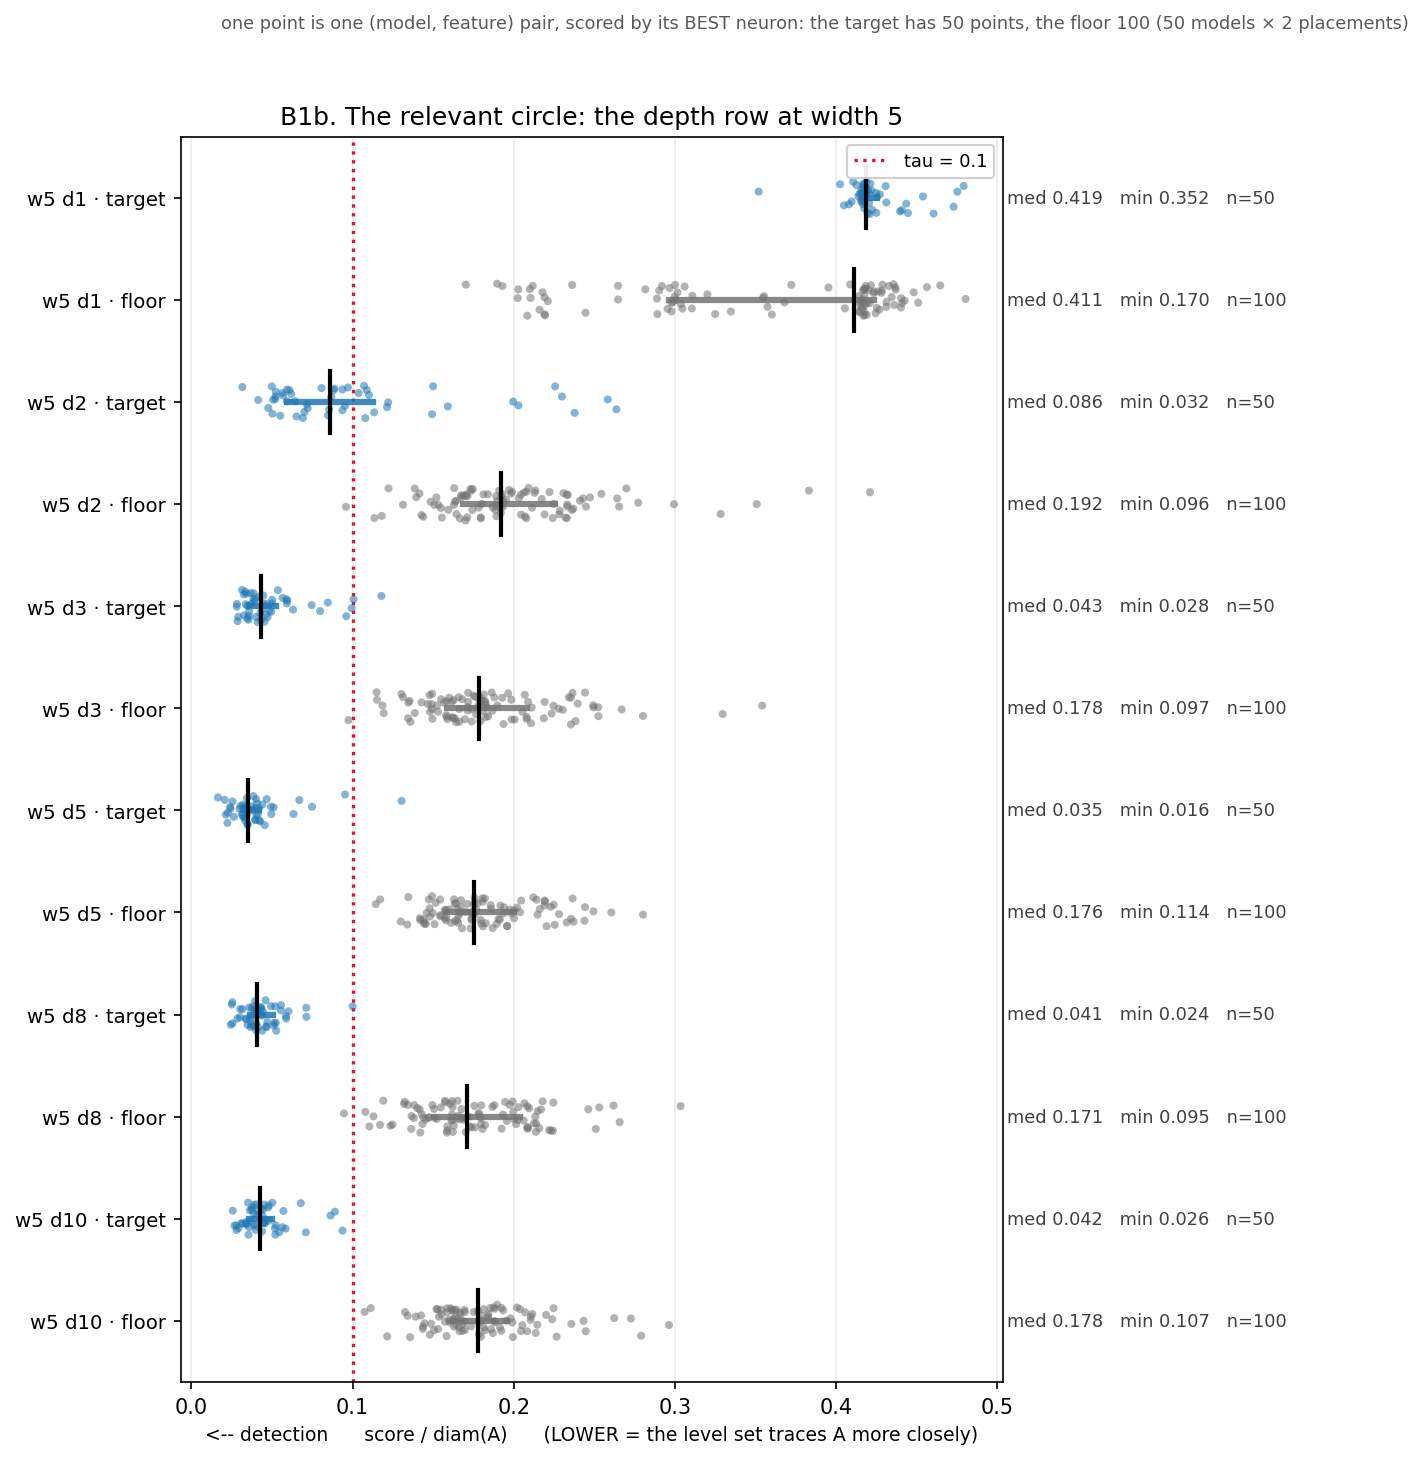

In [21]:
strips(REL, W_ROW_R, "B1a_relevant_width.png",
       "B1a. The relevant circle: the width row at depth 5")
strips(REL, D_ROW, "B1b_relevant_depth.png",
       "B1b. The relevant circle: the depth row at width 5")

### What B1 shows

**Complete separation.** The blue clouds lie entirely to the left of `τ`, the grey ones entirely to the
right; they do not even touch. For comparison, in part A the blue lay to the right of the grey. This is the
same instrument on the same data — the only difference is the role of the circle in the task.

**The depth row shows the boundary.** At `d = 1` the blue cloud moves right to 0.42 and merges with the
floor — this is the theorem zero. At `d = 2` there is already a separation, but an incomplete one. After that
it holds.

**As width grows the blue cloud contracts.** The spread of the score between models falls monotonically and
strongly: σ = 0.024 at `w3 d5`, 0.019 at `w5`, 0.008 at `w10`, 0.004 at `w20` and **0.003** at `w40` — an
eightfold drop. The range goes the same way: from 0.024–0.140 to 0.015–0.027. Wide ensembles are not just
better on average, they are **more homogeneous**: at the minimal width individual models miss `τ`, at two
hundred neurons there are none such at all.

**Meanwhile the grey cloud drifts left.** The median of the floor goes 0.180 → 0.176 → 0.161 → 0.155 →
**0.131** from `w3` to `w40`. That is, width moves both populations in one direction, and this has to be
analysed as a pair — which is what part B4 does.

**And along depth almost nothing changes after the fifth layer.** The target median: 0.086 → 0.043 → 0.035 →
0.041 → 0.042 at `d` = 2, 3, 5, 8, 10; the floor median: 0.192 → 0.178 → 0.176 → 0.171 → 0.178. Both
quantities reach a shelf around `d = 5`, and from there on fifty neurons laid out in depth suffice for
exactly what twenty-five sufficed for. This observation is worth remembering — in parts C and E it will turn
out that one and the same phenomenon stands behind it.

---

### B2. Does the fraction hold — and what does depth do

The first substantive figure of the part. Three panels: the fraction of witnesses against width, against
depth, and `P(the model has at least one witness)`.

**Why the green line next to the blue one.** The blue is the fraction of ALL neurons, as in experiment 1. But
the denominator depends on depth: at `d = 2` half of the neurons are incapable by the theorem, at `d = 8` an
eighth, so part of the growth along depth is arithmetic. The green is the same fraction counted only over
capable neurons (layer ≥ 1, width ≥ 3). If the green grows the same way as the blue, then the effect of depth
is not in the denominator.

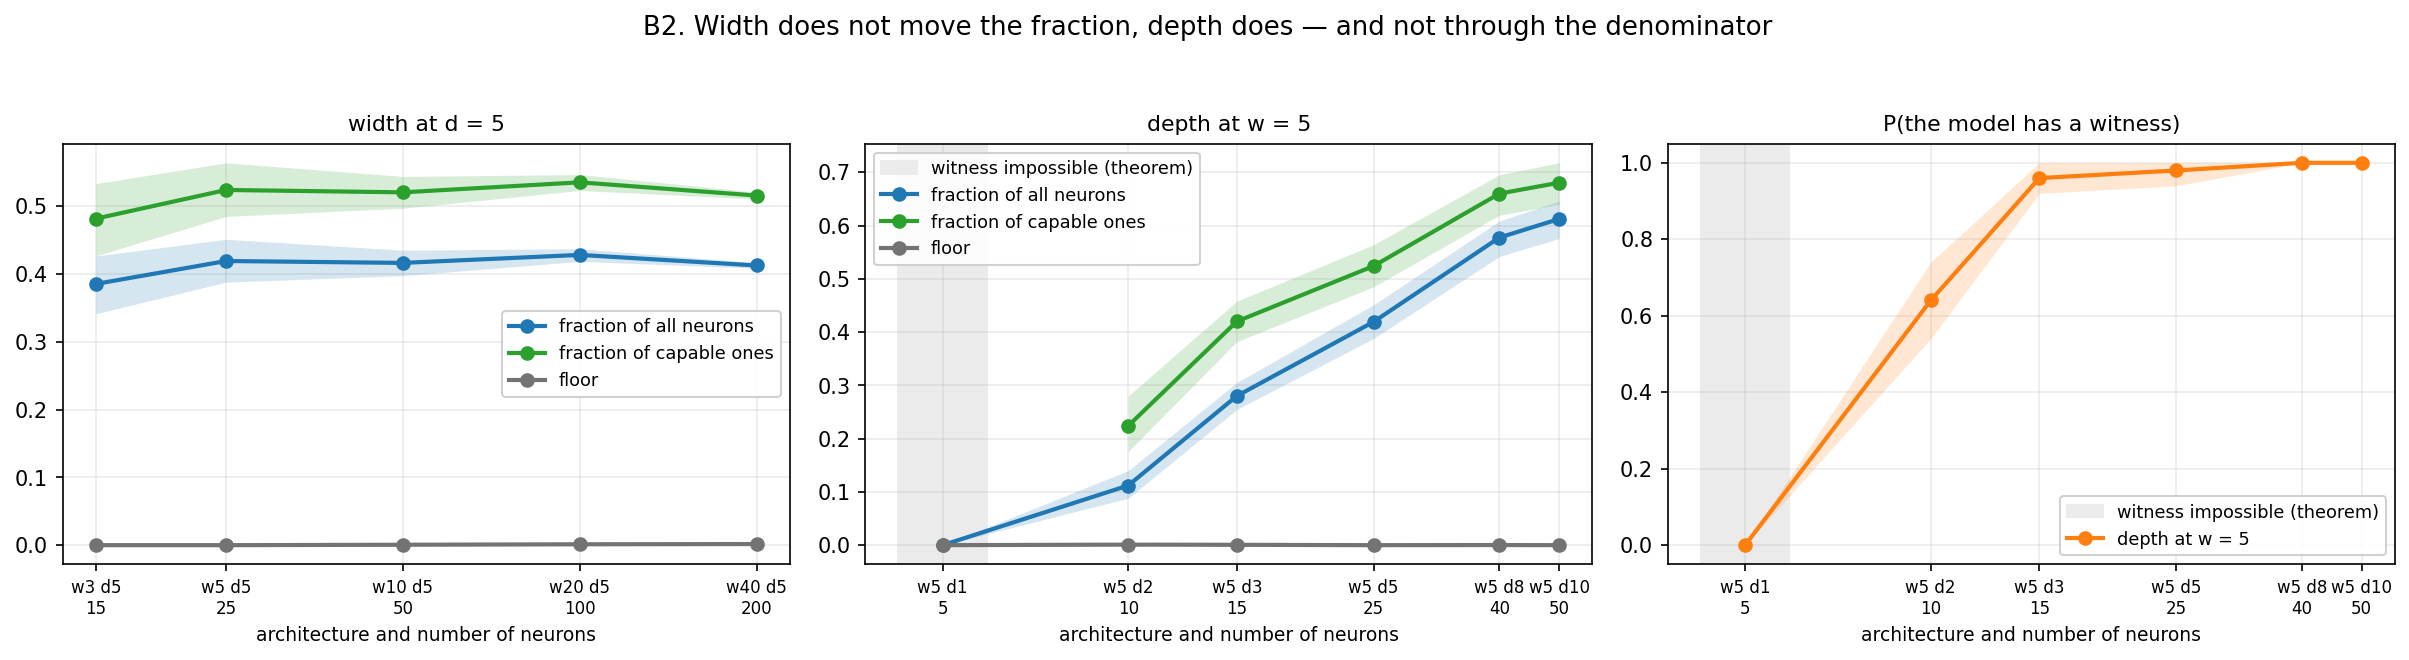

relevant · witness_fraction · width                  slope +0.0208 [-0.0091, +0.0527] per decade, zero inside: True


relevant · witness_fraction_capable · width          slope +0.0260 [-0.0114, +0.0659] per decade, zero inside: True


relevant · witness_fraction · depth                  slope +0.7159 [+0.6613, +0.7646] per decade, zero inside: False


relevant · witness_fraction_capable · depth          slope +0.6368 [+0.5528, +0.7093] per decade, zero inside: False


In [22]:
ap.plot_axis_panels(cells, [
    dict(title="width at d = 5", dataset_type=REL, cells=W_ROW_R,
         series=[("witness_fraction", "fraction of all neurons", "tab:blue"),
                 ("witness_fraction_capable", "fraction of capable ones", "tab:green"),
                 ("null_fraction", "floor", "0.45")]),
    dict(title="depth at w = 5", dataset_type=REL, cells=D_ROW,
         series=[("witness_fraction", "fraction of all neurons", "tab:blue"),
                 ("witness_fraction_capable", "fraction of capable ones", "tab:green"),
                 ("null_fraction", "floor", "0.45")]),
    dict(title="P(the model has a witness)", dataset_type=REL, cells=D_ROW,
         series=[("p_has_witness", "depth at w = 5", "tab:orange")]),
], suptitle="B2. Width does not move the fraction, depth does — and not through the denominator",
   save_path=FIG / "B2_relevant_fraction.png")
show(FIG / "B2_relevant_fraction.png")

for cs, axis in ((W_ROW_R, "width"), (D_ROW_CAP, "depth")):
    for st in ("witness_fraction", "witness_fraction_capable"):
        trend(cs, st, REL, f"relevant · {st} · {axis}")

### What B2 shows

**Width does not move the fraction.** Along the whole row it stays within the band 0.385–0.428 while the
width grows **13.3-fold** (from fifteen neurons to two hundred): 0.385 → 0.419 → 0.416 → 0.428 → 0.413.
The slope is **+0.021 [−0.009, +0.053]** per decade of neurons, zero inside the interval. By the announced
rule the fraction holds, and tripling the span of the axis did not change this.

**Depth moves it fivefold:** 0.112 → 0.612, a slope of **+0.716 [+0.661, +0.765]** — more than an order of
magnitude larger than along width.

**And it is not the denominator.** The green line runs almost parallel to the blue: the slope of the fraction
among capable neurons is **+0.637 [+0.553, +0.709]**. The arithmetic of the first layer explains a small part
of the effect; the rest is real.

**`P(has a witness)` saturates quickly:** 0.00 → 0.64 → 0.96 → 0.98 → 1.00 → 1.00 at `d` = 1, 2, 3, 5, 8,
10. From three layers on practically every model has a witness, and from there it is not the presence that
grows but the number.

---

### B3. The same in counts — and how it is spread between models

Here it has to be said at once what this figure does **not** prove. "The fraction holds" and "the number
grows linearly" are one statement written twice: number = fraction × N by definition, and there is no
separate discovery in the second. Nor is a competing hypothesis "a constant number" tested here: it is
already rejected by the fraction not falling.

The figure is needed for something else — for the **spread**. The fraction per cell is one number; it does
not say whether all models of the ensemble are built alike or whether the average is made up of very
different ones. A point is one model, a diamond is the median of a cell, and the grey line is the constant
fraction converted to counts, to anchor the eye.

Two rows at once, width and depth: they have different fractions (0.416 against 0.553), and hence different
slopes.

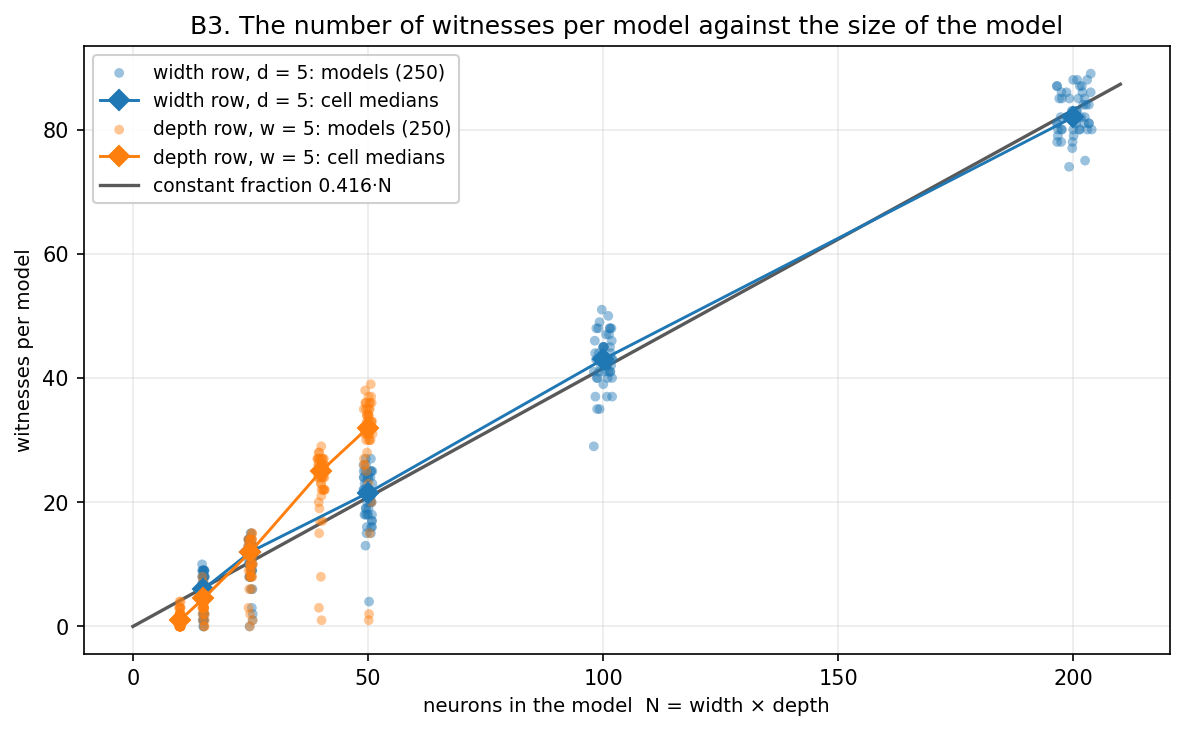

  width   : pooled fraction 0.416, i.e. on average 0.416·N witnesses per model
  depth   : pooled fraction 0.553, i.e. on average 0.553·N witnesses per model
  w3 d5  : median   6.0, range 0–10, interquartile 5–8
  w5 d5  : median  12.0, range 0–15, interquartile 9–13
  w10 d5 : median  21.5, range 4–27, interquartile 18–24
  w20 d5 : median  43.0, range 29–51, interquartile 41–45
  w40 d5 : median  82.0, range 74–89, interquartile 80–85


In [23]:
counts = aw.witness_counts(df, REL, ALL_R)
counts.to_csv(AGG / "witness_counts_per_model.csv", index=False)

fit_width = aw.count_fit(df, REL, W_ROW_R)
fit_depth = aw.count_fit(df, REL, D_ROW_CAP)
pd.DataFrame([{**f, "cells": " ".join(f"w{w}d{d}" for w, d in f["cells"])}
              for f in (fit_width, fit_depth)]).to_csv(AGG / "count_fit.csv", index=False)

w_archs = [f"w{w} d{d}" for w, d in W_ROW_R]
d_archs = [f"w{w} d{d}" for w, d in D_ROW_CAP]
ap.plot_count_vs_neurons(
    [("width row, d = 5", counts[counts.arch.isin(w_archs)], "tab:blue"),
     ("depth row, w = 5", counts[counts.arch.isin(d_archs)], "tab:orange")],
    fraction=fit_width["fraction"],
    title="B3. The number of witnesses per model against the size of the model",
    save_path=FIG / "B3_count_vs_neurons.png")
show(FIG / "B3_count_vs_neurons.png")

for name, f in (("width", fit_width), ("depth", fit_depth)):
    print(f"  {name:8s}: pooled fraction {f['fraction']:.3f}, "
          f"i.e. on average {f['fraction']:.3f}·N witnesses per model")
for arch in w_archs:
    c = counts[counts.arch == arch]["count"]
    print(f"  {arch:7s}: median {c.median():5.1f}, range {c.min()}–{c.max()}, "
          f"interquartile {c.quantile(0.25):.0f}–{c.quantile(0.75):.0f}")

### What B3 shows

**The spread between models is large and grows together with the number.** At `w3 d5` models give from 0 to
10 witnesses, at `w20 d5` from 29 to 51. The ensemble is heterogeneous: a fraction of 0.43 is not "43% in
every model" but an average over noticeably different models.

**The relative spread meanwhile falls** — at `w3 d5` the interquartile range is 5–8 with a median of 6, at
`w20 d5` it is 41–46 with a median of 43. Exactly what one expects if each neuron picks up the circle
independently: the relative spread of a sum falls as `1/√N`.

**The depth row is steeper than the width row** (a fraction of 0.494 against 0.425) — the same difference
as in B2, only in counts.

---

### B4. Did the best neuron become better — or did there simply become more of them

The median of the best improves with width: 0.0471 → 0.0230. By itself this means nothing: the minimum over
a larger number of attempts decreases even when all attempts are of the same quality. A way is needed to
separate one from the other.

**The floor gives this way, and without a single imported constant.** The null placements live in the same
cells, the same number of neurons is available to them, and there is no signal in them by construction. So
their own fall as the network grows **is the effect of multiplicity**, measured here, on the same statistic
and in the same units.

**How the dashed line is built.** It is neither a fit nor a law from another experiment. We take the target
in the reference cell `w5 d5` and move it exactly as much as the FLOOR moved:

```
prediction(cell) = target(w5 d5) × floor(cell) / floor(w5 d5)
```

It reads as "where the best neuron would stand if width changed only the number of attempts".
**A point on the line — no improvement. A point below the line — the neurons really became closer to A.**

Under the figure the log-log exponents for the target and for the floor are printed — the same comparison,
but as a number.

  target by width: N^(-0.315) [-0.357, -0.276]


  floor by width: N^(-0.117) [-0.141, -0.093]


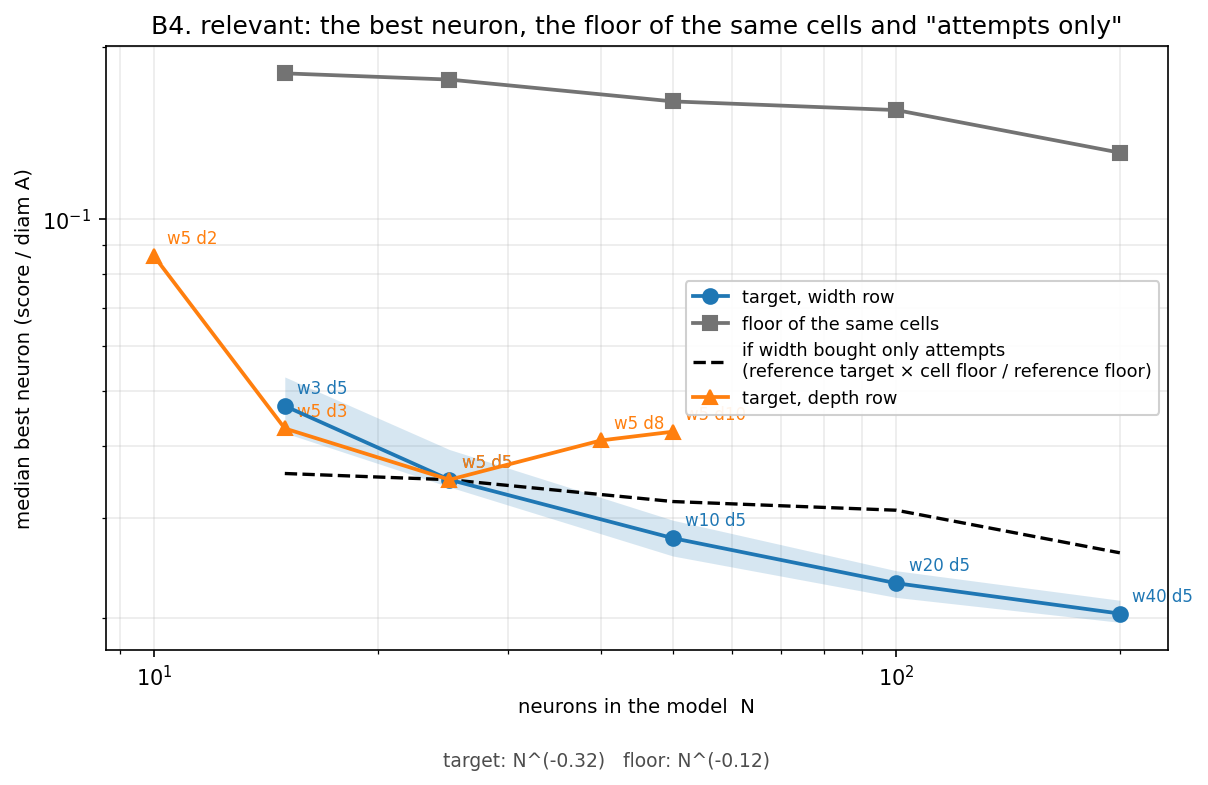

  w3 d5  : measured 0.0471 [0.0422, 0.0529], "attempts only" would give 0.0358 — the measured one is worse by a factor of 1.31
  w5 d5  : measured 0.0349 [0.0339, 0.0395], "attempts only" would give 0.0349 — the measured one is worse by a factor of 1.00
  w10 d5 : measured 0.0276 [0.0257, 0.0297], "attempts only" would give 0.0320 — the measured one is BETTER by a factor of 1.16
  w20 d5 : measured 0.0230 [0.0217, 0.0242], "attempts only" would give 0.0309 — the measured one is BETTER by a factor of 1.34
  w40 d5 : measured 0.0204 [0.0197, 0.0215], "attempts only" would give 0.0260 — the measured one is BETTER by a factor of 1.28

neurons below the "instrument ceiling" claimed by experiment 1, 0.0343: 4461 of 30300 (14.7%); the lowest score of the pool 0.0147
  w 3 d5: below the ceiling  4.93%, minimum 0.0243
  w 5 d5: below the ceiling  7.76%, minimum 0.0165
  w10 d5: below the ceiling 15.80%, minimum 0.0174
  w20 d5: below the ceiling 24.72%, minimum 0.0170
  w40 d5: below the ceilin

In [24]:
check = aw.floor_scaled_check(cells, REL)
check.to_csv(AGG / "floor_scaled_check.csv", index=False)

exps = {}
for st, name in (("median_best", "target"), ("median_best_null", "floor")):
    e = aw.loglog_exponent(df, W_ROW_R, REL, st, n_boot=2000)
    exps[name] = e["exponent"]
    print(f"  {name:5s} by width: N^({e['exponent']:+.3f}) "
          f"[{e['exponent_lo']:+.3f}, {e['exponent_hi']:+.3f}]")

ap.plot_best_vs_floor(check, W_ROW_R, D_ROW_CAP, exponents=exps,
    title="B4. relevant: the best neuron, the floor of the same cells and \"attempts only\"",
    save_path=FIG / "B4_best_vs_floor.png")
show(FIG / "B4_best_vs_floor.png")

for r in check[check.arch.isin([f"w{w} d{d}" for w, d in W_ROW_R])].itertuples():
    print(f"  {r.arch:7s}: measured {r.median_best:.4f} "
          f"[{r.median_best_lo:.4f}, {r.median_best_hi:.4f}], "
          f"\"attempts only\" would give {r.predicted_median_best:.4f} — "
          + (f"the measured one is BETTER by a factor of {1 / r.observed_over_predicted:.2f}"
             if r.observed_over_predicted < 1 else
             f"the measured one is worse by a factor of {r.observed_over_predicted:.2f}"))

CEIL = 0.0343
t = df[(df.dataset_type == REL) & (df.feature_role == "target")]
print(f"\nneurons below the \"instrument ceiling\" claimed by experiment 1, {CEIL}: "
      f"{int((t.score < CEIL).sum())} of {len(t)} ({(t.score < CEIL).mean():.1%}); "
      f"the lowest score of the pool {t.score.min():.4f}")
for w, d in W_ROW_R:
    g = t[(t.hidden_dim == w) & (t.n_layers == d)]
    print(f"  w{w:2d} d{d}: below the ceiling {(g.score < CEIL).mean():6.2%}, "
          f"minimum {g.score.min():.4f}")

### What B4 shows

The question of this part is simple: the best neuron of a wide network is better — but isn't that simply
because it is chosen from a larger number of candidates? This cannot be answered by theory, because it is
unknown how many "independent attempts" a given architecture provides. But it can be **measured**: the floor
is exactly what multiplicity does to the score, because the null placement is chosen so that nothing but
multiplicity stands behind it. So the reference is taken from the floor of the very same cells, not from a
law.

**The target falls noticeably faster than the floor.** In log-log the target goes as
`N^(−0.315) [−0.357, −0.276]`, the floor as `N^(−0.117) [−0.141, −0.093]`: almost three times steeper, the
intervals do not overlap. So width buys not only tickets — the neurons really do become closer to the
circle.

**But the gain does not appear at once and does not grow without bound.** Relative to the line "as much as
multiplicity alone would give", the cells go like this: `w3 d5` is **worse** than it by a factor of 1.31,
`w5 d5` is the anchor itself, `w10 d5` is better by 1.16, `w20 d5` better by 1.34, `w40 d5` better by
**1.28**. That is, at the minimal architecture the best neuron is worse than multiplicity alone would give;
the advantage appears beyond the reference, grows up to `w20` and stops at the doubling of width.

**It stops not because of the target but because of the floor.** At the last step the floor falls sharply —
from 0.1553 to 0.1308, a local slope of −0.25 against −0.05 on the previous segments — while the target keeps
improving steadily (0.0230 → 0.0204). At two hundred neurons per layer multiplicity has finally come into full
force: going through so many level curves, the ensemble finds a decent one even in a place known to be wrong.
The gap narrowed because the background caught up, not because the signal weakened.

**Along depth the same comparison gives the opposite answer.** `w5 d8` with forty neurons gives 0.0410, and
`w5 d10` with fifty gives 0.0424, whereas `w5 d5` with twenty-five gives **0.0349**. The floor meanwhile
stands still along the depth row (0.192 → 0.178). So the neurons added in depth work neither as additional
attempts nor as an improvement in quality: after the fifth layer depth buys nothing. The mechanism of this is
analysed in part C.

**Along the way all this refutes the "instrument ceiling" of experiment 1.** There, from the decomposition of
the planted neuron (0.0343, of which 0.0016 is geometry), the conclusion was drawn: "at R = 200 no neuron,
however ideal, will go lower". In this pool **4,461 neurons out of 30,300** go below 0.0343, the lowest at
**0.0147**. And the share of such neurons grows with width: 4.9% at `w3 d5`, 7.8% at `w5 d5`, 15.8% at
`w10 d5`, 24.7% at `w20 d5`, 24.9% at `w40 d5`.

The error was not in the measurement but in the generalisation: 0.0343 is the overhead of **that particular
probe**. The planted neuron is built with its cap normalised to one, its field reaches only ≈ 0.76 and stays
gently sloped, so its adaptive ε is wide. A trained neuron with a steep ring has a thinner level band and a
smaller overhead. **What transfers is the method of decomposition, not the number.**

---

### B5. An equal budget of neurons: width against depth without the confound

The rows of B2 changed the shape of the network together with the number of neurons, so "depth is stronger
than width" was said there with a caveat. The equal-budget diagonal removes the caveat: five architectures of
**24–25 neurons** each, from `w24 d1` to `w3 d8`. The number of neurons is constant, only the shape changes.

Formally this is a question of task D, but without it the conclusions of A and B are incomplete: there
architectures of different size were compared, and here we check whether the conclusion survives fixing the
budget. The full sweep of width against depth remains for D.

On the left relevant, on the right irrelevant — both tasks on one axis, because it is precisely the contrast
that is of interest.

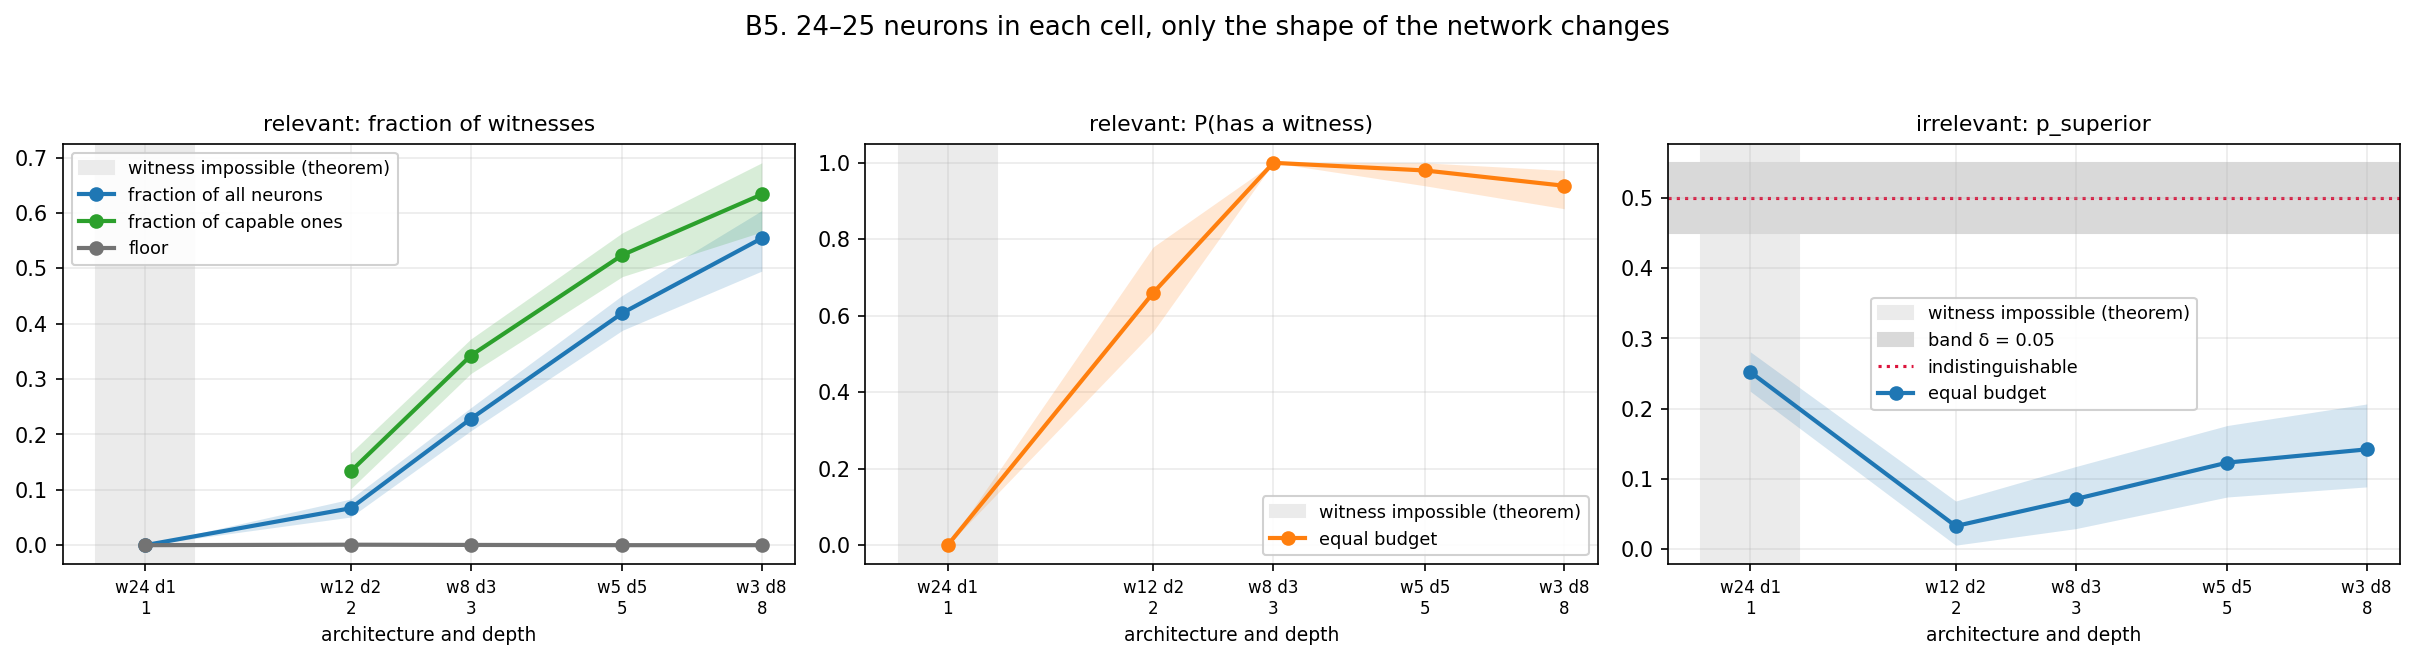

relevant, equal budget:
  w24 d1  (24 neurons,  0 capable): fraction 0.000, P(has) 0.00
  w12 d2  (24 neurons, 12 capable): fraction 0.067, P(has) 0.66
  w8 d3   (24 neurons, 16 capable): fraction 0.228, P(has) 1.00
  w5 d5   (25 neurons, 20 capable): fraction 0.419, P(has) 0.98
  w3 d8   (24 neurons, 21 capable): fraction 0.554, P(has) 0.94

all slopes saved to analysis/results/experiments/exp2_arch_sweep/aggregates/arch_trends.csv (6 rows)


In [25]:
ap.plot_axis_panels(cells, [
    dict(title="relevant: fraction of witnesses", dataset_type=REL, cells=BUDGET_ROW,
         series=[("witness_fraction", "fraction of all neurons", "tab:blue"),
                 ("witness_fraction_capable", "fraction of capable ones", "tab:green"),
                 ("null_fraction", "floor", "0.45")]),
    dict(title="relevant: P(has a witness)", dataset_type=REL, cells=BUDGET_ROW,
         series=[("p_has_witness", "equal budget", "tab:orange")]),
    dict(title="irrelevant: p_superior", dataset_type=IRR, cells=BUDGET_ROW,
         series=[("p_superior", "equal budget", "tab:blue")],
         hline=(0.5, "indistinguishable"), band=(0.45, 0.55, "band δ = 0.05")),
], x="depth",
   suptitle="B5. 24–25 neurons in each cell, only the shape of the network changes",
   save_path=FIG / "B5_equal_budget.png")
show(FIG / "B5_equal_budget.png")

b = cells[(cells.dataset_type == REL) & cells.arch.isin(
    [f"w{w} d{d}" for w, d in BUDGET_ROW])].sort_values("depth")
print("relevant, equal budget:")
for r in b.itertuples():
    print(f"  {r.arch:7s} ({r.n_neurons:2d} neurons, {r.n_capable:2d} capable): "
          f"fraction {r.witness_fraction:.3f}, P(has) {r.p_has_witness:.2f}")

pd.DataFrame(TRENDS).to_csv(AGG / "arch_trends.csv", index=False)
print(f"\nall slopes saved to {AGG / 'arch_trends.csv'} ({len(TRENDS)} rows)")

### What B5 shows

**At a constant budget the fraction grows with depth monotonically.** Twenty-four neurons give a witness
fraction of 0.00 with one layer, 0.07 with two, 0.23 with three and **0.55 with eight**. The number of neurons
is one and the same all the while — only the shape of the network changes. There is no confound with size.

`P(has a witness)` saturates already at three layers and does not grow further: it is not the presence that
changes but the number. The small dip at eight layers is the cell `w3 d8`, where the width equals the
minimal one and part of the models train at the edge.

**On irrelevant the shape of the network does not improve the target.** `p_superior` at an equal budget
stays deep below 0.5 on all five shapes, but it is not constant: among the capable cells it goes 0.033 →
0.071 → 0.123 → 0.142 with depth, i.e. fourfold. One has to look, however, at WHICH of the two quantities
moves: the target median stands still along the row (0.4126 → 0.4080), while the floor gets worse
(0.1976 → 0.2458). So at an equal budget depth makes the NULL placements harder, not the target easier, and
the narrowing of the gap found in A2 still comes from the **number** of neurons, not from how they are laid
out. More in part D.

---

## Summary of B

**1. Width does not change the fraction, but it changes the number.** As the width grows 13.3-fold the
fraction of witnesses stays put (0.385–0.428, the slope interval includes zero), while their number grows in
proportion to the network — from six to **eighty-two**. It reads as follows: **each added neuron picks up the
circle with roughly the same probability as those already there.** There is no idle width.

**1b. Width makes the ensemble more homogeneous.** The spread of the best score between models falls
eightfold (σ = 0.024 at `w3 d5` against 0.003 at `w40 d5`), and at two hundred neurons not a single model
misses `τ`. The floor meanwhile moves in the same direction (0.180 → 0.131), which is why the two quantities
are analysed as a pair.

**2. Width meanwhile also makes the neurons qualitatively better — but the advantage runs into the floor.**
The best neuron improves faster than multiplicity alone explains (`N^(−0.315)` against `N^(−0.117)` for the
floor, the intervals do not overlap). Relative to the multiplicity reference taken from the floor of the same
cells, the gain grows up to `w20 d5` (1.34-fold) and stops growing at `w40 d5` (1.28) — because at two
hundred neurons the floor itself went down sharply. At the minimal architecture it is the other way round:
there the best neuron is 1.31 times **worse** than the reference, i.e. the gain appears only beyond the
reference.

**3. Depth is stronger than width, and this is not an artefact.** The fraction of witnesses grows with depth
**fivefold** (0.11 → 0.61), while width does not move it. The effect survives two checks: it remains if the
fraction is counted only over neurons capable of carrying a closed level curve, and it remains at a **fixed
number of neurons** (B5). At the same time, after the fifth layer almost everything stops changing: the
quality of the best neuron goes 0.0349 → 0.0410 → 0.0424 at `d = 5, 8, 10`, and the floor stays put
(0.176 → 0.171 → 0.178). Depth adds witnesses, not sharpness, and adds them not as extra attempts —
otherwise the floor would fall together with the number of neurons, as it falls along width. The mechanism is
analysed in C.

**4. The zero at depth 1 is a theorem, not a result.** The single hidden layer of a depth-1 network is
`tanh(w·x + b)`; its level curves are straight lines. `w24 d1`, twenty-four neurons and zero witnesses,
demonstrates this and at the same time sets the limit of applicability of the whole part.

**A correction to experiment 1.** The "instrument ceiling" of 0.0343 claimed there is not a ceiling: in this
pool 4,461 neurons out of 30,300 go below it, the lowest score is 0.0147. The number was the overhead of a
particular planted probe with a gently sloped field, not a property of the instrument at `R = 200`. The
report and the notebook of experiment 1 have been corrected.

**A caveat removed by part E.** Along the width row it is not only the number of neurons that changes: the
gate fires the earlier, the wider the network, and the median stopping epoch falls from 124 epochs at
`w3 d5` to 9 at `w40 d5`. Until these two explanations are separated, all conclusions along the width axis are
formally conditional.

**Where this continues.**

* How many witnesses are in each layer and whether it is one neuron per layer — **task C** (moved from B).
* Whether a witness of layer `l` remains on layer `l + 1`, and whether continuity across layers is good as a
  filter of false positives — also **task C**.
* The full sweep of width against depth, beyond one diagonal — **task D**.
* Separating "width" from "training duration" — **task E**.

---

# C. Witnesses by layer

Parts A and B counted over the whole network at once. Here the only new axis is added — **the layer index**,
and everything done in C is indexed by it. This is also the boundary with the neighbouring experiments, and it
is drawn not by convention but by the data: in the pool there is **one** target feature per dataset and **no
intervention** in the network.

| neighbouring question | why C does not touch it |
|---|---|
| multitasking — one neuron witnesses several features | needs two target features in one dataset; here there is one |
| ablation — whether a neuron is causally needed | needs an intervention in the network; C only observes |
| distributed coding — how many neurons are required | "required" is not established without ablation |

So everywhere below "the feature is carried by several neurons" means **observed multiplicity**, and nothing
about necessity.

**What is called a profile here.** A profile is the dependence of some characteristic of witnessing on the
index of the hidden layer, for a fixed architecture and a fixed feature. There will be three
characteristics: the fraction of the layer's neurons that pass `τ`; the median score of the layer's neurons;
the fraction of the layer's neurons for which the homological criterion fired.

---

## Six questions

1. **What the profile looks like and whether it moves with the architecture.** The profile at `w5 d5` has
   already been measured by experiment 1; the contribution of C is the dependence on width and depth.
2. **The same profile in a continuous currency and by the second criterion** — because the fraction of
   witnesses depends on `τ`, while the score and the homological verdict do not depend on it or depend on it
   differently.
3. **Does the network's output itself witness the circle.** A separate question, not a technical detail: the
   output is exactly the function by which the classifier's verdict is made, and its score is directly
   comparable with the scores of the hidden neurons. The answer is needed both by itself and further on — in
   questions 4 and 6.
4. **Is the profile described by one curve**, if the position of the layer is normalised by the depth of the
   network and the head is added as the last layer. This was formerly task E; it has been merged in here,
   because without an answer to it the profile cannot be read, and the answer itself is computed from the
   same curves.
5. **How many witnesses there are in one layer and how this number changes from layer to layer.** Moved from
   B: in the formulation "one neuron for the whole network" the question is contradictory, within a layer it is
   correct.
6. **Is continuity across layers good as a filter of false positives.** If a feature is singled out on layer
   `l` and no deeper layer carries it, the network's head, which reads the last layer, does not use it — and
   such a firing is a candidate false positive, on grounds that do not depend on `τ`. Here, too, the check of
   whether the profile grows within each model and not only on average.

Only the network output requires new computation (questions 3, 4 and 6) — a couple of seconds per model;
everything else is computed from the same 184,050 rows, where the `layer_id` column already lies.

---

### C1. The profile and its dependence on architecture

**What we draw.** The fraction of the layer's neurons that pass `τ`, against the layer index. One curve per
cell, the band is a bootstrap interval over models (the unit of resampling stays the model, even though the
quantity is indexed by layer). On the left the depth row at `w = 5`, on the right the width row at `d = 5`.

**Dashed — the floor of the same cells.** It is mandatory here: the nulls could have a profile by layer too
(experiment 1 measured a fall of 0.422 → 0.228 from layer 0 to layer 3 at `far_right`), so without it a
growing curve cannot be told apart from "with depth everything simply gets more curved".

**What the figure does not show.** These are ensemble averages. Whether the profile grows within each
individual model is a question of the same type as the continuity filter, and both are computed in C6.

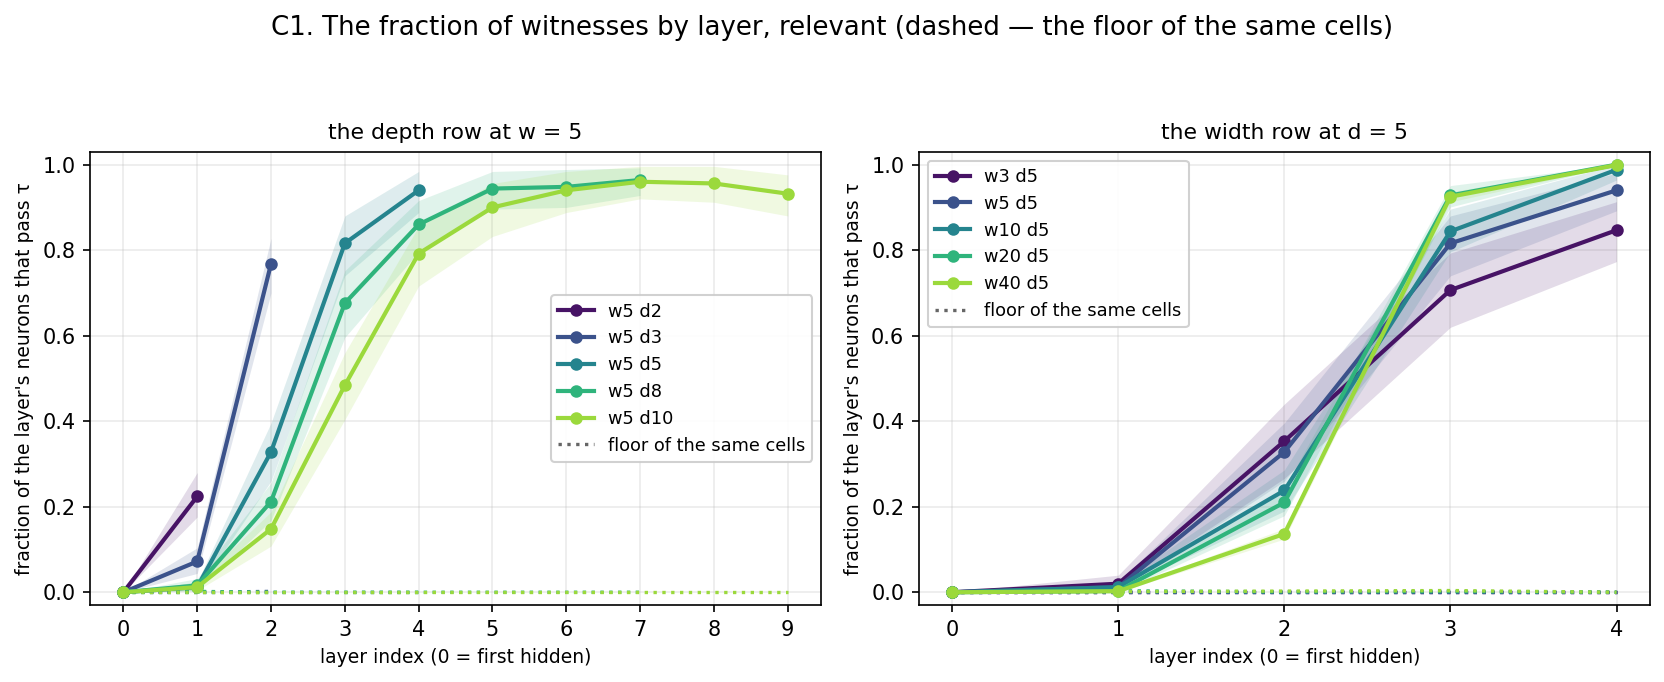

fraction of witnesses by layer, the depth row:
  d =  2: 0.000 0.224
  d =  3: 0.000 0.072 0.768
  d =  5: 0.000 0.012 0.328 0.816 0.940
  d =  8: 0.000 0.016 0.212 0.676 0.860 0.944 0.948 0.964
  d = 10: 0.000 0.012 0.148 0.484 0.792 0.900 0.940 0.960 0.956 0.932

the width row, layers 1-4:
  w 3 d5: 0.000 0.020 0.353 0.707 0.847
  w 5 d5: 0.000 0.012 0.328 0.816 0.940
  w10 d5: 0.000 0.012 0.238 0.844 0.988
  w20 d5: 0.000 0.003 0.210 0.928 1.000
  w40 d5: 0.000 0.003 0.136 0.925 0.999

maximum of the profile on irrelevant over all layers and cells: 0.0030
maximum of the floor on relevant over all layers and cells:      0.0040


In [26]:
D_ROW_C = [(5, 2), (5, 3), (5, 5), (5, 8), (5, 10)]   # the depth row, without d1
W_ROW_C = [(3, 5), (5, 5), (10, 5), (20, 5), (40, 5)]  # the width row
ALL_C = list(dict.fromkeys(D_ROW_C + W_ROW_C))

prof_depth = aw.layer_profile(df, REL, D_ROW_C, n_boot=2000)
prof_width = aw.layer_profile(df, REL, W_ROW_C, n_boot=2000)
floor_depth = aw.layer_profile(df, REL, D_ROW_C, role="null", n_boot=2000)
floor_width = aw.layer_profile(df, REL, W_ROW_C, role="null", n_boot=2000)
prof_irr = aw.layer_profile(df, IRR, ALL_C, n_boot=500)
pd.concat([prof_depth, prof_width, floor_depth, floor_width, prof_irr]).to_csv(
    AGG / "layer_profiles.csv", index=False)

ap.plot_layer_profiles([
    dict(title="the depth row at w = 5", profile=prof_depth, floor=floor_depth,
         x="layer_id", by="depth"),
    dict(title="the width row at d = 5", profile=prof_width, floor=floor_width,
         x="layer_id", by="width"),
], suptitle="C1. The fraction of witnesses by layer, relevant (dashed — the floor of the same cells)",
   save_path=FIG / "C1_layer_profile.png")
show(FIG / "C1_layer_profile.png")

print("fraction of witnesses by layer, the depth row:")
for depth in (2, 3, 5, 8, 10):
    b = prof_depth[prof_depth.depth == depth].sort_values("layer_id")
    print(f"  d = {depth:2d}: " + " ".join(f"{v:.3f}" for v in b.fraction))
print("\nthe width row, layers 1-4:")
for w, d in W_ROW_C:
    b = prof_width[prof_width.width == w].sort_values("layer_id")
    print(f"  w{w:2d} d{d}: " + " ".join(f"{v:.3f}" for v in b.fraction))
print(f"\nmaximum of the profile on irrelevant over all layers and cells: "
      f"{prof_irr.fraction.max():.4f}")
print(f"maximum of the floor on relevant over all layers and cells:      "
      f"{max(floor_depth.fraction.max(), floor_width.fraction.max()):.4f}")

### What C1 shows

**The profile grows from the input to the output almost everywhere.** For all depths up to the eighth and
for all widths the mean curve has no dip at all. The only exception is **`d = 10`, where on the last two
layers the curve goes down**: 0.960 → 0.956 → 0.932. The dip is small, but it is there, it is reproduced by
other quantities too, and we will come back to it in C2 and C5. In all the other cells the feature **is built
gradually**, rather than arising on an intermediate layer and getting lost; how true this is within an
individual model is checked in C6.

**The floor meanwhile is flat** — a maximum of 0.0040 over all layers and cells. On `simple_irrelevant` the
profile is flat too, with a maximum of 0.0030, and it is non-zero in exactly three places: layers 1 and 2 of
the cell `w20 d5` (0.0030 and 0.0010) and layer 1 of the cell `w40 d5` (0.0015) — that is, those very seven
neurons from part A, and all of them on the first two layers. So the growth across layers is not a general
property of "deeper — more curved".

**The shallower the network, the earlier it has to start.** On layer 1 the fraction is 0.224 at `d = 2`,
0.072 at `d = 3` and 0.012–0.016 at `d = 5, 8, 10`; on layer 2 it is 0.768 at `d = 3`, 0.328 at `d = 5`,
0.212 at `d = 8` and 0.148 at `d = 10`. The order is strict and along the whole depth axis: the more layers
ahead, the later the rise begins.

The reading is direct: **a shallow network has no slack in depth.** It needs to obtain the decisive feature
within two or three transformations, so it is forced to single out the circle already on the first hidden
layer. A deep network can afford to stretch the construction out — and does. This also explains why in part
B depth moved the fraction fivefold: it does not add witnesses to a ready profile, it changes the pace at
which the feature is assembled.

**Width does not shift the break but sharpens it — and the order of the curves flips at it.** On layer 2 the
fraction falls as the width grows (0.353 → 0.328 → 0.238 → 0.210 → **0.136** from `w3` to `w40`), while on
layers 3 and 4 it grows (0.707 → 0.925 and 0.847 → 0.999). At `w20 d5` the last layer witnesses **in full**,
all twenty neurons out of twenty, at `w40 d5` 0.999 out of forty.

A plausible explanation here is the same as for depth, only along a different axis: **a wide network does not
need to occupy an early layer in full.** At width 3 the network has no spare neurons — the fraction on an
early layer is high simply because everything there is is occupied. At width 40 the early layers can do
something else, and towards the output, where the features must become almost linearly separable, the circle
is picked up by all of them. This is **an interpretation, not a measurement**: these data cannot distinguish
"the network chose not to occupy the early layer" from "the network could not"; that would need a sweep over
the difficulty of the task at a fixed width.

---

### C2. The same profile in a continuous currency and by the second criterion

The fraction of witnesses is a thresholded quantity: it answers how many neurons crossed `τ` and is silent
about what happens to the rest. So here the same profile is drawn twice more.

**On the left — the median score of the layer's neurons.** This quantity has no threshold at all, the scale
is logarithmic, the red dashed line is `τ` to anchor the eye. If the fraction grew only because the tail of
the distribution creeps over the threshold, the median would stay put; if the median grows too, the whole
distribution shifts.

**On the right — the fraction of the layer's neurons for which the homological criterion fired.** It asks
something else: does the field have a loop of the required dimension **regardless of where `A` stands**.
Comparing the two profiles therefore answers a meaningful question: do a closed level curve and a correctly
placed closed level curve appear at the same time or not. And along the way — what exactly happens on the
last layers of `d = 10`, where the structural fraction went down.

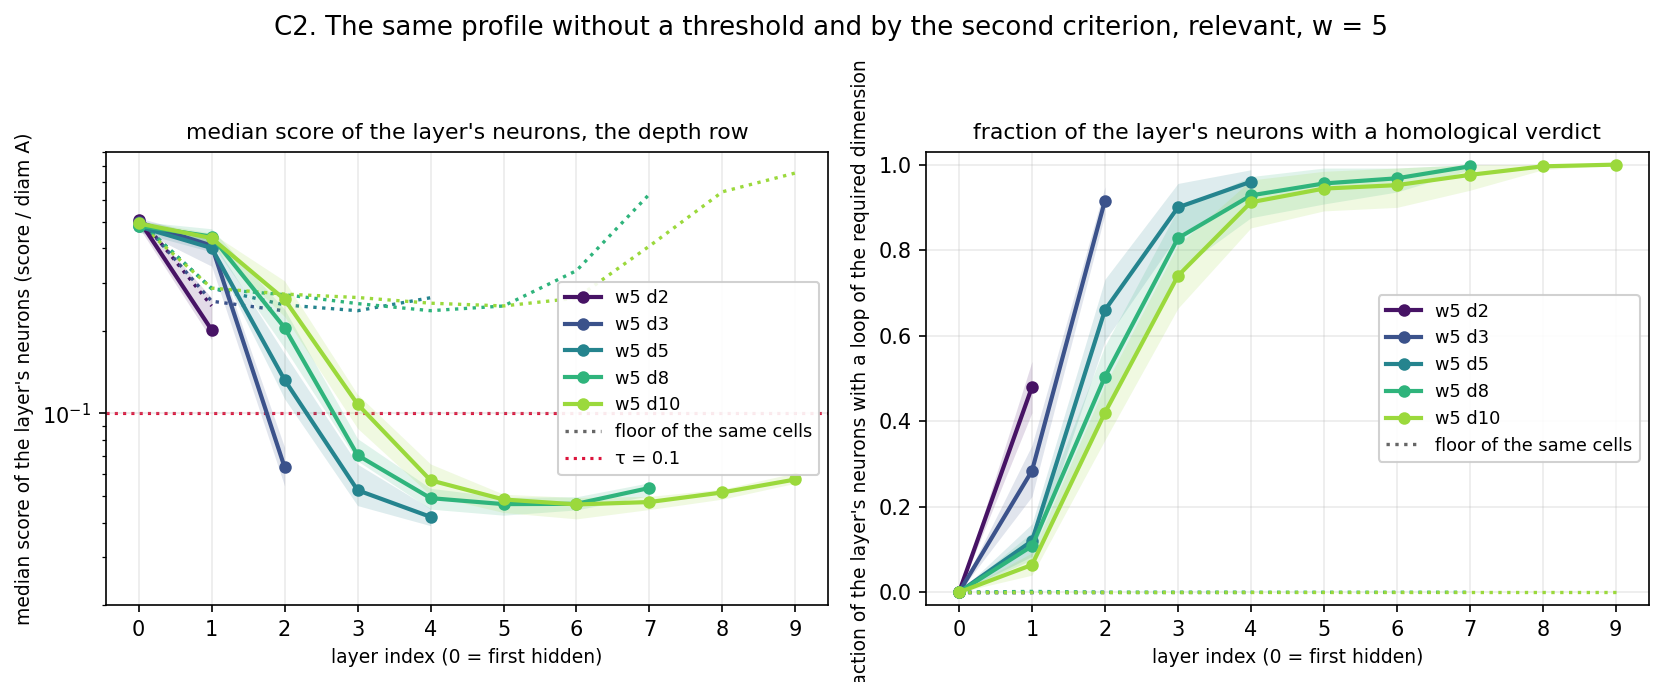

layer:                              0       1       2       3       4       5       6       7
d = 8, structural fraction :    0.000   0.016   0.212   0.676   0.860   0.944   0.948   0.964
d = 8, median score        :    0.484   0.442   0.205   0.070   0.049   0.047   0.047   0.053
d = 8, homological fraction:    0.000   0.108   0.504   0.828   0.928   0.956   0.968   0.996

d = 5, structural against homological fraction by layer:
  layer 0: structural 0.000, homological 0.000, lead +0.000
  layer 1: structural 0.012, homological 0.120, lead +0.108
  layer 2: structural 0.328, homological 0.660, lead +0.332
  layer 3: structural 0.816, homological 0.900, lead +0.084
  layer 4: structural 0.940, homological 0.960, lead +0.020


In [27]:
ap.plot_layer_profiles([
    dict(title="median score of the layer's neurons, the depth row", profile=prof_depth,
         floor=floor_depth, x="layer_id", by="depth", value="median_score",
         ylabel="median score of the layer's neurons (score / diam A)",
         log_y=True, ylim=(0.02, 0.9), hline=(aw.TAU, "τ = 0.1")),
    dict(title="fraction of the layer's neurons with a homological verdict", profile=prof_depth,
         floor=floor_depth, x="layer_id", by="depth", value="hom_fraction",
         ylabel="fraction of the layer's neurons with a loop of the required dimension"),
], suptitle="C2. The same profile without a threshold and by the second criterion, relevant, w = 5",
   save_path=FIG / "C2_score_and_homology.png")
show(FIG / "C2_score_and_homology.png")

print("layer:                       " + "".join(f"{l:>8d}" for l in range(8)))
for name, col in (("structural fraction ", "fraction"),
                  ("median score        ", "median_score"),
                  ("homological fraction", "hom_fraction")):
    b = prof_depth[prof_depth.depth == 8].sort_values("layer_id")
    print(f"d = 8, {name}: " + "".join(f"{v:8.3f}" for v in b[col]))
b5 = prof_depth[prof_depth.depth == 5].sort_values("layer_id")
print("\nd = 5, structural against homological fraction by layer:")
for r in b5.itertuples():
    print(f"  layer {r.layer_id}: structural {r.fraction:.3f}, "
          f"homological {r.hom_fraction:.3f}, "
          f"lead {r.hom_fraction - r.fraction:+.3f}")

### What C2 shows

**It is not the tail that grows but the whole distribution.** The median score of the layer's neurons at
`d = 5` falls from 0.481 on layer 0 to 0.042 on layer 4 — that is, by an order of magnitude, and the median
goes below `τ` already on layer 3. So the fraction of witnesses grows not because a few lucky neurons creep
over the threshold but because the whole population of the layer shifts. The threshold `τ` creates nothing in
this picture: it just marks where the curve crosses it.

**The score on the first hidden layer itself depends on depth, and in the same direction.** At `d = 2` the
median on layer 1 is 0.202, at `d = 3, 5, 8, 10` — 0.410, 0.401, 0.442, 0.436. A shallow network not only
crosses the threshold more often on an early layer, it is on average **closer to the circle** there. This is
the same lack of slack in depth, but measured without a threshold.

**The homological criterion consistently runs one layer ahead of the structural one.** At `d = 5`:

| layer | structural fraction | homological fraction | lead |
|---|---|---|---|
| 1 | 0.012 | 0.120 | +0.108 |
| 2 | 0.328 | 0.660 | +0.332 |
| 3 | 0.816 | 0.900 | +0.084 |
| 4 | 0.940 | 0.960 | +0.020 |

This reads as follows: **a closed level curve appears earlier than it becomes the circle.** On layer 2 two
thirds of the neurons have a loop, but only a third go around the target circle. The gap is largest exactly
at the break and almost disappears near the output.

**And on the last layers the two criteria diverge — this is the most interesting thing here.** At `d = 10` the
structural fraction goes down towards the end (0.960 → 0.956 → 0.932), while the homological one goes
**strictly up, all the way to one**: 0.976 → 0.996 → 1.000. The same at `d = 8`: 0.968 → 0.996 with the
structural one at 0.948 → 0.964. At no depth does the homological curve dip anywhere.

So the closed level curves on the last layers **do not disappear — there only become more of them**. What
changes is their geometry: they stop resembling our circle. A plausible reading is this: on the early layers
the level curve does not resemble `A` because the neuron lacks expressivity, on the middle ones it hits `A`,
and on the last ones the network keeps optimising an already solved task and arrives at something that solves
it no worse but differs from the circle geometrically. This is a **hypothesis**: the data show a divergence of
the two criteria, but what exactly the level curve became is not measured here.

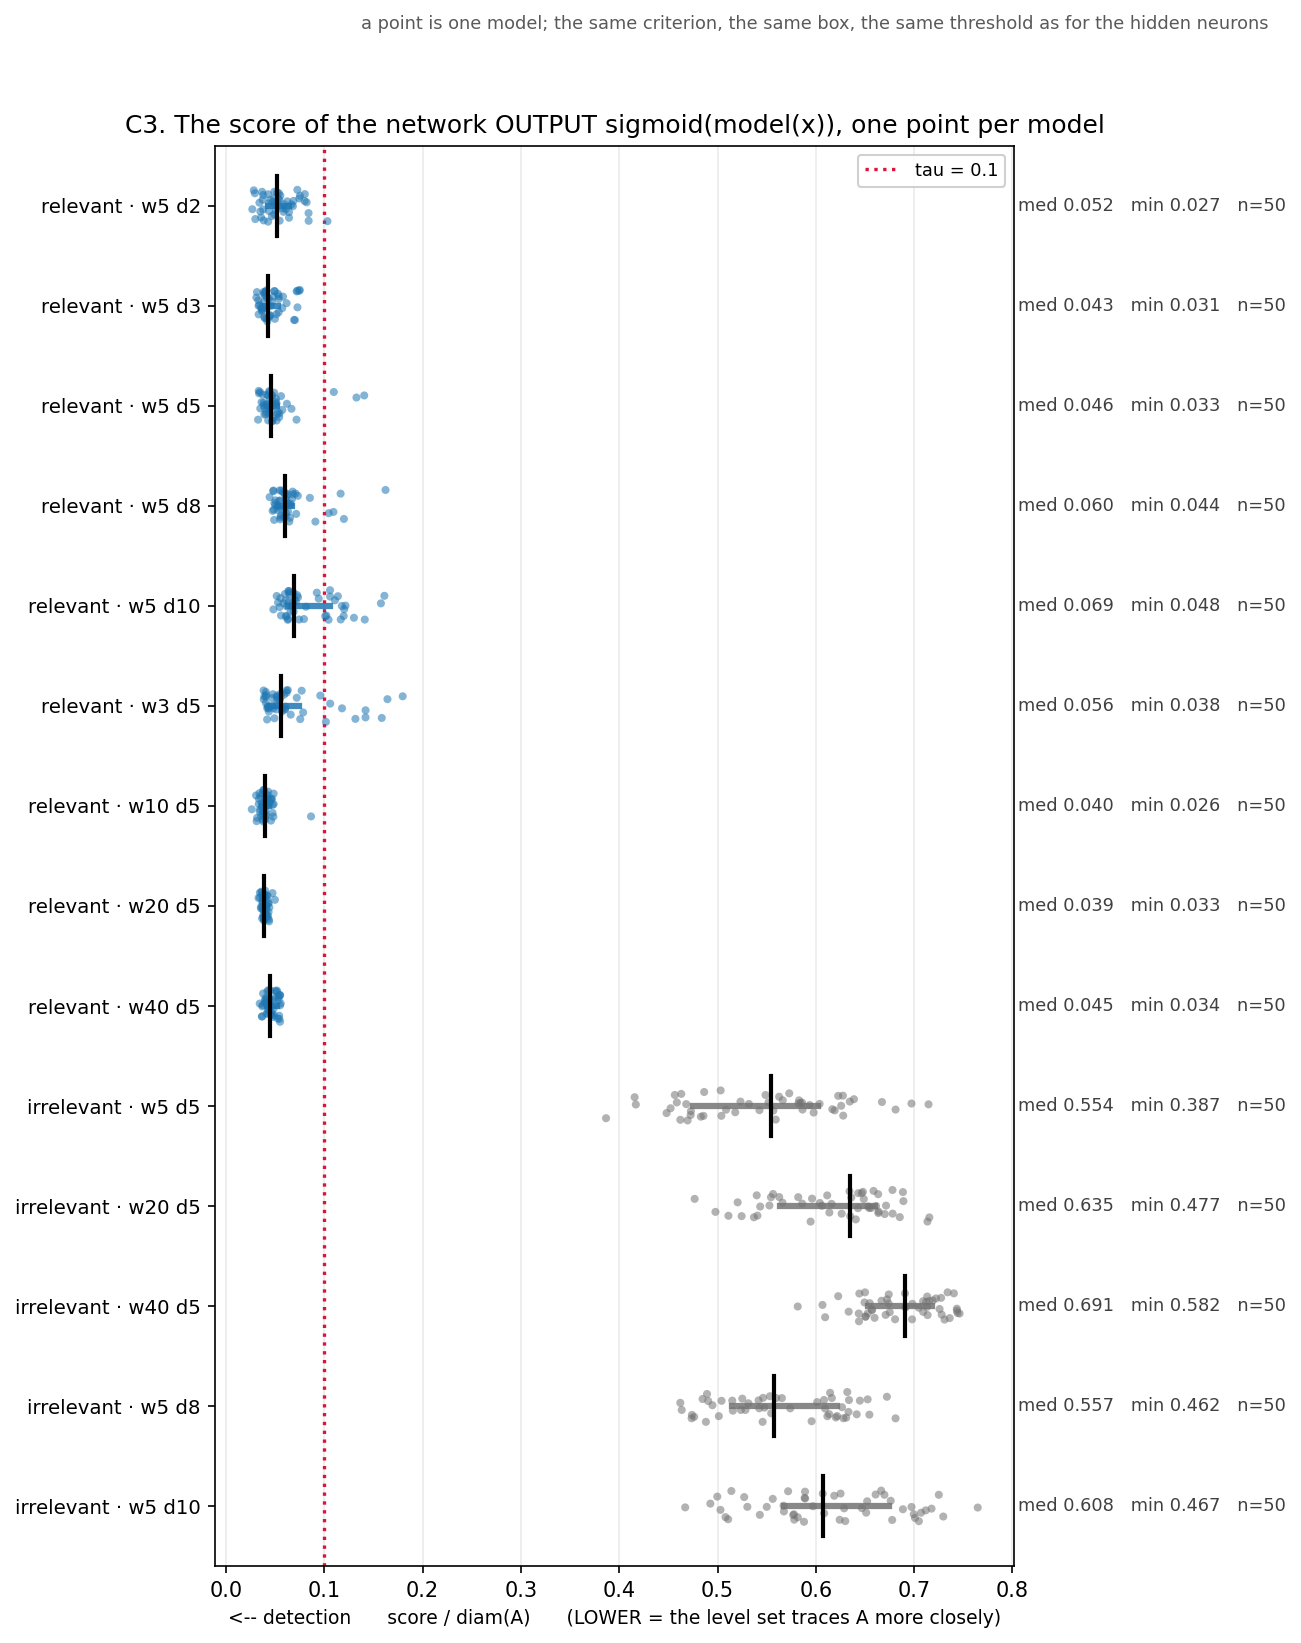

share of models with a witnessing head, % — the choice of output scale (where both were computed, 10 cells):


output,dataset_type,arch,logit,prob
0,simple_irrelevant,w20 d5,0.0,0.0
1,simple_irrelevant,w5 d5,0.0,0.0
2,simple_irrelevant,w5 d8,0.0,0.0
3,simple_relevant,w10 d5,100.0,100.0
4,simple_relevant,w20 d5,100.0,100.0
5,simple_relevant,w3 d5,84.0,82.0
6,simple_relevant,w5 d2,98.0,98.0
7,simple_relevant,w5 d3,100.0,100.0
8,simple_relevant,w5 d5,96.0,94.0
9,simple_relevant,w5 d8,96.0,90.0



head misses on relevant: 34 of 450, scores 0.101–0.180; median of the hits 0.0467
  by cell: w3 d5 9, w5 d10 16, w5 d2 1, w5 d5 3, w5 d8 5
the best output on irrelevant: 0.387 of 250 models


In [28]:
# The network's head. Hidden neurons are evaluated AFTER the nonlinearity (kind="post");
# the head's own nonlinearity is the sigmoid applied by the loss function
# (training predicts sigmoid(logit) > 0.5). So the head is taken as
# sigmoid(model(x)) — exactly the function in (0, 1) that the network is as a
# classifier. A couple of seconds per model, so the result is cached.
HEAD_CACHE = AGG / "head_scores.csv"
IRR_HEAD_CELLS = [(5, 5), (20, 5), (40, 5), (5, 8), (5, 10)]
heads_rel = aw.head_scores(df, REL, ALL_C, ES, cache=HEAD_CACHE,
                           output="prob", verbose=False)
heads_irr = aw.head_scores(df, IRR, IRR_HEAD_CELLS, ES, cache=HEAD_CACHE,
                           output="prob", verbose=False)
heads = pd.concat([heads_rel, heads_irr], ignore_index=True)

head_units = heads.assign(criterion="structural", feature="head",
                          dataset=heads.dataset_type)
groups = ([(f"relevant · {a}", {"dataset": REL, "arch": a}, "tab:blue")
           for a in [f"w{w} d{d}" for w, d in ALL_C]]
          + [(f"irrelevant · {a}", {"dataset": IRR, "arch": a}, "0.45")
             for a in [f"w{w} d{d}" for w, d in IRR_HEAD_CELLS]])
plot_unit_strips(head_units, "structural", groups, threshold=aw.TAU,
                 title="C3. The score of the network OUTPUT sigmoid(model(x)), one point per model",
                 caption="a point is one model; the same criterion, the same box, the same threshold "
                         "as for the hidden neurons",
                 save_path=FIG / "C3_head.png")
show(FIG / "C3_head.png")

# A check that the verdict is not created by the choice of scale: the sigmoid is strictly
# monotone, so the level curves of sigmoid(model(x)) and of the raw logit COINCIDE as
# sets, and only which levels fall into the scan of 101 can differ.
stored = pd.read_csv(HEAD_CACHE)
if "output" in stored and (stored.output == "logit").any():
    both = (stored.pivot_table(index=["dataset_type", "arch"], columns="output",
                               values="witness", aggfunc="mean") * 100).round(1)
    both = both.dropna()          # the logit was not computed for all cells
    print(f"share of models with a witnessing head, % — the choice of output scale "
          f"(where both were computed, {len(both)} cells):")
    display(both.reset_index())

misses = heads[(heads.dataset_type == REL) & ~heads.witness]
hits = heads[(heads.dataset_type == REL) & heads.witness]
print(f"\nhead misses on relevant: {len(misses)} of {len(heads[heads.dataset_type == REL])}, "
      f"scores {misses.score.min():.3f}–{misses.score.max():.3f}; "
      f"median of the hits {hits.score.median():.4f}")
print("  by cell: " + ", ".join(
    f"{a} {int((~g.witness).sum())}" for a, g in
    heads[heads.dataset_type == REL].groupby("arch") if (~g.witness).any()))
print(f"the best output on irrelevant: {heads[heads.dataset_type == IRR].score.min():.3f} "
      f"of {len(heads[heads.dataset_type == IRR])} models")

### What C3 shows

**Both predictions were confirmed, and the separation is not borderline.** On `simple_relevant` the output
witnesses the circle in **68–100%** of models, on `simple_irrelevant` **in zero models out of two hundred and
fifty**, and the best of those two hundred and fifty outputs scores **0.387** at a threshold of 0.1. There is
not a single point between the two clouds on the figure: the worst relevant output is 0.180, the best
irrelevant one is 0.387. This is not a tautology but a measurement of what had to come out: in the relevant
dataset the decision boundary is the circle, in the irrelevant one it runs elsewhere.

**The choice of scale does not create the verdict.** Where both versions were computed, the sigmoid and the
logit versions give the same fraction in seven cells of ten and differ by no more than three models out of
fifty in the rest. No conclusion below depends on this, and this is expected: the level curves of the two
fields coincide, only the grid of scanned levels differs. From here on the sigmoid version is used
everywhere, as the direct analogue of `kind="post"` for a hidden neuron.

**The head's misses are borderline, not qualitative.** All thirty-four models out of four hundred and fifty
whose output did not pass `τ` lie in the range 0.101–0.180, with the median of the hits at 0.047 and the floor
of part B at 0.13–0.18. That is, "the head does not witness" here means "goes around the circle with an
accuracy of 0.10–0.18 instead of 0.10", not "goes around something else".

A plausible reason is that **the decision boundary coincides with the circle only where there are data.** In
the empty parts of the box nothing holds the level curve, and an extra piece that has wandered off into the
void is penalised by the criterion on a par with the rest. This is an interpretation; it would have to be
checked by comparing the score in the box with that in the convex hull of the data, which is not done here.

**The weak cells stand at the two ends of the depth axis and at the minimum of width.** The head witnesses
least at **`w5 d10` (68%, 16 misses)**, then at `w3 d5` (82%, 9 misses) and `w5 d8` (90%). Wide networks
give 100% — including `w40 d5`. The first agrees with quality ceasing to grow after five layers (B4), the
second with `w3 d5` being the worst cell on all quantities at once. **Extra depth does not improve the output
but spoils it bit by bit.**

---

### C4. Is the profile described by one curve

Comparing five polylines with different numbers of segments "on average over the matching positions" is
incorrect: curves of different depth have different domains, and any such averaging depends more on which
positions fell into the intersection than on the curves themselves. A coordinate is needed in which all curves
have **a common domain and common ends**.

Such a coordinate now exists: the head from C3 becomes the last layer, the position is normalised as `l / d`,
the first hidden layer goes to 0, the head to 1. All curves start at `(0, 0)`, because on the first hidden layer
a closed level curve is impossible by the theorem, and end at the head's point.

**What is on the figure.** Only **the depth row at `w = 5`** — five curves, `d = 2, 3, 5, 8, 10`. The cells of
the width row do not enter here: they all have depth 5, and on a common axis they would give several different
points at the same `x`. On the left the position is normalised by depth, on the right the same curve by the
absolute layer index; the horizontal line is the level 0.5, by which the half-height is computed below.

**There is exactly one question:** do the curves fall onto one common S-shaped curve — that is, is the profile a
function of the relative position in the network, with depth simply the discretisation step.

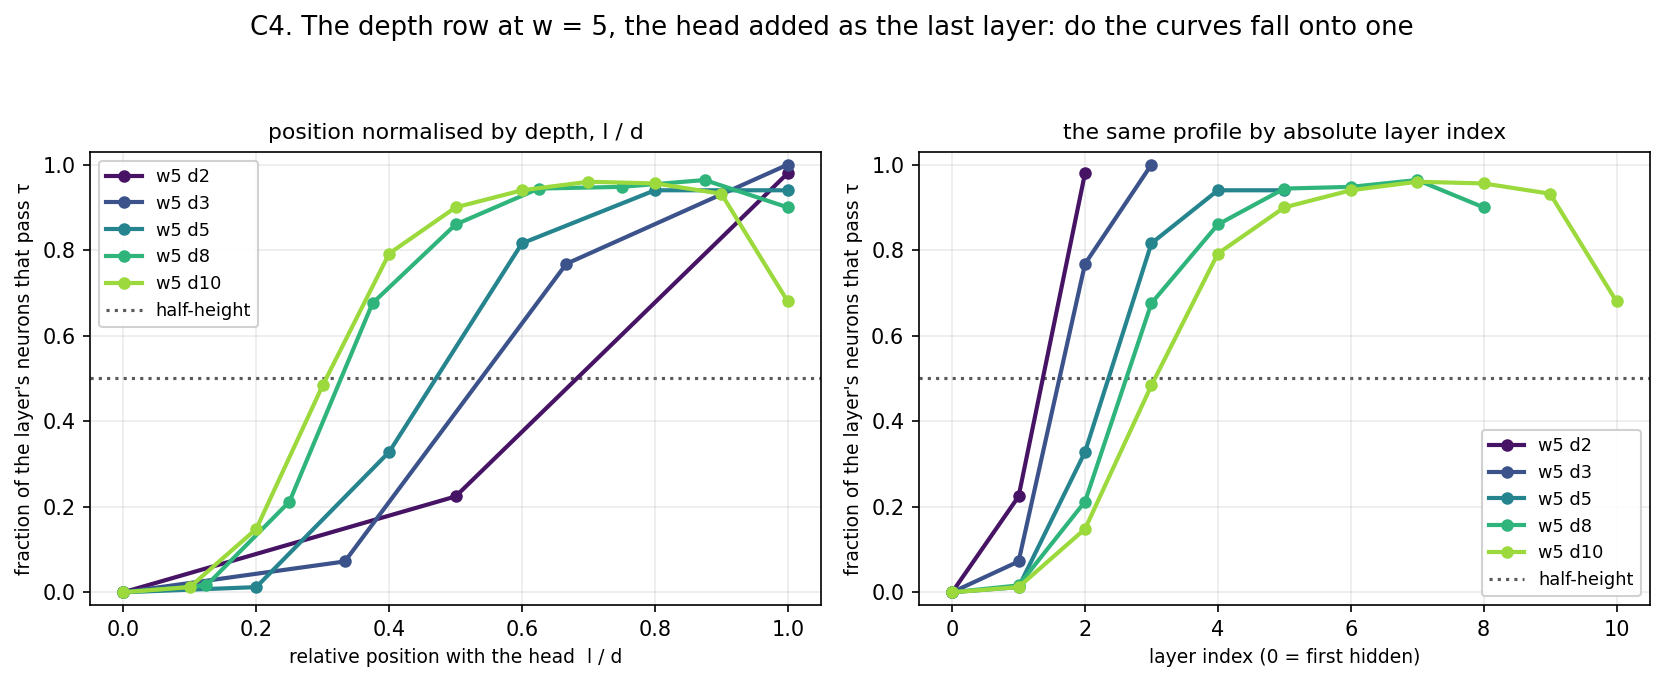

half-height — where the curve crosses 0.5:
  d = 2: layer 1.37, relative position 0.68, layer / √d = 0.97
  d = 3: layer 1.61, relative position 0.54, layer / √d = 0.93
  d = 5: layer 2.35, relative position 0.47, layer / √d = 1.05
  d = 8: layer 2.62, relative position 0.33, layer / √d = 0.93
  d = 10: layer 3.05, relative position 0.31, layer / √d = 0.97

spread between depths (both coordinates now have common ends):
  by relative position: 0.332
  by layer index (0…2): 0.348


In [29]:
# The head becomes the last layer of the DEPTH row at w = 5: position l / d, the first
# hidden layer at 0, the head at 1. The cells of the width row do not enter here — they
# have the same depth 5, and on a common axis they would give several different points at one x.
head_points = (heads_rel[heads_rel.width == 5]
               .groupby(["arch", "width", "depth"])
               .agg(fraction=("witness", "mean")).reset_index())
head_points["layer_id"] = head_points["depth"]
head_points["rel_pos_head"] = 1.0
COLS = ["arch", "width", "depth", "layer_id", "rel_pos_head", "fraction"]
with_head = pd.concat([prof_depth[COLS], head_points[COLS]],
                      ignore_index=True).sort_values(["depth", "layer_id"])
with_head.to_csv(AGG / "layer_profile_with_head.csv", index=False)

ap.plot_layer_profiles([
    dict(title="position normalised by depth, l / d", profile=with_head,
         x="rel_pos_head", by="depth", hline=(0.5, "half-height"), hline_colour="0.35"),
    dict(title="the same profile by absolute layer index", profile=with_head,
         x="layer_id", by="depth", hline=(0.5, "half-height"), hline_colour="0.35"),
], suptitle="C4. The depth row at w = 5, the head added as the last layer: "
            "do the curves fall onto one",
   save_path=FIG / "C4_profile_with_head.png")
show(FIG / "C4_profile_with_head.png")

print("half-height — where the curve crosses 0.5:")
half = []
for d, g in with_head.groupby("depth"):
    x, y = g.layer_id.to_numpy(float), g.fraction.to_numpy(float)
    lay = float(np.interp(0.5, y, x))
    rel = float(np.interp(0.5, y, g.rel_pos_head.to_numpy(float)))
    half.append({"depth": int(d), "half_rise_layer": lay, "half_rise_rel": rel,
                 "layer_over_sqrt_depth": lay / np.sqrt(d)})
    print(f"  d = {d}: layer {lay:.2f}, relative position {rel:.2f}, "
          f"layer / √d = {lay / np.sqrt(d):.2f}")
pd.DataFrame(half).to_csv(AGG / "half_rise.csv", index=False)

grid = np.linspace(0, 1, 21)
rel_spread = np.array([np.interp(grid, g.rel_pos_head, g.fraction)
                       for _, g in with_head.groupby("depth")])
abs_common = np.array([[float(np.interp(k, g.layer_id, g.fraction)) for k in (0, 1, 2)]
                       for _, g in with_head.groupby("depth")])
print(f"\nspread between depths (both coordinates now have common ends):")
print(f"  by relative position: {(rel_spread.max(0) - rel_spread.min(0)).mean():.3f}")
print(f"  by layer index (0…2): {(abs_common.max(0) - abs_common.min(0)).mean():.3f}")

### What C4 shows

**The curves do not fall onto one — in either coordinate.** Now the comparison is legitimate: all five curves
have a common domain and common ends. The spread between depths: **0.332** by relative position and **0.348**
by layer index. Both quantities are large, and the relative one wins only slightly.

**The order of the curves in the two coordinates is opposite, and both are right.** By layer index the shallow
network is ahead (on layer 1: 0.224 at `d = 2` against 0.012 at `d = 10`). By relative position it is the other
way round, the deep one is ahead (at the point 0.5: 0.900 at `d = 10` against 0.224 at `d = 2`). There is no
contradiction: a shallow network has no slack and has to start at once, but by its middle it manages to pass
only one transformation, while a deep one passes five.

**The half-height is the quantity that reconciles this.** The point where the profile crosses 0.5:

| depth | 2 | 3 | 5 | 8 | 10 |
|---|---|---|---|---|---|
| layer index | 1.37 | 1.61 | 2.35 | 2.62 | **3.05** |
| relative position | 0.68 | 0.54 | 0.47 | 0.33 | **0.31** |
| **layer / √d** | 0.97 | 0.93 | 1.05 | 0.93 | **0.97** |

Neither is constant: as depth grows fivefold, the absolute half-height grows 2.2-fold and the relative one
falls 2.2-fold — symmetrically, i.e. the truth is exactly in the middle. Halfway between "a constant layer" and
"a constant fraction" lies **the square root**, and the five measurements agree with it: `layer / √d` stays
within 0.93–1.05.

**The rule has been checked outside the range on which it was noticed.** If one estimates it from the four
depths up to the eighth, then `d = 10` predicts the half-height at layer `√10 ≈ 3.16`; **3.05** is observed, and
the new point falls inside the previous spread without widening it. Five points are still too few to call this a
law, but it is no longer a fit to the existing data.

**A practical consequence for the whole experiment.** Statements of the form "on layer 2 the fraction is such
and such" transfer only within one depth. The profile of experiment 1, taken at `d = 5`, does not apply to
networks of a different depth — and this is exactly the check for which a separate part E existed.

---

### C5. How many neurons of one layer witness the circle

A question moved from B, where it stood as "one neuron for the whole network" and in that form was
contradictory: if a witness is unique and sits on layer `l`, then there is no feature deeper and the head does
not use it. Here it is posed more broadly and without a hypothesis: **how the number of witnesses within a layer
is arranged and what happens to it on passing to the next layer.**

The dataset is **`simple_relevant`**; on `simple_irrelevant` there is nothing to count, there are four witnesses
in the whole pool and all four are examined in A. Layer 0 and widths ≤ 2 are excluded: a closed level curve is
impossible there by the theorem, and zero would be an identity, not a measurement.

**What is in the picture, row by row.** One panel is one architecture. **A row is a layer. A column is how many
neurons of this layer passed `τ`**, from zero on the left to the whole layer on the right. **The colour of a
cell is the fraction of models** (out of fifty) that have exactly that many witnesses in this layer; percentages
are written in the cells where the panel allows. Each row sums to one, so the rows are comparable with each
other, even though the layers witness with different frequency.

**Why row by row and not one histogram per architecture.** The layers stacked together give a bimodal mush whose
modes belong to **different rows**; from such a picture nothing can be said except that both empty and full
occur. The decomposition into rows shows which mode comes from where and what stands between them.

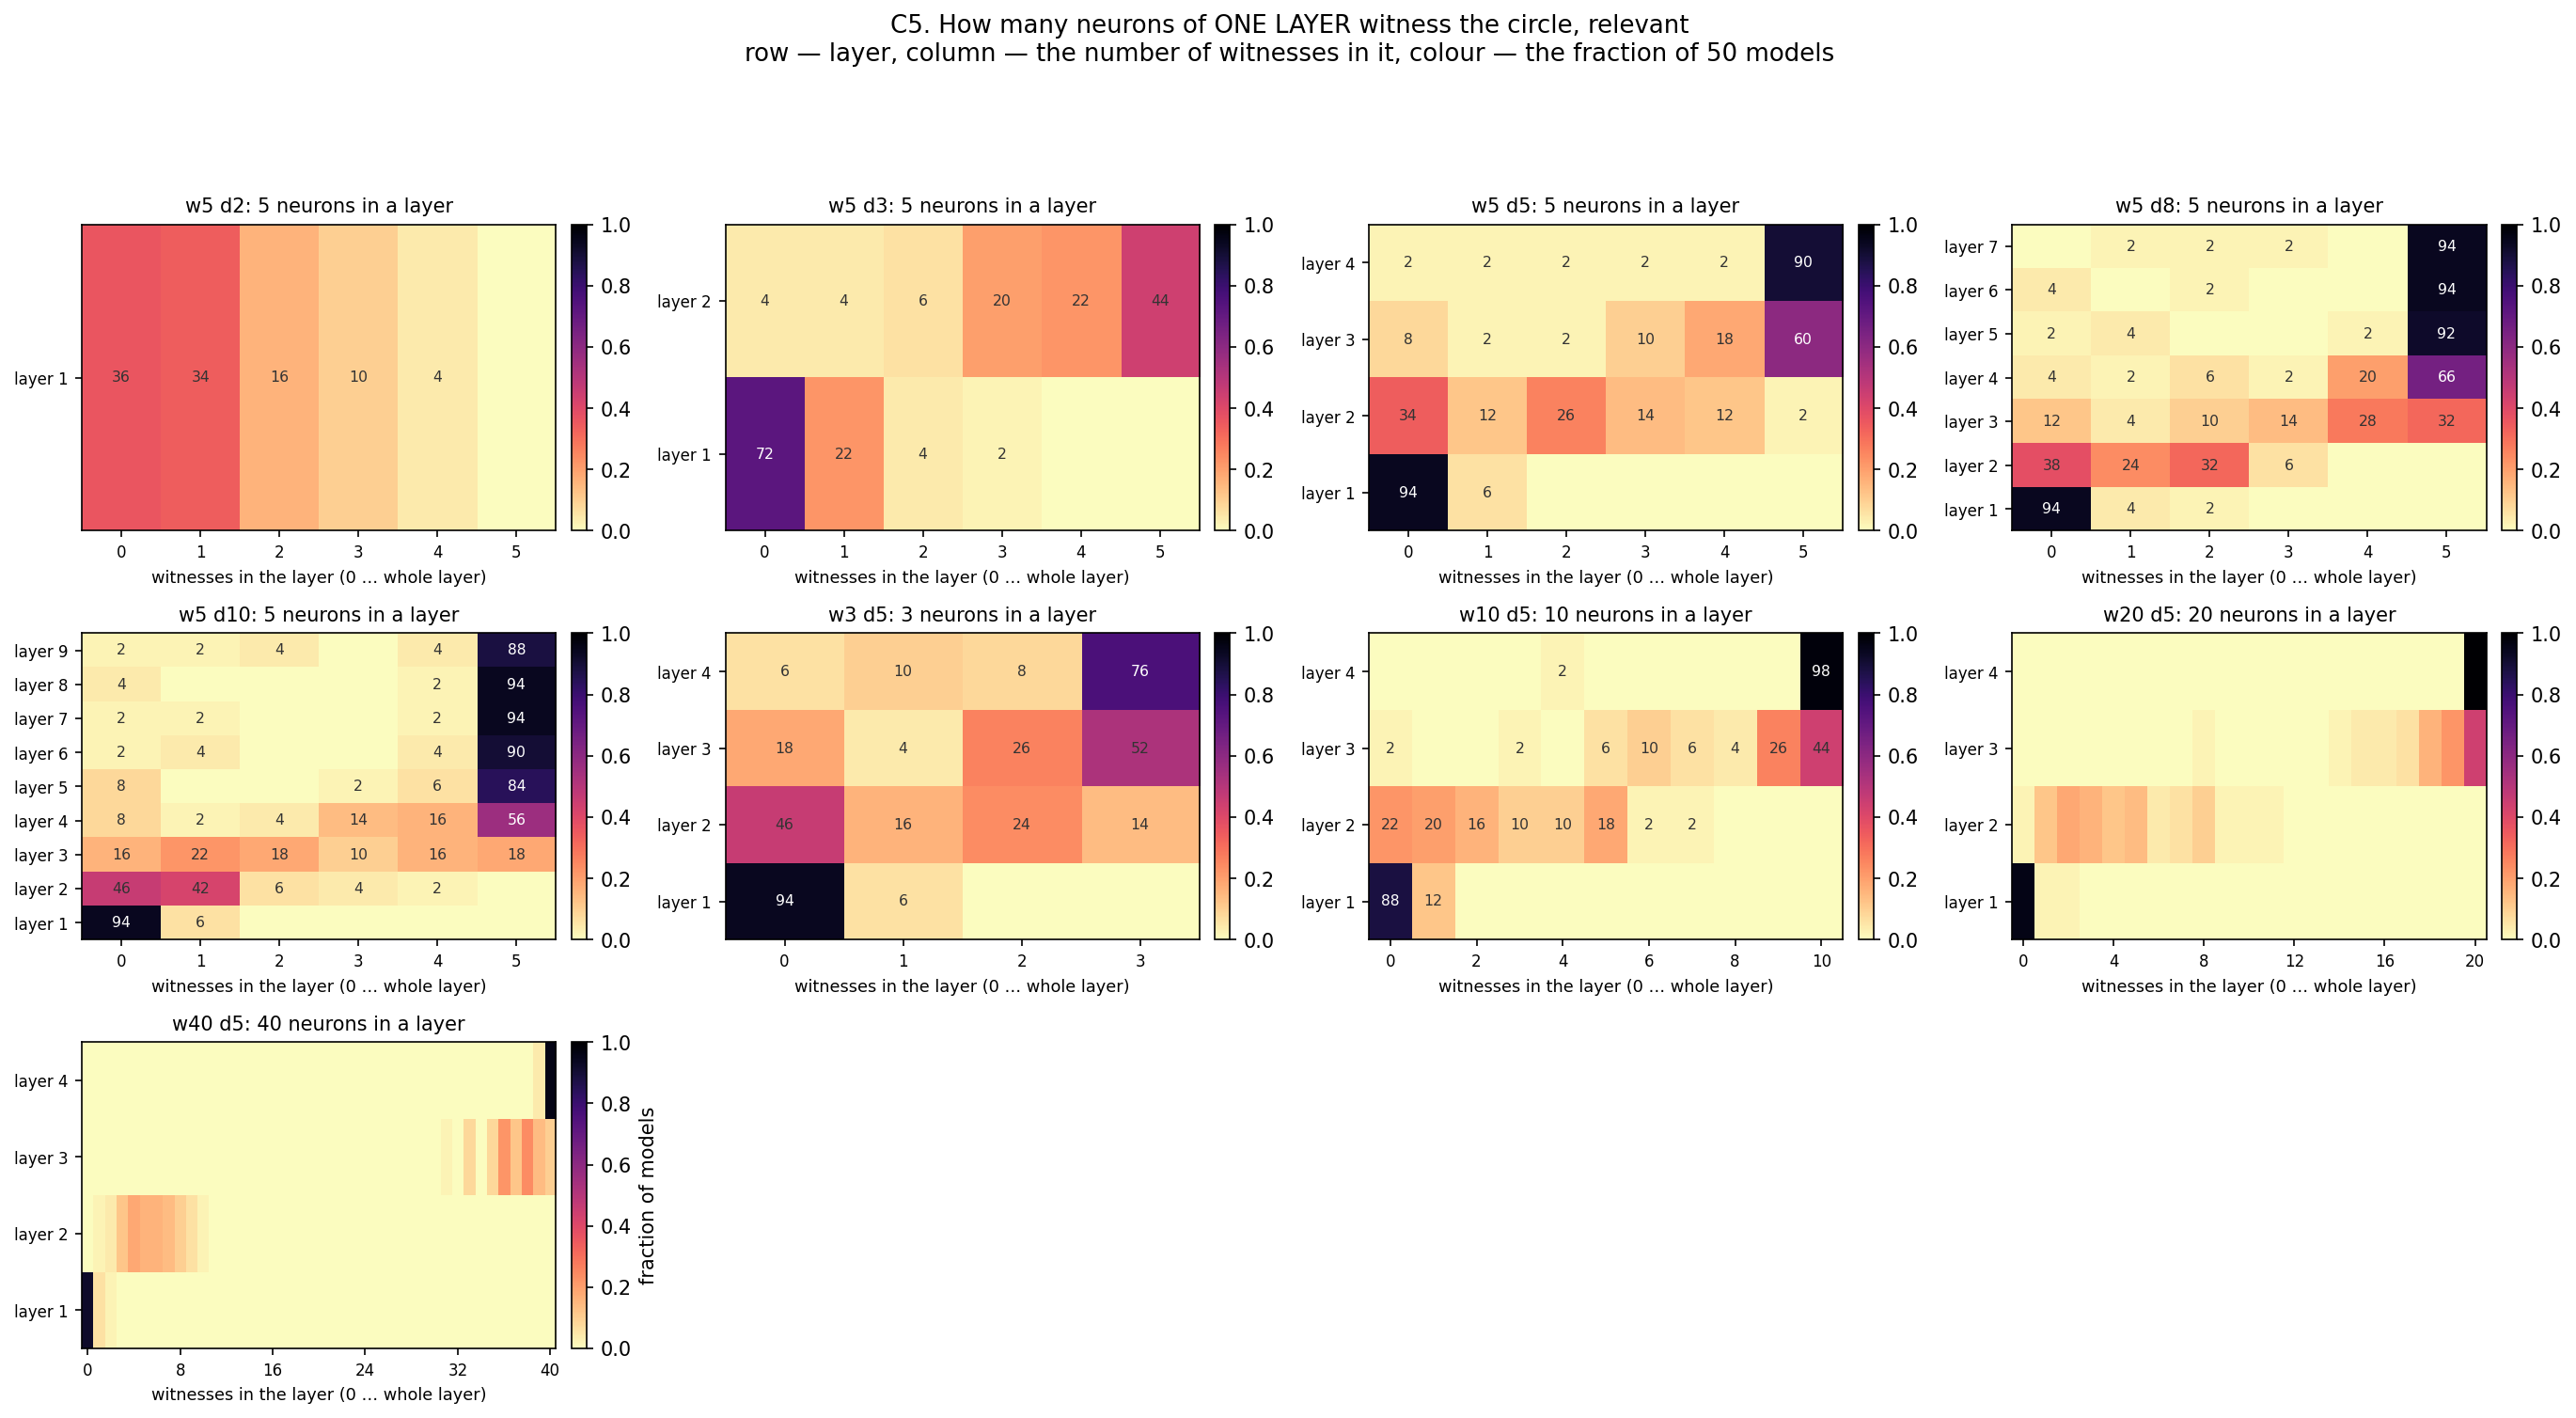

the depth row at w = 5, the fraction of models with an EMPTY layer → with a FULL layer, by layer:
  w5 d2:  empty 0.36
          full  0.00
  w5 d3:  empty 0.72 0.04
          full  0.00 0.44
  w5 d5:  empty 0.94 0.34 0.08 0.02
          full  0.00 0.02 0.60 0.90
  w5 d8:  empty 0.94 0.38 0.12 0.04 0.02 0.04 0.00
          full  0.00 0.00 0.32 0.66 0.92 0.94 0.94
  w5 d10:  empty 0.94 0.46 0.16 0.08 0.08 0.02 0.02 0.04 0.02
          full  0.00 0.00 0.18 0.56 0.84 0.90 0.94 0.94 0.88

the fraction of (model, layer) pairs with EXACTLY ONE witness:
  w5 d2  : 0.340
  w5 d3  : 0.130
  w5 d5  : 0.055
  w5 d8  : 0.057
  w5 d10 : 0.089
  w3 d5  : 0.090
  w10 d5 : 0.080
  w20 d5 : 0.035
  w40 d5 : 0.020

the median number of witnesses in a layer, by architecture:
  w5 d2   (width  5): 1
  w5 d3   (width  5): 0 4
  w5 d5   (width  5): 0 2 5 5
  w5 d8   (width  5): 0 1 4 5 5 5 5
  w5 d10  (width  5): 0 1 2 5 5 5 5 5 5
  w3 d5   (width  3): 0 1 3 3
  w10 d5  (width 10): 0 2 9 10
  w20 d5  (width

In [30]:
# The dataset here and to the end of the part is simple_relevant. On simple_irrelevant there
# is nothing to count: there are four witnesses in the whole pool, and all four are examined in A.
lc = aw.layer_counts(df, REL, ALL_C)
lc.to_csv(AGG / "layer_witness_counts.csv", index=False)

ap.plot_layer_multiplicity(lc, [f"w{w} d{d}" for w, d in ALL_C], ncols=4,
    title="C5. How many neurons of ONE LAYER witness the circle, relevant\n"
          "row — layer, column — the number of witnesses in it, colour — the fraction of 50 models",
    save_path=FIG / "C5_layer_multiplicity.png")
show(FIG / "C5_layer_multiplicity.png")

print("the depth row at w = 5, the fraction of models with an EMPTY layer → with a FULL layer, by layer:")
for w, d in D_ROW_C:
    b = lc[lc.arch == f"w{w} d{d}"]
    empty = [f"{(g['count'] == 0).mean():.2f}" for _, g in b.groupby("layer_id")]
    full = [f"{(g['count'] == w).mean():.2f}" for _, g in b.groupby("layer_id")]
    print(f"  w{w} d{d}:  empty {' '.join(empty)}\n"
          f"          full  {' '.join(full)}")

print("\nthe fraction of (model, layer) pairs with EXACTLY ONE witness:")
for arch in [f"w{w} d{d}" for w, d in ALL_C]:
    b = lc[lc.arch == arch]
    print(f"  {arch:7s}: {(b['count'] == 1).mean():.3f}")

print("\nthe median number of witnesses in a layer, by architecture:")
for arch in [f"w{w} d{d}" for w, d in ALL_C]:
    b = lc[lc.arch == arch]
    med = [f"{g['count'].median():.0f}" for _, g in b.groupby("layer_id")]
    print(f"  {arch:7s} (width {int(b.width.iat[0]):2d}): {' '.join(med)}")

### What C5 shows

**From layer to layer the distribution flows from left to right.** An early layer is empty in almost all
models, a late one is full in almost all, and between them stands a layer with a widely smeared number of
witnesses. At `w40 d5` this is seen best: layer 1 is empty in almost all models, in layer 2 the median is 5 out
of forty, layer 3 gives a median of 37, layer 4 — **all forty**. Within each individual row there is one mode;
only the result of adding the rows looks bimodal, and that is exactly why a pooled histogram is useless here.

**The flow has its own length, and in deep networks it ends in the middle.** The fraction of models in which the
layer is full, by layer:

| | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| `w5 d5` | 0.00 | 0.02 | 0.60 | 0.90 | | | | | |
| `w5 d8` | 0.00 | 0.00 | 0.32 | 0.66 | **0.92** | **0.94** | **0.94** | | |
| `w5 d10` | 0.00 | 0.00 | 0.18 | 0.56 | 0.84 | 0.90 | **0.94** | **0.94** | **0.88** |

At `d = 5` the process runs to the very last hidden layer. At `d = 8` it ends at layer 5, at `d = 10` at layer
6–7, and after that it does not just stop but **turns back**: on the last layer there are fewer full models
(0.94 → 0.88).

**This is not a ceiling of the measurement.** The fraction "the layer is full" runs into one and could freeze
just because of that — but the threshold-free quantity from C2 behaves the same way: the median score of the
layer's neurons at `w5 d10` goes 0.108 → 0.057 → 0.049 → 0.047 → 0.048 → **0.052 → 0.057**, i.e. it stops
improving after the fifth layer and gets worse on the last two. What freezes is not the ruler but the process
itself.

**What this says about the task.** Building the circle costs the network about **four transformations** — and
this is a property of the task, not of the network's depth. If there are exactly that many layers, the feature
is assembled up to the last layer; if there are more, it is assembled in the same four, and the remaining layers
**carry it and spoil it bit by bit**. Extra depth is not spent on this feature and does not improve it: the
quality of the best neuron goes 0.0349 → 0.0410 → 0.0424 at `d = 5, 8, 10`, and the network's head
94% → 90% → **68%**.

Hence also **a refinement of conclusion B about depth**, and a non-trivial one. The fraction of witnesses over
the whole network is by definition the mean of the per-layer fractions: at `d = 5` the mean of
`0, 0.012, 0.328, 0.816, 0.940` is 0.419, at `d = 8` 0.578, at `d = 10` 0.612, and all three coincide with the
numbers of part B. But since the per-layer curve reaches a shelf, a deep network has **more layers standing
after the construction has finished**, and all of them enter the mean close to one. So depth raises the
fraction not because the feature is singled out better but because it is held longer. Statement B "depth is
stronger than width" remains true as a measurement and changes its meaning: it is a statement about the
**extent** of the feature in the network, not about its quality.

**The multiplicity near the output must not be read as "forty independent encoders".** In `simple_relevant`
the decision boundary is the circle, and the last hidden layer must be almost linearly separable, that is,
each of its neurons is close to the decision function itself — and its level curve is the target. The fullness
of the last layer is therefore almost forced by the task. The substantive multiplicity is the one at the break,
where there is no such forcing.

---

### C6. Monotonicity within a model and continuity as a filter of false positives

Two questions of one nature: both ask not "how many witnesses are on layer `l`" but **what happens to the
feature on passing to the next layer**, and both are computed one model at a time.

**The first is monotonicity.** All the curves above are averaged over the ensemble, and a mean curve can grow
even when half of the models have a dip. So we print the fraction of models in which the number of witnesses
does not fall **even once** on passing to the next layer, and the worst dip.

**The second is the filter.** The network's output is assembled from the **last** hidden layer. If a feature is
singled out on layer `l` and no deeper layer carries it, the head cannot read it there — so this role of the
network was not needed, and such a firing is **a candidate false positive**, on grounds in no way connected to
`τ`.

**Two versions of the definition, and both are worth computing.**

* **Without the head.** A witness is flagged if in the same model there is no witness on any deeper hidden layer
  **and** it is not itself in the last hidden layer. The second condition is forced: a witness of the last layer
  has nothing "deeper" by construction, and flagging it for that would be a mistake — but because of this 41% of
  the witnesses fall out of the filter's reach altogether.
* **With the head.** The head (C3) is also a layer, and then the caveat is not needed: "is there a witness
  deeper" is defined the same way for all layers.

**How we check that the filter catches anything at all.** We have a set of firings known to be doubtful — four
neurons that crossed `τ` on the **irrelevant** circle (part A) — and a set that there is no reason to consider
false: the witnesses of the relevant circle. A good filter has to separate them.

In [31]:
# First monotonicity: does the profile grow WITHIN a model, not only on average.
mono = aw.profile_monotonicity(df, REL, ALL_C)
mono.to_csv(AGG / "profile_monotonicity.csv", index=False)
print("the number of witnesses never falls on passing to the next layer:")
for r in mono.itertuples():
    print(f"  {r.arch:7s}: {r.monotone_share:5.0%} of models, worst dip {r.worst_drop}")

# Then the filter. Both versions are computed on ONE set of cells — those where the
# head was measured. Otherwise the "with the head" version would flag everything that simply was not computed.
scope = {REL: [f"w{w} d{d}" for w, d in ALL_C],
         IRR: [f"w{w} d{d}" for w, d in IRR_HEAD_CELLS]}

parts = []
for ds, name in ((REL, "relevant"), (IRR, "irrelevant")):
    f = aw.continuity_filter(df, ds)
    f = f[f.arch.isin(scope[ds])]
    if len(f):
        parts.append(f.assign(dataset=name))
filt = pd.concat(parts, ignore_index=True)

# With the head, "deeper" is finally defined for the last hidden layer.
head_witness = heads.set_index("model_path")["witness"]
filt["head_witnesses"] = filt["model_path"].map(head_witness)
assert filt["head_witnesses"].notna().all(), "the head was not computed for all models of the scope"
filt["flagged_with_head"] = np.where(filt["is_last_layer"],
                                     ~filt["head_witnesses"], filt["flagged"])
filt.to_csv(AGG / "continuity_filter.csv", index=False)

summary = (filt.groupby(["dataset", "arch"])
           .agg(witnesses=("flagged", "size"), flagged=("flagged", "sum"),
                fraction=("flagged", "mean"),
                with_head=("flagged_with_head", "sum"),
                fraction_with_head=("flagged_with_head", "mean"))
           .reset_index())
summary.to_csv(AGG / "continuity_filter_rates.csv", index=False)
print()
for name, g in filt.groupby("dataset"):
    print(f"{name:11s}: witnesses {len(g):5d} in {g.arch.nunique()} cells; "
          f"flagged without the head {int(g.flagged.sum()):3d} ({g.flagged.mean():.2%}), "
          f"with the head {int(g.flagged_with_head.sum()):3d} "
          f"({g.flagged_with_head.mean():.2%}); "
          f"in the last hidden layer {g.is_last_layer.mean():.1%}")
print()
display(summary[summary["flagged"] + summary["with_head"] > 0])

print("all flagged ones (the version without the head), by name:")
flagged = filt[filt.flagged].copy()
flagged["model"] = flagged.model_path.str.split("_").str[-1]
display(flagged[["dataset", "arch", "model", "layer_id", "coord_id", "score",
                 "deepest_witness_layer", "head_witnesses"]]
        .sort_values(["dataset", "arch", "layer_id"]))

the number of witnesses never falls on passing to the next layer:
  w5 d2  :  100% of models, worst dip 0
  w5 d3  :  100% of models, worst dip 0
  w5 d5  :  100% of models, worst dip 0
  w5 d8  :   96% of models, worst dip 1
  w5 d10 :   82% of models, worst dip 3
  w3 d5  :   98% of models, worst dip 3
  w10 d5 :  100% of models, worst dip 0
  w20 d5 :  100% of models, worst dip 0
  w40 d5 :  100% of models, worst dip 0



irrelevant : witnesses     7 in 2 cells; flagged without the head   7 (100.00%), with the head   7 (100.00%); in the last hidden layer 0.0%
relevant   : witnesses 11073 in 9 cells; flagged without the head   4 (0.04%), with the head 100 (0.90%); in the last hidden layer 41.3%



,dataset,arch,witnesses,flagged,fraction,with_head,fraction_with_head
0,irrelevant,w20 d5,4,4,1.000000,4,1.000000
1,irrelevant,w40 d5,3,3,1.000000,3,1.000000
4,relevant,w3 d5,289,3,0.010381,13,0.044983
6,relevant,w5 d10,1531,1,0.000653,64,0.041803
7,relevant,w5 d2,56,0,0.000000,1,0.017857
9,relevant,w5 d5,524,0,0.000000,4,0.007634
10,relevant,w5 d8,1155,0,0.000000,18,0.015584


all flagged ones (the version without the head), by name:


,dataset,arch,model,layer_id,coord_id,score,deepest_witness_layer,head_witnesses
11074,irrelevant,w20 d5,model18,1,13,0.091127,1,False
11075,irrelevant,w20 d5,model40,1,11,0.091215,1,False
11076,irrelevant,w20 d5,model42,1,12,0.078018,1,False
11073,irrelevant,w20 d5,model17,2,14,0.093922,2,False
11077,irrelevant,w40 d5,model1,1,38,0.098821,1,False
11078,irrelevant,w40 d5,model20,1,28,0.082603,1,False
11079,irrelevant,w40 d5,model24,1,31,0.082174,1,False
3400,relevant,w3 d5,model43,3,0,0.085992,3,False
3401,relevant,w3 d5,model43,3,1,0.091961,3,False
3402,relevant,w3 d5,model43,3,2,0.092259,3,False


### What C6 shows

**The profile grows not only on average but also within a model — except for the deepest network.** The number
of witnesses does not fall even once on passing to the next layer in **100%** of models at `d = 2, 3, 5` and at
`w = 10, 20, 40`. Exceptions: 98% at `w3 d5` (the worst dip three neurons), 96% at `w5 d8` (a dip of one) and
**82% at `w5 d10`** (a dip of three). That is, in every sixth ten-layer model the feature retreats somewhere —
and this is the same cell whose curve in C5 turns down towards the last layer. Two independent ways of seeing one
and the same thing.

Next, the filter. Both versions are computed on one set — the nine `relevant` cells and the five `irrelevant`
ones where the head was measured.

| | witnesses | flagged without the head | flagged with the head |
|---|---|---|---|
| relevant | 11,073 | **4 (0.04%)** | 100 (0.90%) |
| irrelevant (`w20 d5` and `w40 d5`) | 7 | **7 (100%)** | 7 (100%) |

**All seven irrelevant firings are flagged by both versions** — including the three new ones added by `w40 d5`.
All of them are on the first two layers; none of these models has a witness on any deeper hidden layer, and the
head does not witness in any of the hundred models of these two cells. That is, the circle is singled out on an
early layer and **goes nowhere further**: the network does not carry it on, because its task does not need it.

This is a third, independent reason to consider these four firings doubtful — in addition to the two that were in
A: three components of seven are clipped by the box, and the best NULL neuron of the whole dataset scores
0.0667 — less than any of the seven.

**The four flagged on relevant are two cases out of eleven thousand witnesses.** Three of them are all the
neurons of layer 3 of the model `w3 d5 model43`, with scores 0.086, 0.092, 0.092: in it layer 4 does not witness at
all, and the head does not reach `τ` either (0.106). The fourth is a single neuron of layer 6 of the model
`w5 d10 model12`. Both cases are models that **singled the circle out and lost it**, and both stand where the
other anomalies live: at the minimal width and at the maximal depth. The version without the head gives not a
single flag at width five and above and depth up to eight.

**The version with the head is stricter, but it flags something else.** It raises the number from 4 to 100, and
**64 of these hundred fall on one cell, `w5 d10`** — simply because there the head witnesses in only 68% of the
models, and the witnesses of the last hidden layer in the remaining 32% end up flagged. And from C3 it is known
that all such misses are borderline: 0.101–0.180 against a threshold of 0.1. That is, the version with the head
mostly answers the question "did the output squeeze under the threshold", not "is the feature carried further".
This does not prevent it from separating our two sets — 100% against 0.9% — but as a filter it mixes two
different grounds, and from here on the version without the head is the one worth using.

**Three caveats without which the filter cannot be put to work.**

1. **This is a necessary condition, not a sufficient one.** A feature can be linearly decodable from the last
   layer without being anyone's level curve there. An unflagged witness is therefore not "confirmed" — it is only
   not refuted in this way.
2. **The separation is partly tautological.** On `simple_irrelevant` the head does not witness in any model — by
   the construction of the dataset, where the decision boundary runs elsewhere. A real check requires a case
   where an irrelevant feature does get a witness deep down or at the head; in this pool there is no such case —
   even at two hundred neurons, where there are firings, all of them are on the first two layers.
3. **The test set has four elements.** The separation is clean, but the sample size does not allow speaking about
   the filter's error rate.

## Summary of C

Let me recall what is called a **profile** here: the dependence of a characteristic of witnessing on the index of
the hidden layer at a fixed architecture and a fixed feature. There were three characteristics — the fraction of
the layer's neurons that pass `τ`; the median score of the layer's neurons; the fraction of neurons with a
homological verdict.

**1. The feature is built gradually, from the input to the output.** The profile grows at all depths and widths —
except `d = 10`, where on the last two layers it goes down (0.960 → 0.956 → 0.932). And this is not an artefact of
averaging: within a model the number of witnesses does not fall even once in 96–100% of models — except
`w5 d10`, where such models are 82%. What grows meanwhile is not the tail but the whole population of the layer:
the median score falls by an order of magnitude and goes below `τ` earlier than the fraction reaches a half. The
floor and the irrelevant circle have no profile at all (maxima of 0.0040 and 0.0030), so this is not a general
property of "deeper — more curved".

**2. A shallow network has to start earlier, a wide one can postpone.** On the first hidden layer the fraction is
the higher, the smaller the depth (0.224 at `d = 2` against 0.012 at `d = 10`), and the score there is noticeably
better too. Along width the same holds in mirror image: on layer 2 the fraction falls as width grows (0.353 → 0.136
from `w3` to `w40`), on the last one it grows to one. The common explanation is one — **slack**: a network without
slack has no choice of when to single out the feature, a network with slack has one. This is an interpretation, not
a measurement; these data cannot distinguish "chose not to" from "could not".

**3. A closed level curve appears earlier than it becomes the circle.** The homological criterion consistently runs
ahead of the structural one, and the gap is largest exactly at the break: at `d = 5` on layer 2 a loop is present in
66% of neurons, while 33% go around the target. The two criteria here do not duplicate each other but separate
two different events.

**3b. On the last layers the two criteria diverge.** At `d = 10` the structural fraction falls towards the end
(0.960 → 0.956 → 0.932), while the homological one grows to one (0.976 → 0.996 → 1.000); at no depth does the
homological curve dip anywhere. So the closed level curves on deep layers do not disappear — there become more of
them — but their **geometry** changes: they stop resembling our circle while continuing to solve the task. What
exactly they become is not measured here.

**4. The network output witnesses the circle on the relevant dataset and does not witness it on the irrelevant one**
— 68–100% of models against zero out of two hundred and fifty, and the separation is not borderline: the worst
relevant output is 0.180, the best irrelevant one 0.387. All thirty-four misses lie in 0.101–0.180 with the median
of the hits at 0.047. The weak cells are `w5 d10` (68%) and `w3 d5` (82%), i.e. the maximal depth and the minimal
width. The choice of output scale — the sigmoid against the raw logit — changes the fraction by no more than three
models out of fifty.

**5. The break of the profile stands at about layer √d.** Neither the absolute layer index nor the fraction of depth
describes the profile: as depth grows fivefold, the half-height grows 2.2-fold by layer index and falls 2.2-fold by
relative position, while `layer / √d` stays within 0.93–1.05 at all five depths. The rule was noticed at depths up
to eight and confirmed at the tenth (prediction 3.16, observation 3.05), i.e. it is no longer a fit to the existing
points. **The transfer rule follows directly: statements about a specific layer are valid only within the depth at
which they were measured**, and the profile of experiment 1 (`d = 5`) does not extend to other depths.

**6. The number of witnesses in a layer flows from zero to the full layer, the construction has its own length, and
after it the flow turns back.** An early layer is empty in almost all models, a late one is full in almost all,
between them is a layer with a widely smeared number. The flow
takes about **four transformations**: at `w5 d5` it runs to the last layer, at `w5 d8` it ends at the fifth, at
`w5 d10` at the sixth or seventh, and after that the fraction of full layers **falls** (0.94 → 0.88), while the
median score grows. Hence **a refinement of part B**: the fraction of witnesses over the whole network is by
definition the mean of the per-layer fractions, so in a deep network it is higher not because the feature is singled
out better but because more layers stand after saturation. Depth increases the **extent** of the feature in the
network, not its quality — which agrees both with the worse best neuron at `d = 8, 10` in B and with the worse head
at `d = 10`.

**7. Continuity across layers works as a filter of false positives.** A witness for which there is no witness deeper
in the same model and which is not itself in the last layer is flagged as a candidate false positive. The filter flags
**all seven** firings on the irrelevant circle — including the three new ones added by `w40 d5` — and **four out of
11,073** on
the relevant one, and these four are two cases: all the neurons of one layer of a model of minimal width and one
neuron of a model of maximal depth; both singled the circle out and lost it. The filter requires neither new
computation nor a threshold, and does not depend on `τ`.

---

### What C does not show

* **Nothing about necessity.** "The whole last layer witnesses" is observed multiplicity, not a claim that all these
  neurons are needed. The causal question requires ablation.
* **A high fraction at the output is weak evidence of encoding.** The last hidden layer must be almost linearly
  separable, and the decision boundary here is the target, so witnessing there is close to being forced by the task.
  The middle layers are the informative ones.
* **"The length of the construction ≈ 4 layers" rests on three depths at one width.** Saturation is visible only
  where the depth exceeds this length, and there are two such cells in the pool — `w5 d8` and `w5 d10`.
* **The filter from C6 has been checked on one test set of four elements** and under conditions where the separation
  is partly tautological.
* **The `√d` rule rests on five depths** and on one task.

---

# D. Width against depth at an equal budget of neurons

The row `w24 d1`, `w12 d2`, `w8 d3`, `w5 d5`, `w3 d8` — **24–25 neurons in each cell**, only the shape of the
network changes. This is the only place in the experiment where the number of neurons is constant, so any
difference within the row is an effect of arrangement, not of size.

**What is not repeated here.** The fraction of witnesses along this row has already been shown in B5, where it
stands as a control for conclusion B about depth: 0.000 → 0.067 → 0.228 → 0.419 → 0.554. This figure is not drawn
a second time. D asks something else — **what exactly the shape buys**, and whether it buys the same thing for all
quantities.

**Why the row has a separate methodological advantage.** The gate stops training at the first stable 100%
accuracy, so along any axis of architectures the training duration changes too: in the width row of task B it goes
124 → 13 epochs, 9.5-fold. In the equal-budget row it is almost constant — 59 / 38 / 38 / 41 epochs at `d ≤ 5`. The
only exception, `w3 d8` with 125.5, is examined separately in D2, and examined seriously, because the most
interesting number of the part lies exactly on this cell.

---

### D1. Fraction and quality along the axis of shape

**What we draw.** Two panels against depth (the number of neurons being constant). On the left — the fraction of
neurons that pass `τ`. On the right — the median of the best neuron per model and **the floor of the same cell**;
the scale is logarithmic, the red dashed line is `τ`.

**Why.** Fraction and quality are different questions: "how many neurons picked up the feature" and "how precisely
the best of them does it". The equal-budget row is the only place where one can look at them without correcting for
multiplicity: the number of attempts is fixed, and the floor confirms or refutes this right on the same panel.

The grey band at `w24 d1` is the cell where a witness is impossible by the theorem (the whole network is layer 0).

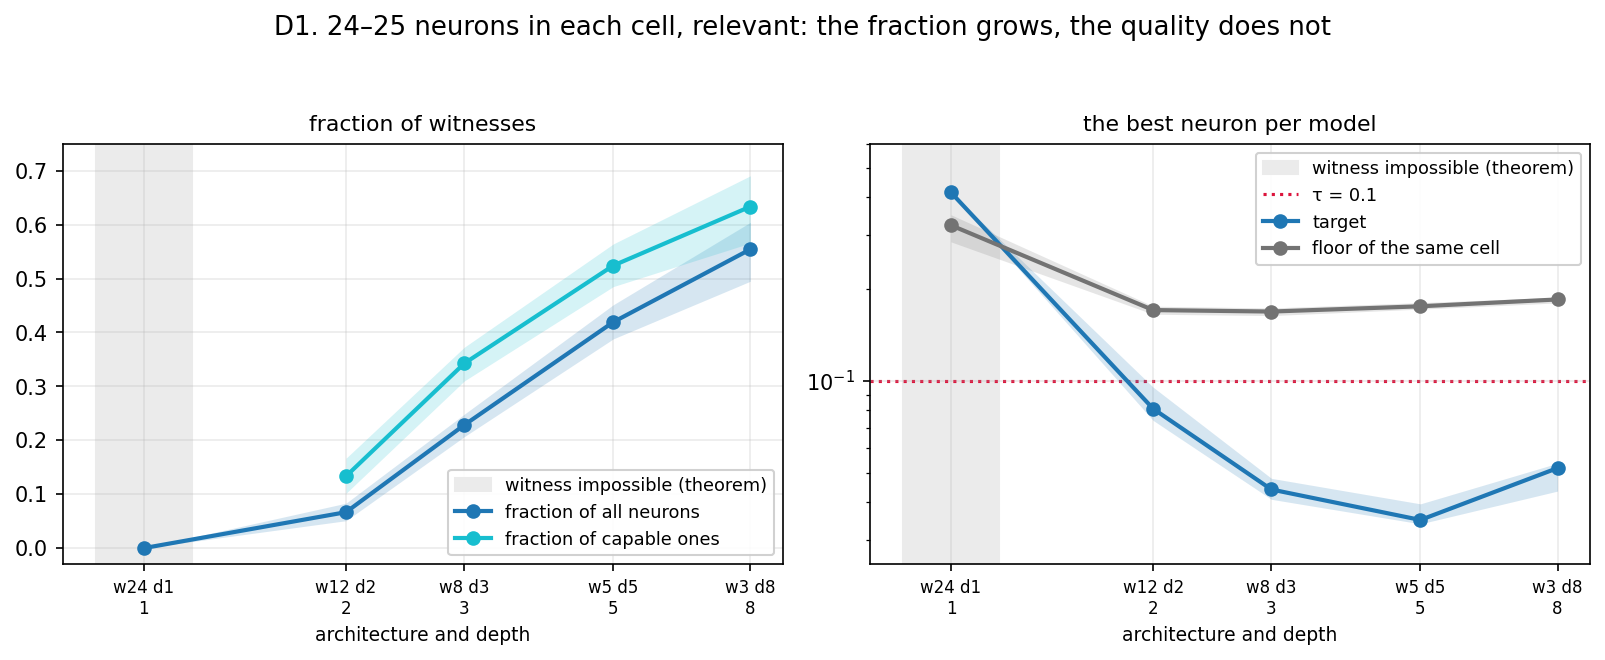

relevant, the equal-budget row:
  w24 d1  fraction 0.0000  best 0.4150 [0.4142, 0.4154]  floor 0.3239  P(has a witness) 0.00
  w12 d2  fraction 0.0667  best 0.0810 [0.0741, 0.0953]  floor 0.1707  P(has a witness) 0.66
  w8 d3   fraction 0.2283  best 0.0440 [0.0408, 0.0479]  floor 0.1688  P(has a witness) 1.00
  w5 d5   fraction 0.4192  best 0.0349 [0.0339, 0.0395]  floor 0.1756  P(has a witness) 0.98
  w3 d8   fraction 0.5542  best 0.0517 [0.0435, 0.0536]  floor 0.1849  P(has a witness) 0.94


In [32]:
BUDGET_ROW = [(24, 1), (12, 2), (8, 3), (5, 5), (3, 8)]
BUDGET_CAP = [(12, 2), (8, 3), (5, 5), (3, 8)]      # without d1: no capable neurons

ap.plot_axis_panels(cells, [
    dict(title="fraction of witnesses", dataset_type=REL, cells=BUDGET_ROW, x="depth",
         series=[("witness_fraction", "fraction of all neurons", "tab:blue"),
                 ("witness_fraction_capable", "fraction of capable ones", "tab:cyan")],
         ylim=(-0.03, 0.75)),
    dict(title="the best neuron per model", dataset_type=REL, cells=BUDGET_ROW, x="depth",
         series=[("median_best", "target", "tab:blue"),
                 ("median_best_null", "floor of the same cell", "0.45")],
         log_y=True, ylim=(0.025, 0.6), hline=(aw.TAU, "τ = 0.1")),
], suptitle="D1. 24–25 neurons in each cell, relevant: the fraction grows, the quality does not",
   save_path=FIG / "D1_budget_fraction_quality.png")
show(FIG / "D1_budget_fraction_quality.png")

b = (cells[cells.dataset_type == REL].set_index("arch")
     .loc[[f"w{w} d{d}" for w, d in BUDGET_ROW]])
print("relevant, the equal-budget row:")
for arch, r in b.iterrows():
    print(f"  {arch:7s} fraction {r.witness_fraction:.4f}  "
          f"best {r.median_best:.4f} [{r.median_best_lo:.4f}, {r.median_best_hi:.4f}]  "
          f"floor {r.median_best_null:.4f}  P(has a witness) {r.p_has_witness:.2f}")

### What D1 shows

**The fraction grows monotonically, the quality does not.** The fraction of witnesses goes 0.000 → 0.067 → 0.228 →
0.419 → 0.554, while the median of the best neuron improves only up to `d = 5` (0.0810 → 0.0440 → **0.0349**) and
at `d = 8` gets worse, to 0.0517. The intervals of `w5 d5` [0.0339, 0.0395] and `w3 d8` [0.0435, 0.0536] do not
overlap, so the dip is not noise. The change of sign repeats in a third quantity too: `P(the model has at least one
witness)` also passes through a maximum — 0.66 → **1.00** → 0.98 → 0.94.

**Multiplicity really is fixed.** The floor at `d ≥ 2` is almost flat: 0.1707, 0.1688, 0.1756, 0.1849. It is the very
check that the number of attempts does not wander along the row — otherwise the talk of an "effect of shape" would
have to be held with a correction.

**The zero at `w24 d1` is a theorem, but its floor is not.** There can be no witness there: the whole network is
layer 0, and the level curves of its neurons are straight lines. But the floor in this cell is 0.3239 straight away,
against 0.17–0.18 in the others, because it too is computed over INCAPABLE neurons. This is not "a hard task", it is a
different population, and it must not be compared with the floors of the neighbouring cells.

**And right away a question without an answer to which D1 cannot be read.** The cell `w3 d8` is the only one in the
row whose training duration stands out: a median of 125.5 epochs against 38–59 for the others, and a maximum of 2346.
That is, the dip in quality at `d = 8` is explained both by depth and by three times longer training, and D1 itself
gives no way of telling them apart.

---

### D2. The same row at a matched training duration

**What we do.** Each cell is taken twice: in full, and only over the models whose gate fired no later than **62
epochs** — a window into which four of the five cells fit entirely. Within the window there is no difference in
duration between cells, and if the order is preserved, it is not about duration.

**What we draw.** The median of the best neuron against depth, two curves: over all models and over the window. The
bands are a bootstrap over models; at `w3 d8` 15 models of 50 fall into the window, so its band is wider, and this is
visible.

**What this check does NOT give.** This is a matched subsample, not an intervention: by selecting models by the gate
epoch we also select by the luck of the initialisation — a slow run is a run that got an unlucky initialisation. So
what we get here is **a bound** on the size of the confound, not its decomposition. Task E separates them, where the
duration changes within one run.

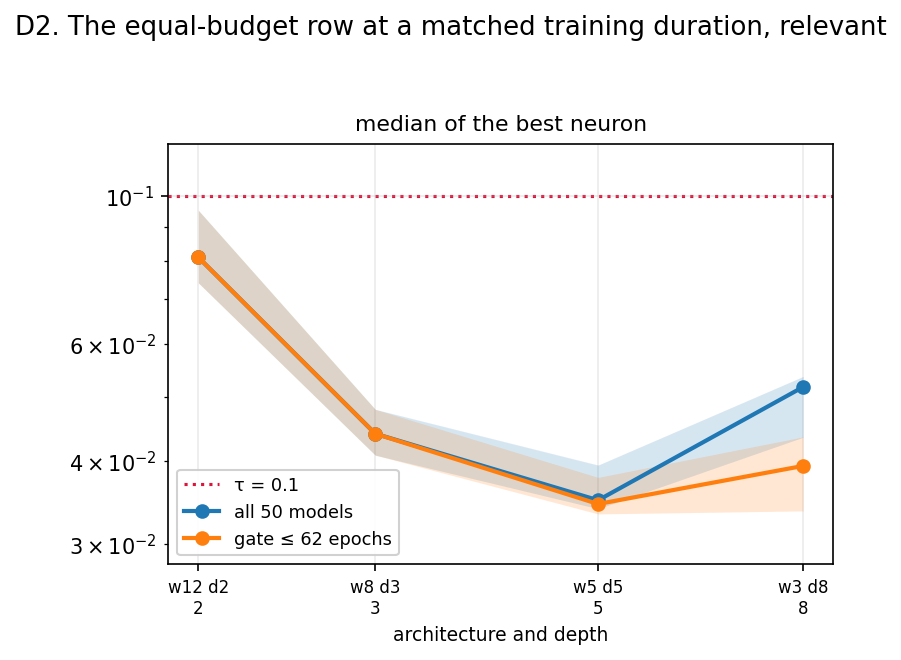

training duration and the result in the window:
  w24 d1  median   59.0 epochs (range 32-113)
  w12 d2  median   38.0 epochs (range 25-61)  |  in the window n=50, best 0.0810 [0.0741, 0.0953], fraction 0.0667
  w8 d3   median   38.0 epochs (range 27-47)  |  in the window n=50, best 0.0440 [0.0408, 0.0479], fraction 0.2283
  w5 d5   median   41.0 epochs (range 25-219)  |  in the window n=39, best 0.0345 [0.0333, 0.0378], fraction 0.4615
  w3 d8   median  125.5 epochs (range 29-2346)  |  in the window n=15, best 0.0394 [0.0337, 0.0435], fraction 0.6861


In [33]:
dm = aw.duration_matched(df, REL, BUDGET_CAP, max_epochs=62, n_boot=2000)
dm.to_csv(AGG / "duration_matched_budget.csv", index=False)

ap.plot_axis_panels(dm, [
    dict(title="median of the best neuron", dataset_type=REL, cells=BUDGET_CAP, x="depth",
         series=[("median_best_all", "all 50 models", "tab:blue"),
                 ("median_best_window", "gate ≤ 62 epochs", "tab:orange")],
         log_y=True, ylim=(0.028, 0.12), hline=(aw.TAU, "τ = 0.1")),
], suptitle="D2. The equal-budget row at a matched training duration, relevant",
   save_path=FIG / "D2_duration_matched.png")
show(FIG / "D2_duration_matched.png")

dur = aw.duration_table(df, REL, BUDGET_ROW)
dur.to_csv(AGG / "budget_row_duration.csv", index=False)
print("training duration and the result in the window:")
for r in dur.itertuples():
    w = dm[dm.arch == r.arch]
    tail = ("" if not len(w) else
            f"  |  in the window n={int(w.n_window.iat[0]):2d}, best "
            f"{w.median_best_window.iat[0]:.4f} "
            f"[{w.median_best_window_lo.iat[0]:.4f}, {w.median_best_window_hi.iat[0]:.4f}], "
            f"fraction {w.fraction_window.iat[0]:.4f}")
    print(f"  {r.arch:7s} median {r.median_epochs:6.1f} epochs "
          f"(range {r.min_epochs}-{r.max_epochs}){tail}")

### What D2 shows

**The dip at `d = 8` does not survive matching.** In the window up to 62 epochs the median of the best for `w3 d8`
falls from 0.0517 to **0.0394 [0.0337, 0.0435]**, while for `w5 d5` it is 0.0345 [0.0333, 0.0378] — the intervals
**overlap**. That is, at a comparable training duration the deepest cell of the row and the reference are
indistinguishable, and "quality gets worse after `d = 5`" cannot be said.

**But the rise up to `d = 5` survives.** `w12 d2` (0.0810) and `w8 d3` (0.0440) fall into the window entirely, their
numbers do not change at all, and both remain noticeably worse than `w5 d5`. So the rise in quality from two layers
to five is not an effect of duration.

**The fraction in the window grows in the same way and even more strongly:** 0.067 → 0.228 → 0.462 → **0.686**.
Selecting the briefly trained models raises it in both deep cells, i.e. long training works against witnessing — but
by how much exactly, this check does not say.

**The final statement of D1 after D2.** At an equal budget depth improves both the fraction and the quality —
monotonically up to `d = 5`. Beyond that **the fraction keeps growing, while the quality reaches a shelf**. This is
exactly what the saturation mechanism from C6 predicts: the construction of the feature takes about four
transformations, after which the extra layers carry it rather than improve it — and therefore add extent but not
sharpness.

---

### D3. The profile by layer outside the cells on which it was built

**What we draw.** The profile of the fraction of witnesses by layer for the equal-budget row (left) and for the depth
row at `w = 5` from part C (right). One and the same depth in the two rows means different widths: at `d = 2` the
budget cell is **wider** than the reference one (12 against 5), at `d = 8` it is **narrower** (3 against 5).

**Why.** Part C built the profile on the depth row at `w = 5` and on the width row at `d = 5`. The equal-budget row
is four cells, none of which was in C. If the mechanism of C is right, it must predict their profile: a narrow network
starts earlier, a wide one ends higher. This is an out-of-sample check, and it is free.

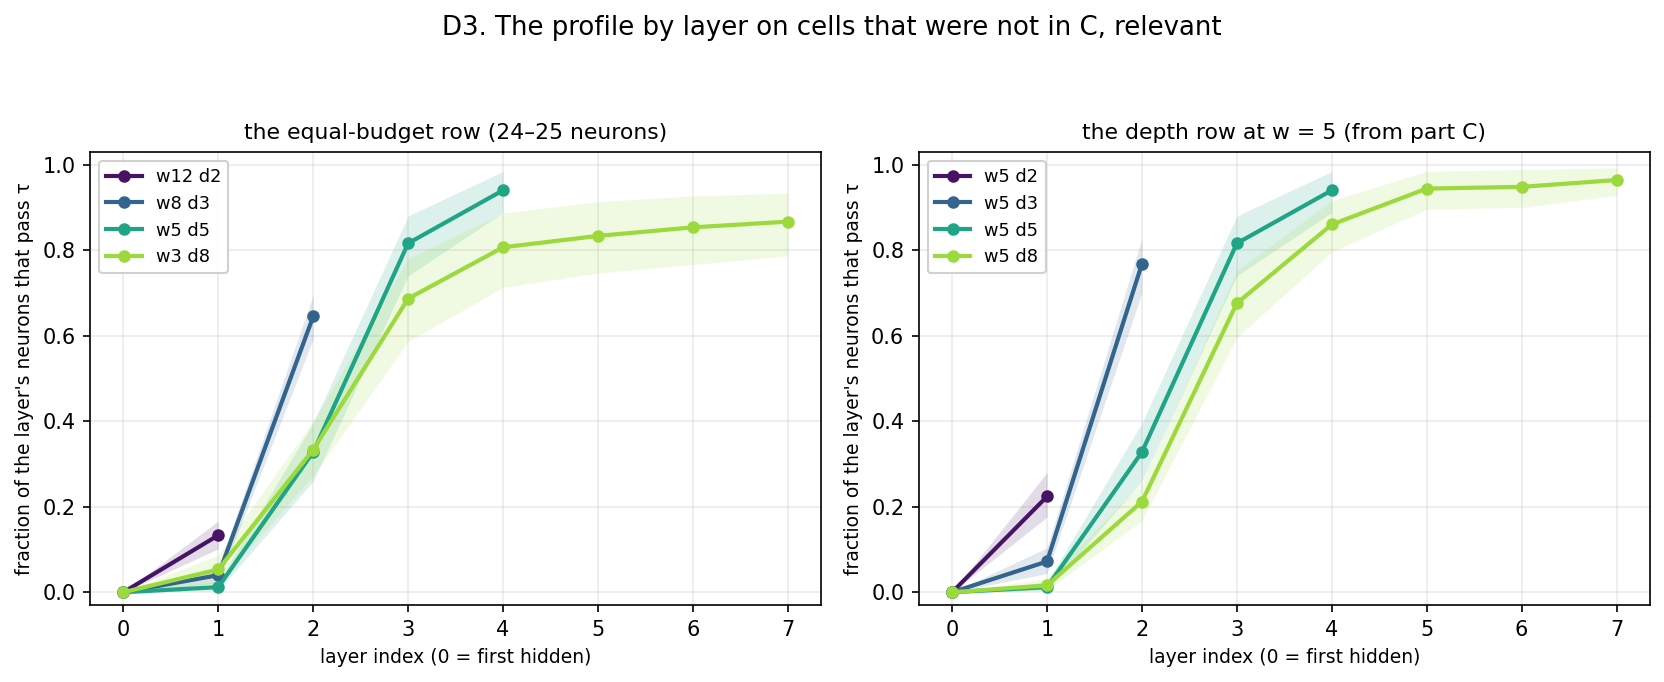

fraction of witnesses by layer (budget  |  w = 5 of the same depth):
  d=2  w12 d2  0.000 0.133
         w5 d2  0.000 0.224
  d=3  w8 d3   0.000 0.040 0.645
         w5 d3  0.000 0.072 0.768
  d=5  w5 d5   0.000 0.012 0.328 0.816 0.940
         w5 d5  0.000 0.012 0.328 0.816 0.940
  d=8  w3 d8   0.000 0.053 0.333 0.687 0.807 0.833 0.853 0.867
         w5 d8  0.000 0.016 0.212 0.676 0.860 0.944 0.948 0.964


In [34]:
prof_budget = aw.layer_profile(df, REL, BUDGET_CAP, n_boot=2000)
prof_w5 = aw.layer_profile(df, REL, [(5, 2), (5, 3), (5, 5), (5, 8)], n_boot=2000)
prof_budget.assign(row="budget").to_csv(AGG / "layer_profiles_budget.csv", index=False)

ap.plot_layer_profiles([
    dict(title="the equal-budget row (24–25 neurons)", profile=prof_budget,
         floor=None, x="layer_id", by="depth"),
    dict(title="the depth row at w = 5 (from part C)", profile=prof_w5,
         floor=None, x="layer_id", by="depth"),
], suptitle="D3. The profile by layer on cells that were not in C, relevant",
   save_path=FIG / "D3_budget_layer_profile.png")
show(FIG / "D3_budget_layer_profile.png")

print("fraction of witnesses by layer (budget  |  w = 5 of the same depth):")
for depth in (2, 3, 5, 8):
    a = prof_budget[prof_budget.depth == depth].sort_values("layer_id")
    c = prof_w5[prof_w5.depth == depth].sort_values("layer_id")
    print(f"  d={depth}  {a.arch.iat[0]:7s} " + " ".join(f"{v:.3f}" for v in a.fraction)
          + f"\n         w5 d{depth}  " + " ".join(f"{v:.3f}" for v in c.fraction))

### What D3 shows

**The mechanism of C predicts these four profiles without having been built on them.**

At `d = 2` the budget cell is **wider** than the reference one (12 against 5) — and its only capable layer witnesses
**less often**: 0.133 against 0.224. At `d = 8` the budget cell is **narrower** (3 against 5) — and on the early layers
it witnesses **more often** (0.053 against 0.016 on layer 1, 0.333 against 0.212 on layer 2), while on the late ones
**less often** (0.867 against 0.964 on the last). This is exactly the rule of C1: a network without slack has no
choice of when to single out the feature, and it starts earlier; a network with slack postpones but ends higher.

**And saturation is visible here too.** At `w3 d8` the profile barely changes after layer 4: 0.807, 0.833, 0.853,
0.867 — increments in the hundredths. At `w5 d8` from C it was the same from layer 5 on. The length of the
construction does not depend on width, but the shelf it reaches does: a narrow network settles at 0.87, a wide one at
0.96.

**The aggregate meanwhile barely distinguishes the shape.** The means of the profile (they are also the fractions of
part B): budget 0.067 / 0.228 / 0.419 / 0.554 against 0.112 / 0.280 / 0.419 / 0.578 for the `w = 5` row. At the same
depth the difference does not exceed 0.05, even though the width differs threefold in both directions. **The fraction
of witnesses is an almost pure function of depth**, and width moves it only as much as it moves the height of the
shelf.

---

### D4. The network output along the equal-budget row

**What we draw.** The same strips as in C3: a point is one model, the value is the score of the output
`sigmoid(model(x))`, the red dashed line is `τ`. Five shapes on relevant, five on irrelevant.

**Why exactly here.** The row contains the cell `w24 d1`, in which **not a single neuron can** witness by the
theorem. If the output witnesses nevertheless, then the zero in D1 is a statement about neurons, not about the network
and not about the criterion. This is worth checking directly, not by reasoning.

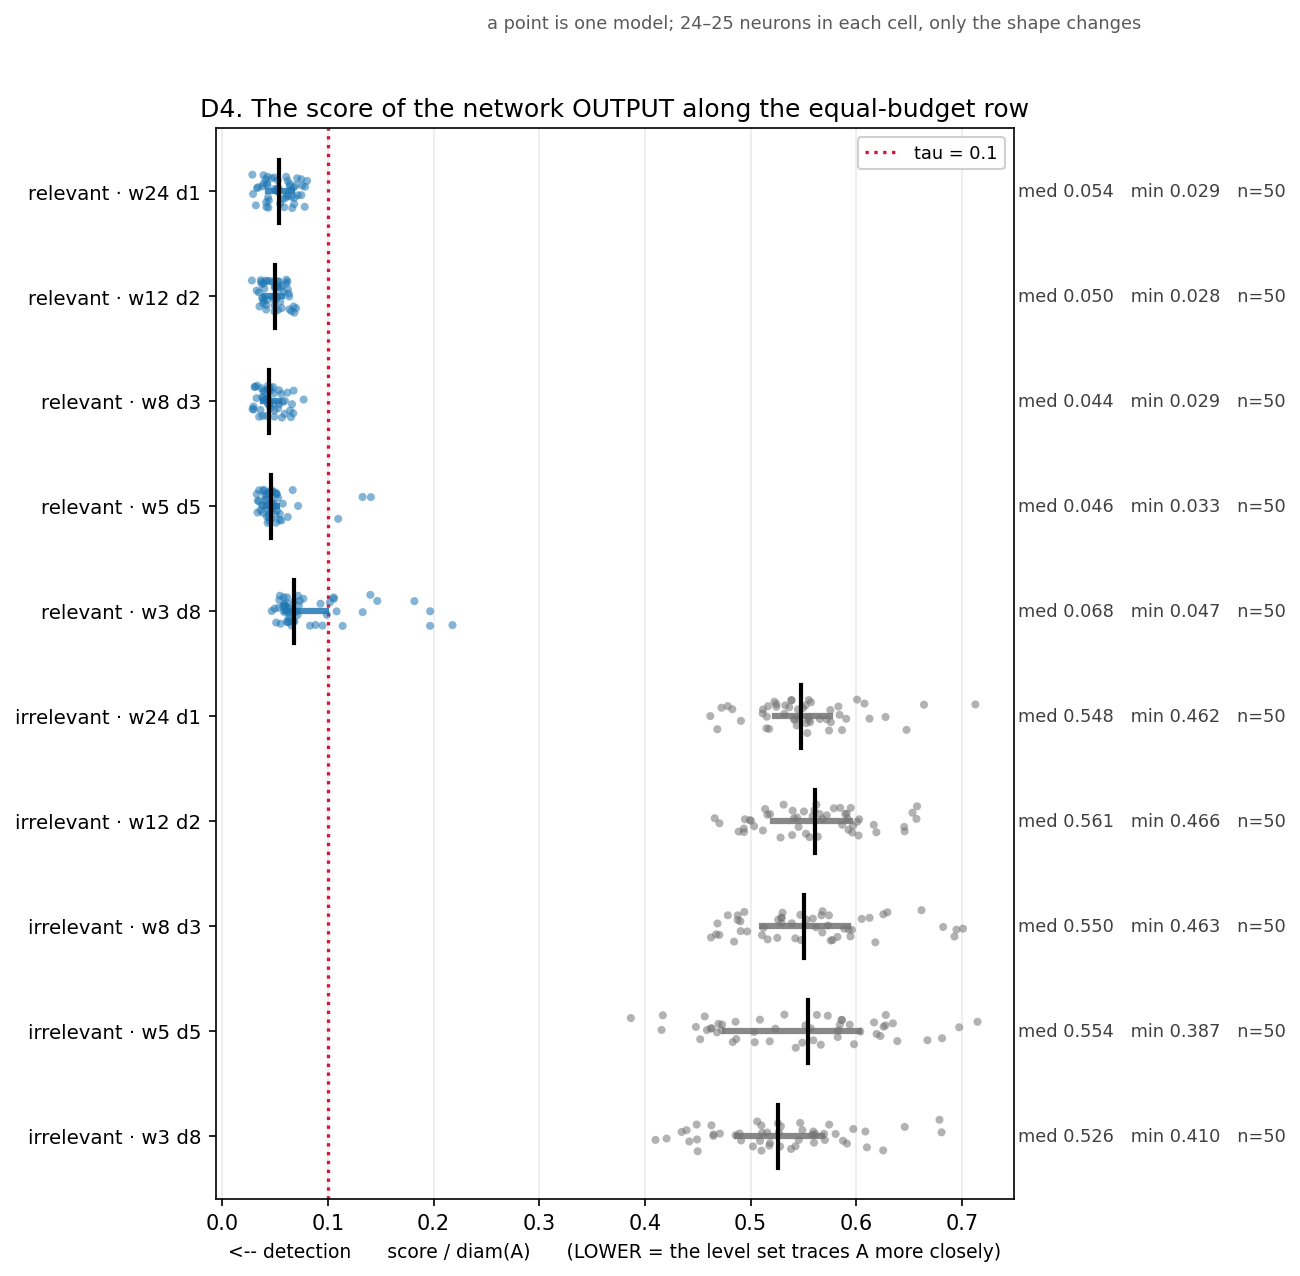

the fraction of models whose head witnesses the circle:
  relevant    w24 d1: 100.0%   median score 0.0539
  relevant    w12 d2: 100.0%   median score 0.0500
  relevant    w8 d3: 100.0%   median score 0.0441
  relevant    w5 d5:  94.0%   median score 0.0463
  relevant    w3 d8:  76.0%   median score 0.0677
  irrelevant  w24 d1:   0.0%   median score 0.5476
  irrelevant  w12 d2:   0.0%   median score 0.5612
  irrelevant  w8 d3:   0.0%   median score 0.5501
  irrelevant  w5 d5:   0.0%   median score 0.5543
  irrelevant  w3 d8:   0.0%   median score 0.5263


In [35]:
heads_b = pd.concat([
    aw.head_scores(df, ds, BUDGET_ROW, ES, cache=AGG / "head_scores.csv",
                   output="prob", verbose=False)
    for ds in (REL, IRR)], ignore_index=True)

units_b = heads_b.assign(criterion="structural", feature="head",
                         dataset=heads_b.dataset_type)
groups_b = ([(f"relevant · {a}", {"dataset": REL, "arch": a}, "tab:blue")
             for a in [f"w{w} d{d}" for w, d in BUDGET_ROW]]
            + [(f"irrelevant · {a}", {"dataset": IRR, "arch": a}, "0.45")
               for a in [f"w{w} d{d}" for w, d in BUDGET_ROW]])
plot_unit_strips(units_b, "structural", groups_b, threshold=aw.TAU,
                 title="D4. The score of the network OUTPUT along the equal-budget row",
                 caption="a point is one model; 24–25 neurons in each cell, "
                         "only the shape changes",
                 save_path=FIG / "D4_budget_head.png")
show(FIG / "D4_budget_head.png")

print("the fraction of models whose head witnesses the circle:")
for ds, name in ((REL, "relevant"), (IRR, "irrelevant")):
    for w, d in BUDGET_ROW:
        g = heads_b[(heads_b.dataset_type == ds) & (heads_b.arch == f"w{w} d{d}")]
        print(f"  {name:11s} w{w} d{d}: {g.witness.mean():6.1%}   "
              f"median score {g.score.median():.4f}")

### What D4 shows

**At depth 1 the feature is encoded in a distributed way — and this is measured, not inferred.** At `w24 d1` not one
of the 24 neurons can witness by the theorem, and D1 showed exactly zero. But the output of the same network
witnesses the circle in **all fifty models** (median score 0.0539). So the zero in D1 is a statement about neurons,
not about the network and not about the criterion: the network goes around the circle, it is just that none of its
neurons goes around it alone.

**The head gets worse with depth, while the fraction of neurons grows.** Along the row: 100% → 100% → 100% → 94%
→ **76%**, while the fraction of witnesses among neurons goes 0.00 → 0.07 → 0.23 → 0.42 → 0.55. The two quantities
move in opposite directions. `w3 d8` gives the worst output in the whole experiment (76%, median 0.0677) — and this
is the same cell that has the longest training, so the caveat of D2 extends to here as well.

**On irrelevant — zero out of two hundred and fifty**, medians 0.526–0.561 at a threshold of 0.1. The shape of the
network does not bring the irrelevant circle to the output in any form.

---

## Summary of D

**1. At an equal budget the shape buys extent, not sharpness.** The fraction of witnesses grows with depth
monotonically (0.00 → 0.07 → 0.23 → 0.42 → 0.55), the quality of the best neuron improves only up to `d = 5`, and
beyond that it reaches a shelf. The floor at `d ≥ 2` is flat (0.169–0.185), so multiplicity is fixed and the
difference within the row is an effect of arrangement.

**2. The dip in quality at `d = 8` is an effect of training duration, not of depth.** `w3 d8` is the only cell of the
row that stands out in training (a median of 125.5 epochs against 38–59, a maximum of 2346). In the window up to 62
epochs its best neuron goes 0.0517 → 0.0394 [0.0337, 0.0435] and becomes indistinguishable from `w5 d5` (0.0345
[0.0333, 0.0378]). The rise from `d = 2` to `d = 5`, on the other hand, survives the window in full. This is a
matched subsample, not an intervention: task E separates duration from initialisation.

**3. The equal-budget row is the least confounded comparison of the experiment.** The training duration along it is
almost constant (59 / 38 / 38 / 41 epochs at `d ≤ 5`), whereas in the width row of task B it changes 9.5-fold. So
conclusion B "depth is stronger than width" stands on firm ground precisely here.

**4. The mechanism of part C predicts four cells on which it was not built.** The wider budget cell at `d = 2`
witnesses less often (0.133 against 0.224), the narrower one at `d = 8` more often on the early layers and less often
on the late ones. The length of the construction does not depend on width, the height of the shelf does. The
aggregate fraction at equal depth differs by no more than 0.05 at a threefold difference in width: **the fraction is
an almost pure function of depth**.

**5. At depth 1 the encoding must be distributed.** The output of `w24 d1` witnesses the circle in 100% of models,
with zero witness neurons. The zero by the theorem is about neurons, while the network solves the task and goes around
the boundary.

**6. On the irrelevant circle the shape gives nothing.** Not a single witness among the neurons, not a single one
among the two hundred and fifty outputs. The growth of `p_superior` along the row (0.033 → 0.142) is a movement of
the **floor**, not of the target: the target median stands still (0.4126 → 0.4080), while the null placements become
harder with depth.

---

### What D does not show

* **Nothing about the causality of duration.** D2 is a matched subsample; selecting by the gate epoch also selects by
  the luck of the initialisation. This is a bound on the confound, not its decomposition.
* **The row is one and short** — five shapes at one budget of 24–25 neurons. "Depth buys extent" must not be
  transferred to other budgets without a check.
* **The floor of the cell `w24 d1` is not comparable with its neighbours**: it is computed over incapable neurons and
  is therefore twice as high.

---

# E. Over-training

The gate stops training at the moment the network first holds 100% accuracy for five epochs in a row. On a linearly
separable task this happens the earlier, the wider the network, and the difference is huge: on `simple_relevant` at
depth 5 the median stopping epoch goes **124 epochs at width 3 against 9 at width 40**. So **the width axis in tasks A
and B is at the same time an axis of training duration**, running in the opposite direction and fourteenfold, and
any curve there can be read as a curve of "score against how long the network trained".

**This is not resolved by observation.** Within a cell the Spearman correlation between the stopping epoch and the
best score **changes sign**: +0.70 at `w3 d5`, +0.71 at `w5 d8`, but −0.50 at `w5 d2` and −0.44 at `w12 d2`. A model
that needed 1861 epochs is a model with an unlucky initialisation, so a positive correlation reads in two
incompatible ways: "trained longer — came out worse" and "bad runs train longer". They can be told apart only by an
intervention.

## How the experiment is set up

Training **does not seed**: a repeated run of the same architecture gives a different trajectory, not a longer one.
So the early and the late point are taken from **one run**: each network trains up to 3000 epochs, and its state is
saved at several intermediate points. The comparison becomes within-model: the same initialisation, the same
trajectory, and the variance over seeds drops out of the difference entirely.

**What is called a ladder from here on.** A ladder is the set of moments at which the state of a run is taken, given
by **multiples of its own gate**: `×1` — the gate itself, `×10` — ten times as many epochs, and `end` — three thousand
epochs, the common limit for all. Multiples rather than absolute epochs, because the gates of the cells differ by an
order of magnitude: one and the same absolute epoch falls before the gate for one network and long after it for
another. Each rung is stored as an ordinary ensemble and evaluated like any other, so a "rung" and a "cell of the
pool" are objects of one type.

| cell | role |
|---|---|
| `w3 d2` | the absolute minimum: the smallest network that reliably solves the task and has a capable neuron |
| `w3 d5` | the minimal width among those studied; all the anomalies of parts B–D live there too |
| `w5 d5` | the reference, also an independent replication of the pool |
| `w3 d8` | narrow and deep |
| `w24 d1` | **a control of the instrument**: a witness is impossible by the theorem, so any movement of the score there is a movement of the criterion's baseline, not of the representation |

Three questions, in decreasing order of importance: **(1)** is the trend along width explained by duration;
**(2)** is it causality or selection; **(3)** does the network cut out the circle it does not need more strongly if
training continues after 100% accuracy.

**A caveat about the `×10` rung.** For a run with a late gate it does not fit into 3000 epochs, so on `relevant` not
all runs have it (37 of 56 at `w3 d2`). The whole comparison is made **on the runs present at all three rungs** —
otherwise the upper rungs would compare a different population, selected by the speed of convergence, and the
difference would be attributed to duration.

---

### E1. What continued training does to the relevant circle

**What we draw.** Three panels along the ladder. On the left the fraction of witnesses among neurons, in the middle the
median of the best neuron per model (logarithmic scale, the red dashed line is `τ`), on the right **the paired
difference**: the median over runs of "the score of this rung minus the score at the gate of the same run". Below
zero — continued training improved things. Everywhere the grey dashed line is `w24 d1` — the control cell, where there
can be no witness.

**What we want to see.** If the confound explained the trend along width, continued training would have to **spoil**
the score: wide networks train little, and their advantage would then be explained exactly by that. If continued
training improves, then the confound acts **against** conclusion B, not for it, and the conclusion only gets stronger
from it. The control line tells how much of any movement is due to the ruler itself.

In [36]:
# The rungs are stored as separate ensembles, but the comparison must be WITHIN a run,
# otherwise the difference between two rungs is a difference of initialisations, not of durations.
# load_overtraining restores the run index (model ids do NOT coincide between rungs: a run
# with a late gate has no upper rung, and the numbering shifts).
ot = aw.load_overtraining(EXPERIMENTS["exp2_extended"].results_dir)
BASES = ["tanh_w3_d2", "tanh_w3_d5", "tanh_w5_d5", "tanh_w3_d8", "tanh_w24_d1"]
RUNGS = ("x1", "x10", "end")

ladder = pd.concat([aw.paired_rungs(ot, ds, b, rungs=RUNGS, n_boot=2000)
                    for ds in (REL, IRR) for b in BASES], ignore_index=True)
ladder.to_csv(AGG / "overtrain_ladder.csv", index=False)

print(f"runs in total {ot.run.nunique()}, rows {len(ot)}")
print("common runs per cell (not all have the ×10 rung — for slow "
      "runs it did not fit into 3000 epochs):")
piv = ladder.pivot_table(index=["dataset_type", "base"], values="n_runs", aggfunc="first")
print(piv.to_string())
print("\nmedian epoch of the rung:")
print(ladder.pivot_table(index="base", columns="rung", values="median_epoch",
                         aggfunc="median").loc[BASES, list(RUNGS)].round(0).to_string())

/home/serdabel/.local/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


/home/serdabel/.local/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


/home/serdabel/.local/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


/home/serdabel/.local/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


/home/serdabel/.local/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


/home/serdabel/.local/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


/home/serdabel/.local/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


runs in total 539, rows 88179
common runs per cell (not all have the ×10 rung — for slow runs it did not fit into 3000 epochs):
                               n_runs
dataset_type      base               
simple_irrelevant tanh_w24_d1      50
                  tanh_w3_d2       56
                  tanh_w3_d5       56
                  tanh_w3_d8       63
                  tanh_w5_d5       50
simple_relevant   tanh_w24_d1      50
                  tanh_w3_d2       37
                  tanh_w3_d5       38
                  tanh_w3_d8       40
                  tanh_w5_d5       49

median epoch of the rung:
rung           x1    x10     end
base                            
tanh_w3_d2   92.0  929.0  2999.0
tanh_w3_d5   57.0  579.0  2999.0
tanh_w5_d5   28.0  289.0  2999.0
tanh_w3_d8   54.0  552.0  2999.0
tanh_w24_d1  39.0  396.0  2999.0


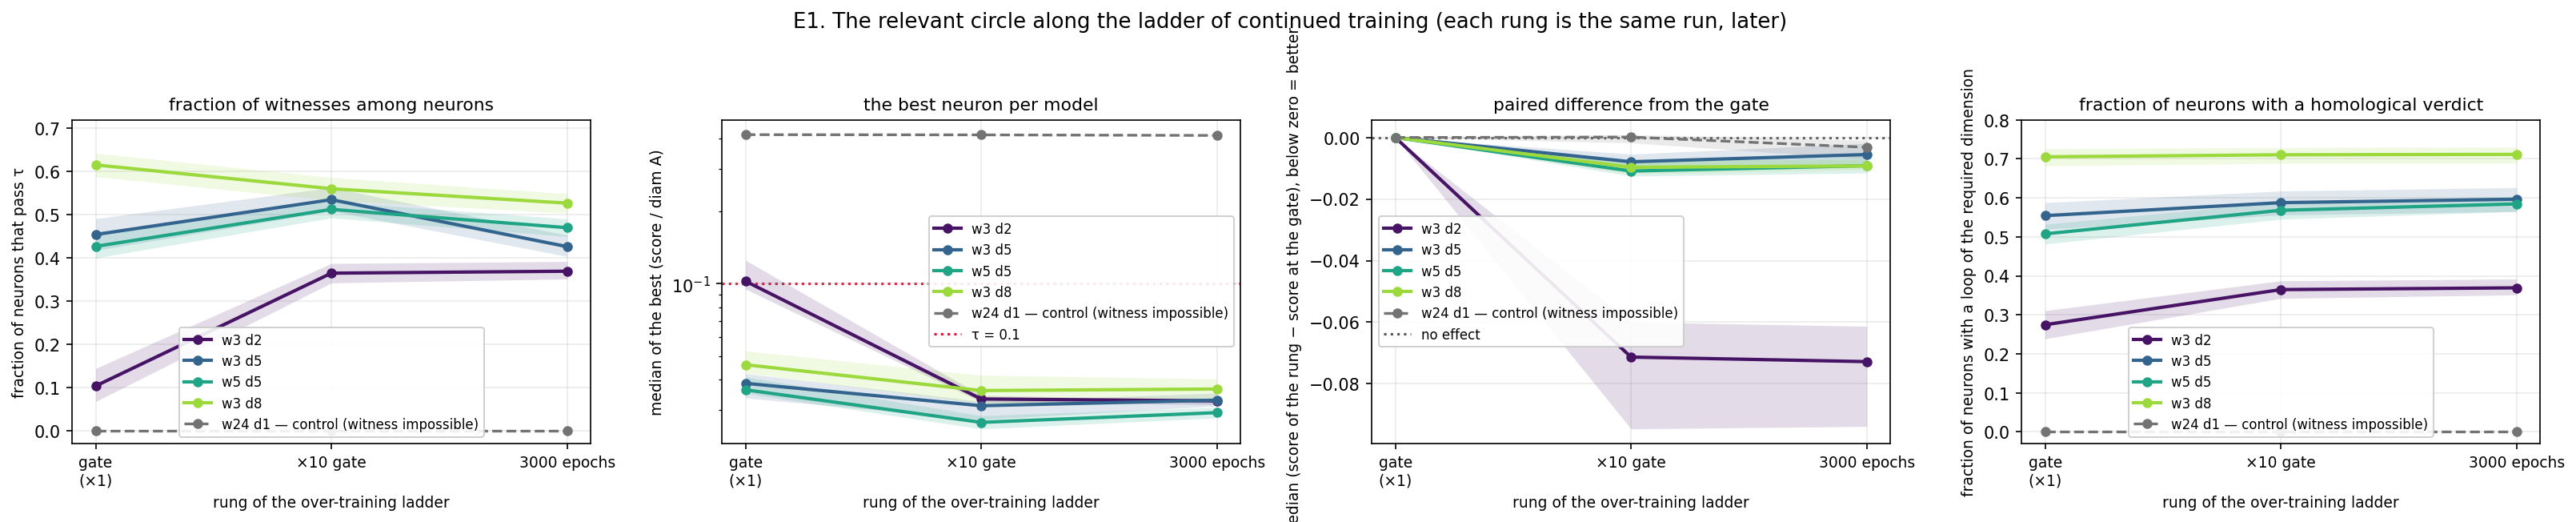

paired difference of the best neuron relative to the gate (negative = continued training improved):
  tanh_w3_d2   n=37  gate 0.1025 → ×10 0.0333 → end 0.0327   difference ×10 -0.0713 [-0.0947, -0.0600], end -0.0728 [-0.0939, -0.0613]
  tanh_w3_d5   n=38  gate 0.0386 → ×10 0.0312 → end 0.0329   difference ×10 -0.0079 [-0.0097, -0.0054], end -0.0055 [-0.0091, -0.0019]
  tanh_w5_d5   n=49  gate 0.0363 → ×10 0.0266 → end 0.0292   difference ×10 -0.0109 [-0.0125, -0.0081], end -0.0091 [-0.0115, -0.0062]
  tanh_w3_d8   n=40  gate 0.0461 → ×10 0.0361 → end 0.0366   difference ×10 -0.0097 [-0.0118, -0.0075], end -0.0092 [-0.0104, -0.0072]
  tanh_w24_d1  n=50  gate 0.4157 → ×10 0.4149 → end 0.4127   difference ×10 +0.0001 [-0.0017, +0.0010], end -0.0032 [-0.0070, -0.0009]

the fraction of models that have at least one witness:
  tanh_w3_d2  : 0.41 → 1.00 → 1.00
  tanh_w3_d5  : 1.00 → 1.00 → 1.00
  tanh_w5_d5  : 1.00 → 1.00 → 1.00
  tanh_w3_d8  : 1.00 → 1.00 → 1.00
  tanh_w24_d1 : 0.00 → 0.00 →

In [37]:
rel = ladder[ladder.dataset_type == REL]
ap.plot_rung_ladder([
    dict(title="fraction of witnesses among neurons", table=rel, value="fraction",
         ylabel="fraction of neurons that pass τ", ylim=(-0.03, 0.72),
         highlight="tanh_w24_d1"),
    dict(title="the best neuron per model", table=rel, value="median_best",
         ylabel="median of the best (score / diam A)", log_y=True,
         hline=(aw.TAU, "τ = 0.1"), highlight="tanh_w24_d1"),
    dict(title="paired difference from the gate", table=rel, value="paired_delta",
         ylabel="median (score of the rung − score at the gate), below zero = better",
         hline=(0.0, "no effect"), hline_colour="0.35",
         highlight="tanh_w24_d1"),
    dict(title="fraction of neurons with a homological verdict", table=rel,
         value="hom_fraction", ylabel="fraction of neurons with a loop of the required dimension",
         ylim=(-0.03, 0.80), highlight="tanh_w24_d1"),
], suptitle="E1. The relevant circle along the ladder of continued training "
            "(each rung is the same run, later)",
   save_path=FIG / "E1_overtrain_relevant.png")
show(FIG / "E1_overtrain_relevant.png")

print("paired difference of the best neuron relative to the gate "
      "(negative = continued training improved):")
for b in BASES:
    r = rel[(rel.base == b) & (rel.rung == "end")].iloc[0]
    x10 = rel[(rel.base == b) & (rel.rung == "x10")].iloc[0]
    g = rel[(rel.base == b) & (rel.rung == "x1")].iloc[0]
    print(f"  {b:12s} n={int(r.n_runs):2d}  gate {g.median_best:.4f} → "
          f"×10 {x10.median_best:.4f} → end {r.median_best:.4f}   "
          f"difference ×10 {x10.paired_delta:+.4f} [{x10.paired_delta_lo:+.4f}, "
          f"{x10.paired_delta_hi:+.4f}], end {r.paired_delta:+.4f} "
          f"[{r.paired_delta_lo:+.4f}, {r.paired_delta_hi:+.4f}]")
print("\nthe fraction of models that have at least one witness:")
for b in BASES:
    vals = [rel[(rel.base == b) & (rel.rung == k)].p_has_witness.iat[0] for k in RUNGS]
    print(f"  {b:12s}: " + " → ".join(f"{v:.2f}" for v in vals))
print("\nthe second criterion: the fraction of neurons with a verdict and the best margin per model:")
for b in BASES:
    fr = [rel[(rel.base == b) & (rel.rung == k)].hom_fraction.iat[0] for k in RUNGS]
    mg = [rel[(rel.base == b) & (rel.rung == k)].median_hom_best.iat[0] for k in RUNGS]
    print(f"  {b:12s}: fraction " + " → ".join(f"{v:.3f}" for v in fr)
          + "   margin " + " → ".join(f"{v:+.3f}" for v in mg))

### What E1 shows

**Continued training improves the score, and on every capable cell.** The paired difference from the gate is negative
everywhere, and not a single interval covers zero:

| cell | gate | ×10 | end | paired difference at the end |
|---|---|---|---|---|
| `w3 d2` | 0.1025 | 0.0333 | 0.0327 | **−0.0728 [−0.0939, −0.0613]** |
| `w3 d5` | 0.0386 | 0.0312 | 0.0329 | −0.0055 [−0.0091, −0.0019] |
| `w5 d5` | 0.0363 | 0.0266 | 0.0292 | −0.0091 [−0.0115, −0.0062] |
| `w3 d8` | 0.0461 | 0.0361 | 0.0366 | −0.0092 [−0.0104, −0.0072] |
| `w24 d1` (control) | 0.4157 | 0.4149 | 0.4127 | −0.0032 [−0.0070, −0.0009] |

**Question 2 is resolved, and the answer is selection, not causality.** The observed correlation within `w3 d5` was
**+0.70**: the longer a run trained, the worse its best neuron was. The paired effect on the same cells has **the
opposite sign**: −0.0079 at `×10`. That is, slowly converging runs really are worse — but not because they trained
long, rather because they got an unlucky initialisation. Making a particular run train longer improves it.

**Question 1 is resolved, and the confound acts against conclusion B, not for it.** Wide networks stop earlier (9
epochs at `w40` against 124 at `w3`), and continued training improves the score. So the wide cells in tasks A and B
were measured **under conditions unfavourable to them**, and the real advantage of width is not smaller than the
measured one but larger. The conclusion "width buys not only attempts" can only get stronger when the confound is
removed.

**The minimal network lacks not capacity but time.** At `w3 d2` at the gate a witness exists in only **41%** of models
with a median of the best of 0.1025 — that is, a little worse than the threshold. After continued training a witness
exists in **100%**, and the median falls to 0.0327, level with the reference `w5 d5`. Six neurons single out the
circle perfectly well; at the gate it is simply not yet singled out.

**The optimum is not at the end but at `×10`.** In three cells of four the `×10` rung is better than the end: −0.0079
against −0.0055, −0.0109 against −0.0091, −0.0097 against −0.0092. The fraction behaves the same way (for example,
0.513 → 0.470 at `w5 d5`). Training too long starts to do a little harm — this is the same effect that is seen in X3
on the tail of deep networks.

**The second criterion agrees, and on the fourth panel this is seen directly.** The fraction of neurons with a
homological verdict grows along the ladder monotonically on all capable cells: 0.275 → 0.365 → 0.369 at `w3 d2`,
0.508 → 0.568 → 0.584 at `w5 d5`, 0.705 → 0.710 → 0.711 at `w3 d8`. Note that here there is no fallback towards the
end — unlike the structural fraction, which is higher at `×10` than at three thousand epochs. This is the same
contrast as in C2: there only become more closed level curves, but their geometry moves away from the circle towards
the end of training. The best margin per model behaves the same way: at `w3 d2` it grows from +0.563 to +1.485, in the
others it goes from +1.62–1.73 to +1.80 and stops there — this is the ceiling of the quantity itself, not a result.

**The control is already on this figure.** `w24 d1` moves by −0.0032 over three thousand epochs — five times less
than `w5 d5`, and twenty-three times less than `w3 d2`. How much the field itself changed meanwhile is checked
separately in E3.

---

### E2. The same ladder on the irrelevant circle

**What we draw.** Three panels: the median of the best neuron, the paired difference from the gate and the fraction of
neurons with a homological verdict — all on `simple_irrelevant`. There is nothing to draw for the structural fraction:
it is zero everywhere, and this in itself is a result.

**What we want to see.** This is the PLAN's original question in its temporal form: part A showed that excess
**capacity** does not generate a witness of an unneeded circle; does excess **time** generate one? If so, the
incidental effect would turn out to be a function of training duration, not only of size, and all the conclusions of
A would have to be read with the caveat "at such and such a duration".

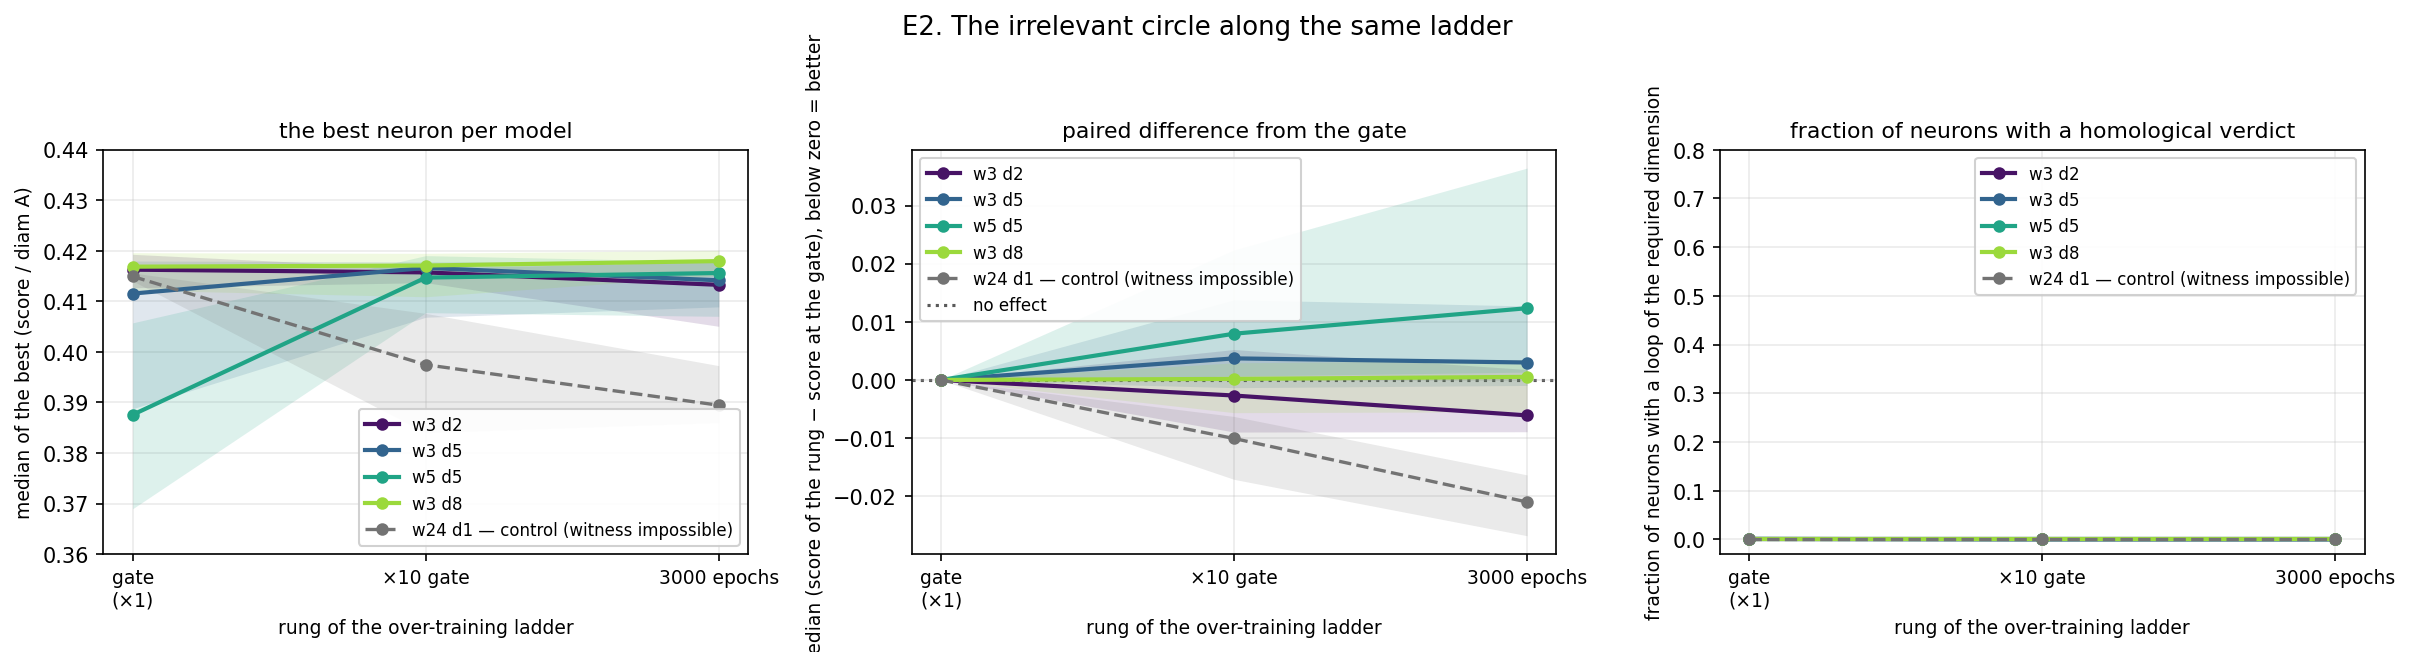

witnesses of the irrelevant circle at all rungs and in all cells: 0 cells with a non-zero fraction of 15

paired difference of the best neuron (positive = continued training made it WORSE):
  tanh_w3_d2   n=56  gate 0.4163 → end 0.4133   difference -0.0061 [-0.0089, +0.0018]
  tanh_w3_d5   n=56  gate 0.4115 → end 0.4142   difference +0.0030 [-0.0009, +0.0127]
  tanh_w5_d5   n=50  gate 0.3876 → end 0.4156   difference +0.0123 [+0.0014, +0.0364]
  tanh_w3_d8   n=63  gate 0.4169 → end 0.4180   difference +0.0005 [-0.0055, +0.0035]
  tanh_w24_d1  n=50  gate 0.4149 → end 0.3894   difference -0.0210 [-0.0268, -0.0163]

the best homological margin (negative = no verdict):
  tanh_w3_d2  : -0.079 → -0.018 →     no bar
  tanh_w3_d5  : -0.036 → -0.073 → -0.058
  tanh_w5_d5  : -0.060 → -0.059 → -0.049
  tanh_w3_d8  : -0.042 → -0.064 → -0.060
  tanh_w24_d1 :     no bar →     no bar →     no bar


In [38]:
irr = ladder[ladder.dataset_type == IRR]
ap.plot_rung_ladder([
    dict(title="the best neuron per model", table=irr, value="median_best",
         ylabel="median of the best (score / diam A)", ylim=(0.36, 0.44),
         highlight="tanh_w24_d1"),
    dict(title="paired difference from the gate", table=irr, value="paired_delta",
         ylabel="median (score of the rung − score at the gate), below zero = better",
         hline=(0.0, "no effect"), hline_colour="0.35",
         highlight="tanh_w24_d1"),
    dict(title="fraction of neurons with a homological verdict", table=irr,
         value="hom_fraction", ylabel="fraction of neurons with a loop of the required dimension",
         ylim=(-0.03, 0.80), highlight="tanh_w24_d1"),
], suptitle="E2. The irrelevant circle along the same ladder",
   save_path=FIG / "E2_overtrain_irrelevant.png")
show(FIG / "E2_overtrain_irrelevant.png")

print(f"witnesses of the irrelevant circle at all rungs and in all cells: "
      f"{int(irr.fraction.sum() * 0 + (irr.fraction > 0).sum())} cells with a non-zero fraction "
      f"of {len(irr)}")
print("\npaired difference of the best neuron (positive = continued training made it WORSE):")
for b in BASES:
    r = irr[(irr.base == b) & (irr.rung == "end")].iloc[0]
    g = irr[(irr.base == b) & (irr.rung == "x1")].iloc[0]
    print(f"  {b:12s} n={int(r.n_runs):2d}  gate {g.median_best:.4f} → end "
          f"{r.median_best:.4f}   difference {r.paired_delta:+.4f} "
          f"[{r.paired_delta_lo:+.4f}, {r.paired_delta_hi:+.4f}]")
print("\nthe best homological margin (negative = no verdict):")
for b in BASES:
    vals = [irr[(irr.base == b) & (irr.rung == k)].median_hom_best.iat[0] for k in RUNGS]
    print(f"  {b:12s}: " + " → ".join(f"{v:+.3f}" if v == v else "    no bar" for v in vals))

### What E2 shows

**Not a single witness at any rung in any cell.** Fifteen (cell, rung) pairs — fifteen zeros. Three thousand epochs,
that is, up to two hundred and thirty gates, create nothing.

**The score meanwhile either stays put or gets worse.** The only cell with a significant shift is `w5 d5`, and the
shift is **positive**: +0.0123 [+0.0014, +0.0364], i.e. the target moves away from the circle. At `w3 d5`, `w3 d8` and
`w3 d2` the intervals cover zero. The homological fraction on the right panel is **zero in fourteen (cell, rung) pairs
of fifteen**; in the fifteenth, at the gate of `w3 d5`, it is one neuron out of eight hundred and forty. The best margin
per model stays negative at all rungs (−0.018…−0.079). The second criterion gives practically no verdict anywhere and
at no moment of training, and — what matters more here — **continued training does not raise its fraction**: it does
not grow in any cell.

**But here one has to stop and not say too much.** The control cell `w24 d1` on this dataset moves by **−0.0210
[−0.0268, −0.0163]** — more than any target one. That is, on `simple_irrelevant` the baseline of the criterion wanders
more over three thousand epochs than the targets themselves do. **So the movements of the score here cannot be
interpreted at all.** Only the count can be interpreted — and it equals zero at all rungs.

**The answer to question 3: no.** Continued training does not cut out the circle that the task does not need. Together
with part A and the additional cell `w40 d5`, this closes the incidental question from three sides: neither excess
capacity, nor doubled width, nor two-hundredfold time generates a witness of irrelevant topology.

**And this is exactly the contrast for which the pair of datasets was built.** One and the same intervention — training
longer — on the relevant circle improves the score twenty-three times more strongly than the control, and on the
bitwise same circle in the irrelevant dataset gives nothing. Only the task's need separates them.

---

### E3. How much the field itself has moved

**What we draw.** Two panels along the same ladder: the norm of the weights (logarithmic scale) and the fraction of
neurons whose `|tanh|` on the data is at least 0.99, i.e. saturated ones. Both quantities are medians over runs.

**Why this is needed.** The criterion scans 101 levels laid out over the **observed range** of the field, and continued
training changes this range: on a separable task the weights keep growing, `tanh` goes into saturation. So a shift of
the score could in principle report a shifted range rather than a shifted level curve. Here we measure how far the
range moved at all, and this is read together with the control cell: in `w24 d1` there is no witness by the theorem,
so there the score is moved **only** by the ruler.

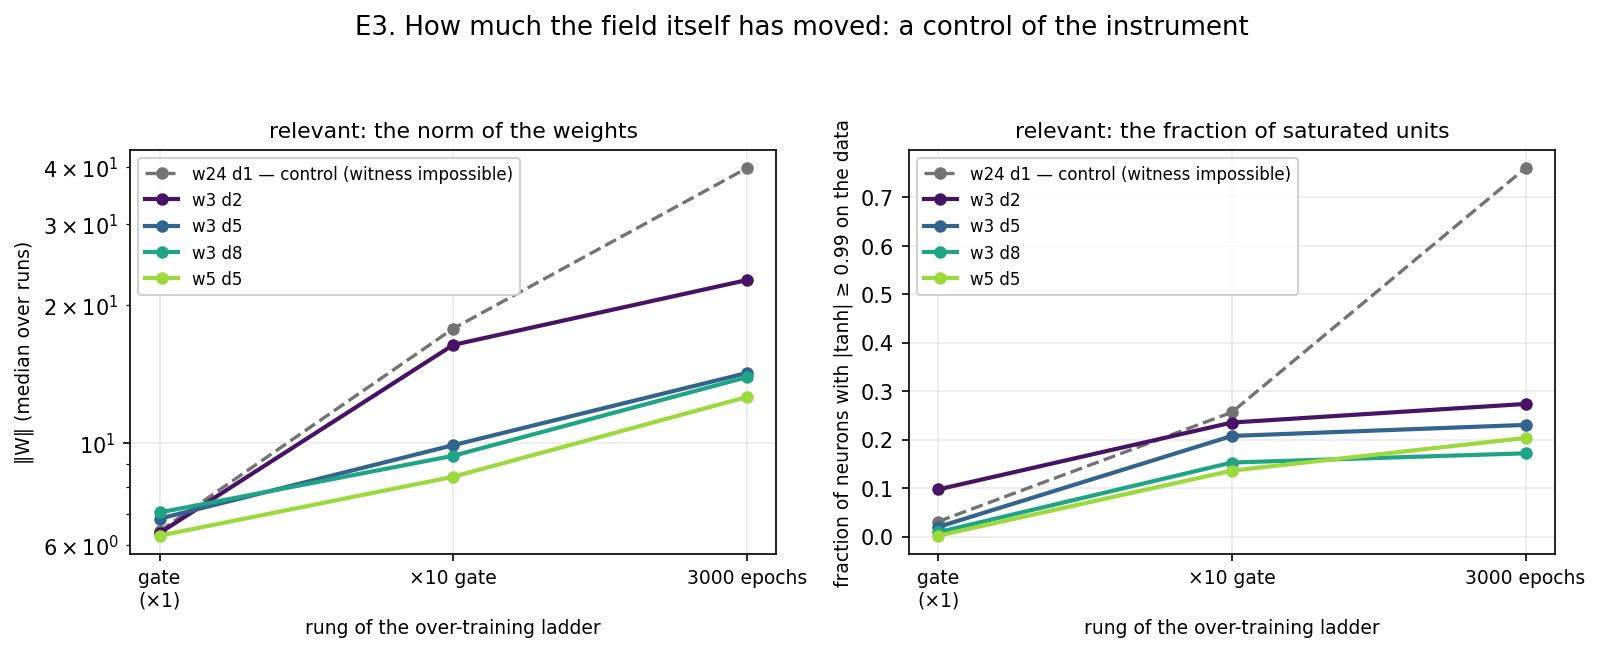

medians over runs, ‖W‖ / fraction saturated / mean |logit|:
  relevant:
    tanh_w3_d2    ‖W‖   6.36 →  16.36 →  22.65   satur 0.097 → 0.235 → 0.274   |logit|   1.86 →  14.64 →  22.52
    tanh_w3_d5    ‖W‖   6.84 →   9.89 →  14.21   satur 0.020 → 0.208 → 0.230   |logit|   3.13 →  10.58 →  19.67
    tanh_w5_d5    ‖W‖   6.28 →   8.44 →  12.60   satur 0.002 → 0.136 → 0.203   |logit|   2.75 →   8.19 →  20.74
    tanh_w3_d8    ‖W‖   7.05 →   9.38 →  13.92   satur 0.009 → 0.153 → 0.172   |logit|   3.38 →  10.32 →  19.66
    tanh_w24_d1   ‖W‖   6.42 →  17.76 →  39.74   satur 0.031 → 0.256 → 0.760   |logit|   0.66 →   6.77 →  22.52
  irrelevant:
    tanh_w3_d2    ‖W‖   2.28 →   4.88 →  12.59   satur 0.012 → 0.137 → 0.515   |logit|   0.90 →   5.02 →  19.24
    tanh_w3_d5    ‖W‖   3.48 →   5.52 →  12.80   satur 0.005 → 0.034 → 0.220   |logit|   0.75 →   4.39 →  19.26
    tanh_w5_d5    ‖W‖   4.17 →   5.71 →  11.16   satur 0.017 → 0.047 → 0.231   |logit|   1.36 →   5.10 →  20.31
    tanh_w3_d8    

In [39]:
sat = aw.saturation_table(ot)
sat.to_csv(AGG / "overtrain_saturation.csv", index=False)

ap.plot_rung_ladder([
    dict(title="relevant: the norm of the weights", table=sat[sat.dataset_type == REL],
         value="weight_norm", ylabel="‖W‖ (median over runs)", log_y=True,
         highlight="tanh_w24_d1"),
    dict(title="relevant: the fraction of saturated units", table=sat[sat.dataset_type == REL],
         value="saturated_fraction", ylabel="fraction of neurons with |tanh| ≥ 0.99 on the data",
         highlight="tanh_w24_d1"),
], suptitle="E3. How much the field itself has moved: a control of the instrument",
   save_path=FIG / "E3_overtrain_saturation.png")
show(FIG / "E3_overtrain_saturation.png")

print("medians over runs, ‖W‖ / fraction saturated / mean |logit|:")
for ds, name in ((REL, "relevant"), (IRR, "irrelevant")):
    print(f"  {name}:")
    for b in BASES:
        vals = [sat[(sat.dataset_type == ds) & (sat.base == b) & (sat.rung == k)].iloc[0]
                for k in RUNGS]
        print(f"    {b:12s}  ‖W‖ " + " → ".join(f"{v.weight_norm:6.2f}" for v in vals)
              + "   satur " + " → ".join(f"{v.saturated_fraction:.3f}" for v in vals)
              + "   |logit| " + " → ".join(f"{v.logit_abs_mean:6.2f}" for v in vals))

### What E3 shows

**The field moves very strongly.** On `relevant` the norm of the weights grows two- to sixfold, the fraction of saturated
units from hundredths to 0.14–0.27, the mean modulus of the logit from 2–3 to 20. This is no subtle correction: over
three thousand epochs the network passes into a qualitatively different regime.

**And the strongest movement of the field happens where the score moves least.** The record for saturation is the
control `w24 d1` on relevant: the norm of the weights **6.4 → 39.7**, the fraction saturated **0.031 → 0.760**, i.e. by
the end three quarters of its neurons are in saturation. The score meanwhile moves by −0.0032 — twenty-three times less
than at `w3 d2`, where the field moved **less** (0.097 → 0.274).

Hence the direct conclusion: **the effect of E1 is not an artefact of a shifted scale.** If the score were moved by a
rearrangement of the range, it would move most in the most saturated cell; the opposite is observed.

**One honest limit.** On `simple_irrelevant` the control moves by −0.021, even though the field there moved less than on
relevant. So the criterion's baseline depends not only on saturation, and we have no explanation for this. The practical
consequence is already written down in E2: on the irrelevant dataset movements of the score of the order of 0.01–0.02
must not be read; only the count of witnesses can be read.

---

## Summary of E

**1. Continued training improves the singling out of the relevant circle — on all capable cells.** The paired difference
from the gate is negative everywhere and nowhere covers zero: from −0.0055 at `w3 d5` to **−0.0728** at `w3 d2`. The
comparison is within-model, so the variance over initialisations is excluded from it entirely.

**2. The observed correlation "trained longer — worse" was selection, not causality.** Within `w3 d5` it equalled
+0.70; the paired effect has the opposite sign. Slow runs really are worse — but because they got a bad
initialisation, not because they trained long. This is exactly the question for which part E was done, and by
observation it could not be resolved in principle.

**3. The confound "width against duration" acts AGAINST conclusion B, not for it.** Wide networks stop fourteen times
earlier than narrow ones, and stopping training early worsens the score. So the measured advantage of width is a
**lower** estimate, and removing the confound will only strengthen it. After E the conclusions of A and B along the
width axis can be read without the caveat.

**4. The minimal network lacks time, not capacity.** At `w3 d2` — six neurons — at the gate a witness exists in 41% of
models, after continued training in **100%**, and the best score falls from 0.1025 to 0.0327, level with the reference.
The capacity of six neurons is sufficient; the gate simply stops the network before it manages to single out the circle.

**5. Training too long starts to do harm — but only by the structural criterion.** The optimum stands at the `×10` rung
(roughly ten gates), and by three thousand epochs part of the gain is lost: −0.0109 against −0.0091 at `w5 d5`. The
homological fraction meanwhile grows monotonically to the very end. This is the same contrast as in C2 on the tail of
deep networks: there become more closed level curves, but they stop resembling our circle.

**6. Continued training does not create the irrelevant circle.** Zero witnesses in all fifteen (cell, rung) pairs, the
homological margin is negative everywhere. Together with A and `w40 d5`, the incidental question is closed from three
sides: neither capacity, nor width, nor time.

**7. The effect is not an artefact of the instrument.** Over three thousand epochs the field moves radically (the norm
of the weights up to sixfold, the fraction saturated up to 0.76), but **the strongest movement of the field happens in
the control cell, where the score moves least**. The control on relevant moves by −0.0032 against −0.0728 at `w3 d2`.

### What E does not show

* **On the irrelevant dataset the movements of the score cannot be interpreted**: the control cell wanders more there than
  the target ones (−0.021). Only the count of witnesses can be interpreted, and it is zero.
* **The ladder is built from the gate of each run**, so "the ×10 rung" means different absolute epochs in different
  cells. Cells must not be compared with each other by rungs; each cell is compared with itself.
* **Not all runs have the `×10` rung** (37 of 56 at `w3 d2`), and the whole comparison is made on the common subset. The
  numbers on the full set of runs differ from these.
* **Why the criterion's baseline drifts on `simple_irrelevant`** these data do not explain.

---

# F. Other activation functions

The whole experiment — and the whole project — is built on `tanh`: the Morse framework requires smoothness, and all
fifteen architectures of the pool are made with it. So any conclusion is by default accompanied by a silent caveat
"with this activation". Here the caveat is checked on the reference cell `w5 d5`, with 50 attempts on each dataset.

**The two activations are taken in different roles, and they must not be confused.**

**Sigmoid is a control of the instrument, not a check of generalisation.** `σ(z) = (tanh(z/2) + 1) / 2`, that is, a
network of sigmoids and a network of `tanh` range over **one and the same class of functions**: any sigmoid network
is obtained from a tanh network by rewriting the weights. So the answer must coincide, and a discrepancy would be
evidence about the criterion, not about the networks.

**ReLU is a real check of generalisation.** The class is different: the field is piecewise linear and non-smooth, the
Morse framework does not extend to it, the level curves are polylines. Here any outcome is meaningful.

**One methodological caveat, declared in advance.** The spec fixes `activation=None`, i.e. the 101 levels are laid out
uniformly over the **observed range** of the field. For ReLU the field is non-negative and heavy-tailed, and
`criterions.make_candidate_levels` has an exponential grid for such a case. The linear one is chosen **deliberately,
for comparability** with all the rest of the pool; if the result runs into the grid, this will be seen from ReLU losing
everywhere at once.

---

### F1. The same verdict or a different one

**What we draw.** The familiar strips: a point is a (model, feature) pair by its best neuron, the red dashed line is
`τ`, detection is to the left. Six pairs of rows: three activations × two datasets, each with the target and the floor
of its own cell.

**What we want to see.** The main question is whether the **verdict** transfers: the relevant circle is detected, the
irrelevant one is not. This is a statement about the side of the threshold, and it must be the same for all three
activations, otherwise the whole experiment turns out to be a statement about `tanh`.

**And at once a second question that this figure makes visible.** The grey clouds — the floors — of the three
activations stand in different places. If so, raw scores must not be compared between activations: the floor is the
scale, its own for each activation.

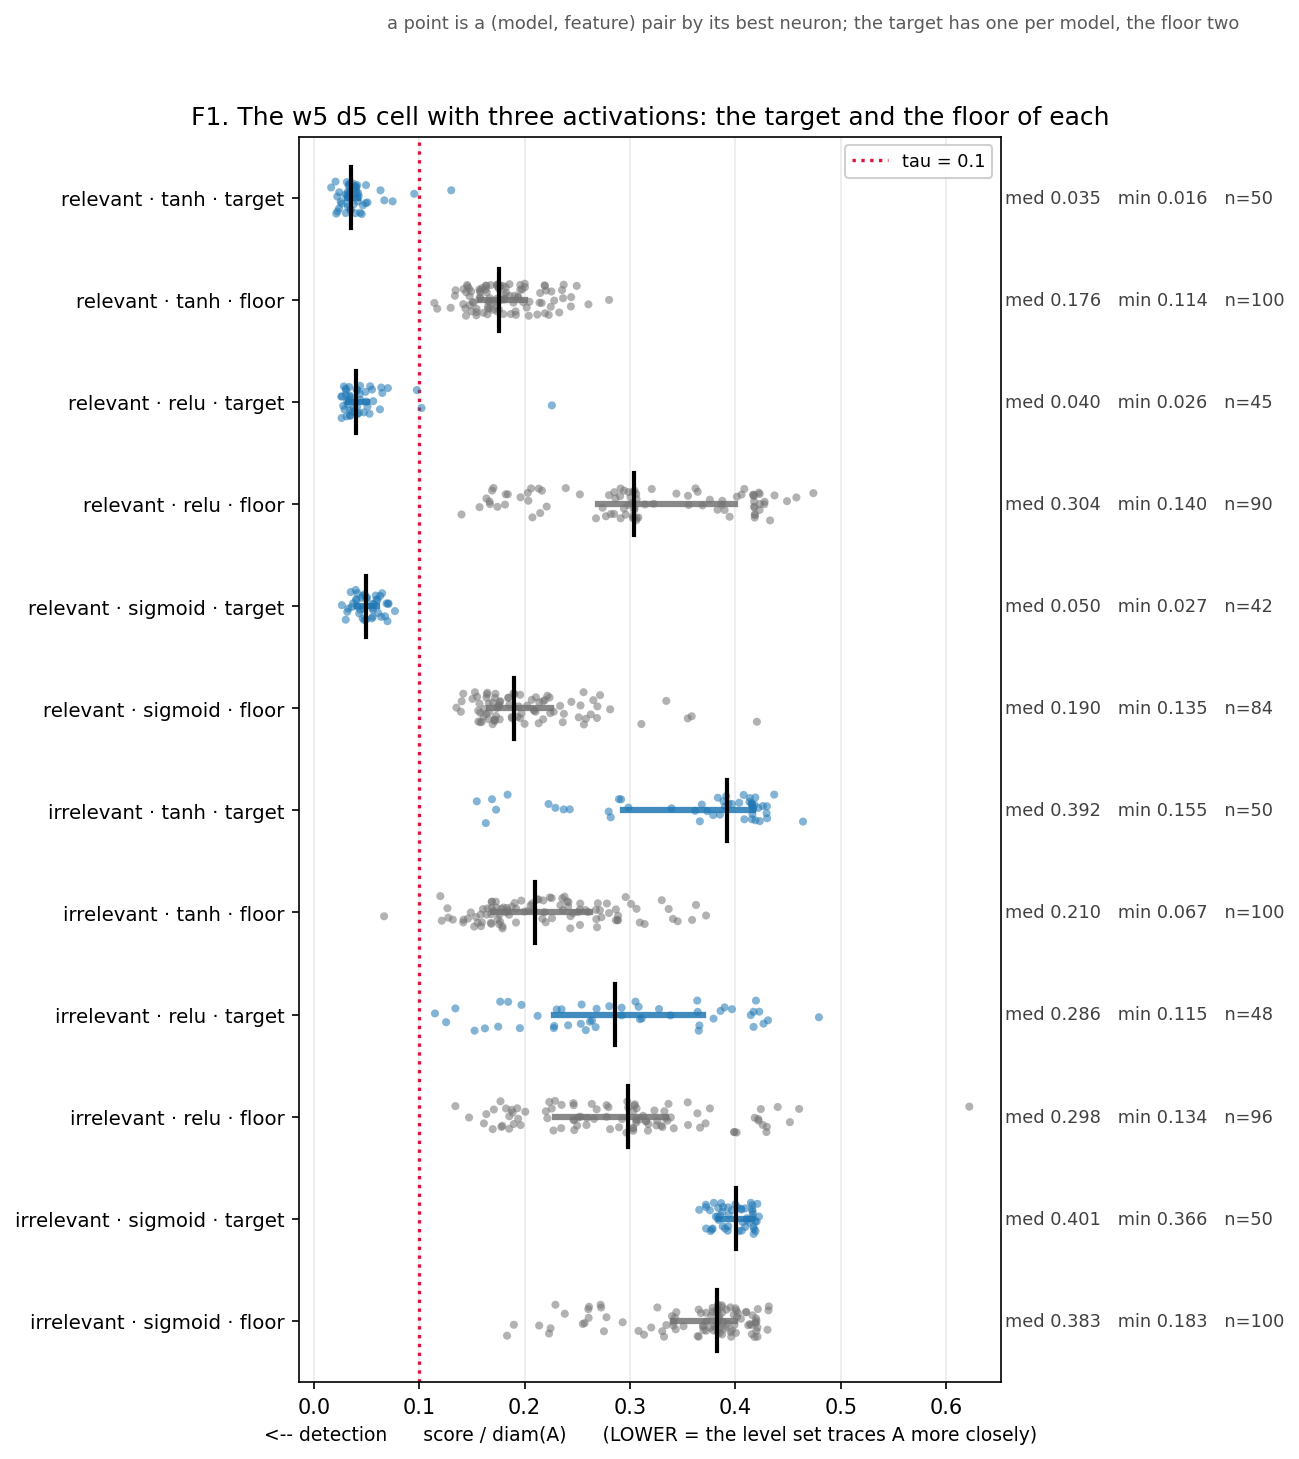

,dataset,activation,models,witness frac.,target,floor,target/floor,p_superior,epochs
0,relevant,tanh,50,0.4192,0.0349,0.1756,0.1990,0.9994,41.0
1,relevant,relu,45,0.3902,0.0405,0.3041,0.1332,0.9951,47.0
2,relevant,sigmoid,42,0.7410,0.0499,0.1899,0.2627,1.0000,262.5
3,irrelevant,tanh,50,0.0000,0.3923,0.2101,1.8668,0.1232,12.0
4,irrelevant,relu,48,0.0000,0.2862,0.2979,0.9608,0.4961,17.5
5,irrelevant,sigmoid,50,0.0000,0.4010,0.3828,1.0474,0.2960,48.0


In [40]:
EXT = EXPERIMENTS["exp2_extended"]
ext_all = aw.load_neuron_stats(EXT.results_dir)
ACT_TAGS = ["tanh_w5_d5_mass-train", "relu_w5_d5", "sigmoid_w5_d5"]
NAMES = {"tanh_w5_d5_mass-train": "tanh", "relu_w5_d5": "relu",
         "sigmoid_w5_d5": "sigmoid"}

df_act = pd.concat([df[df.arch == "w5 d5"],
                    ext_all[ext_all.tag.isin(["relu_w5_d5", "sigmoid_w5_d5"])]],
                   ignore_index=True)
scores_act = aw.to_scores(df_act)

groups = []
for ds, name in ((REL, "relevant"), (IRR, "irrelevant")):
    for tag in ACT_TAGS:
        groups.append((f"{name} · {NAMES[tag]} · target",
                       {"dataset": ds, "tag": tag, "role": "target"}, "tab:blue"))
        groups.append((f"{name} · {NAMES[tag]} · floor",
                       {"dataset": ds, "tag": tag, "role": "null"}, "0.45"))
plot_unit_strips(scores_act, "structural", groups, threshold=aw.TAU,
                 title="F1. The w5 d5 cell with three activations: the target and the floor of each",
                 caption="a point is a (model, feature) pair by its best neuron; "
                         "the target has one per model, the floor two",
                 save_path=FIG / "F1_activations_strips.png")
show(FIG / "F1_activations_strips.png")

from analysis.calibration import superiority_probability
rows = []
for ds, name in ((REL, "relevant"), (IRR, "irrelevant")):
    for tag in ACT_TAGS:
        b = df_act[(df_act.dataset_type == ds) & (df_act.tag == tag)]
        t = b[b.feature_role == "target"].groupby("model_path").score.min()
        n = b[b.feature_role == "null"].groupby(["model_path", "feature_name"]).score.min()
        rows.append({"dataset": name, "activation": NAMES[tag], "models": len(t),
                     "witness frac.": b[b.feature_role == "target"].witness.mean(),
                     "target": t.median(), "floor": n.median(),
                     "target/floor": t.median() / n.median(),
                     "p_superior": superiority_probability(t.to_numpy(), n.to_numpy()),
                     "epochs": b.groupby("model_path").train_stopped_epoch.first().median()})
act_table = pd.DataFrame(rows)
act_table.to_csv(AGG / "activation_comparison.csv", index=False)
display(act_table.round(4))

### What F1 shows

**The verdict transfers completely.** On `simple_relevant` all three activations detect the circle: the fraction of
models with a witness is 0.98 / 0.96 / 1.00, `p_superior` against their own floor 0.9994 / 0.9951 / 1.0000. On
`simple_irrelevant` **none detects anything**: zero witnesses out of 25 neurons × (42…50) models for each, and zero as
well on the null placements. The main result of the experiment — that the feature the task needs is detected and a
bitwise identical unneeded one is not — **does not depend on the activation**.

**But the numbers do depend on it, and strongly — and the floor moves no less than the target.**

| dataset | activation | fraction | target | floor | **target/floor** | epochs |
|---|---|---|---|---|---|---|
| relevant | tanh | 0.419 | 0.0349 | 0.176 | 0.199 | 41 |
| relevant | relu | 0.390 | 0.0405 | **0.304** | **0.133** | 47 |
| relevant | sigmoid | **0.741** | 0.0499 | 0.190 | 0.263 | **262** |
| irrelevant | tanh | 0.000 | 0.392 | 0.210 | 1.867 | 12 |
| irrelevant | relu | 0.000 | 0.286 | 0.298 | **0.961** | 18 |
| irrelevant | sigmoid | 0.000 | 0.401 | 0.383 | 1.047 | 48 |

**The order by raw score and the order by the ratio to the floor are opposite.** By the median of the best, `tanh`
looks best (0.0349) and `sigmoid` worst (0.0499). By the ratio of the target to its own floor — that is, by the only
quantity that does not depend on how "rich" in level curves a given activation is in general — the best turns out to be
**`relu` (0.133)**, and the worst `sigmoid` (0.263). The reason is visible in the floor column: for `relu` it is 1.7
times higher than for tanh, that is, on piecewise linear fields it is **harder** to hit an arbitrary circle by chance,
and therefore hitting the right one counts for more.

**A practical consequence to take away:** scores must not be compared between activations. The floor is the scale, and
it is its own for each. This is the same transfer rule that already worked along width, only now along one more axis.

**And one caveat that has to be made directly.** On the irrelevant dataset with `tanh` the target scores noticeably
worse than its own floor (a ratio of 1.87), while with `relu` they are indistinguishable (0.961). This must not be read
as a property of the activations: **the null features were chosen for `tanh`** — of several placements those were kept
that give the lowest score on tanh networks, precisely to obtain a lower estimate. For `relu` and `sigmoid` the lower
estimate would, generally speaking, be other circles, and nobody looked for them. So comparing the target/floor ratio
**between activations** on the irrelevant dataset is incorrect; comparing it within one activation is fine, and on
relevant that is what is done. The conclusion of the part does not depend on this: there are zero witnesses for all
three.

**Trainability differs too, and this is a result.** Out of fifty attempts the task is solved by: `tanh` — all 50,
`relu` — 45, `sigmoid` — 42, and `sigmoid` spends six times more epochs on it (262 against 41). On the irrelevant
dataset, which is easier, — 50, 48 and 50.

---

### F2. Why sigmoid has a witness fraction twice that of tanh

One number from the F1 table needs a separate explanation. `sigmoid` has **a witness fraction of 0.741** against 0.419
for `tanh` — almost twice as much — but its best neuron is **worse**: 0.0499 against 0.0349. Both quantities are
computed on one and the same ensemble with one and the same criterion, and together they look contradictory: how can
there be more neurons going around the circle and yet not one going around it well?

There are exactly three answers, and they are distinguishable.

1. **The distribution is shifted to the left as a whole** — then `sigmoid` really is better, and some detail spoils the
   best neuron.
2. **The distribution is squeezed against the threshold** — many neurons pass `τ` only just, but none comes close to
   the circle. Then 0.741 is a property of where the threshold stands, not of the network.
3. **It is the training duration.** `sigmoid` trains six times longer (262 epochs against 41), and part E showed that
   continued training raises the fraction.

**What we draw.** The first figure is the score distributions over **all** neurons on `simple_relevant`, one cloud per
activation: the pale histogram is all neurons, the vertical line is the median of the best per model, the red dashed
line is `τ`. It distinguishes outcomes 1 and 2 directly, by the shape of the cloud.

The second figure is the same by the second criterion: the `persistence_margin` over all neurons, zero being the
verdict boundary. The homological criterion knows neither about `τ` nor about where `A` stands, so it tells
independently whether sigmoid neurons really have a closed level curve more often.

Outcome 3 is checked under the figures with numbers: `sigmoid` at its 262 epochs is compared not with the `tanh` gate
but with **the ladder of E** — with the state of the same tanh networks at a comparable duration.

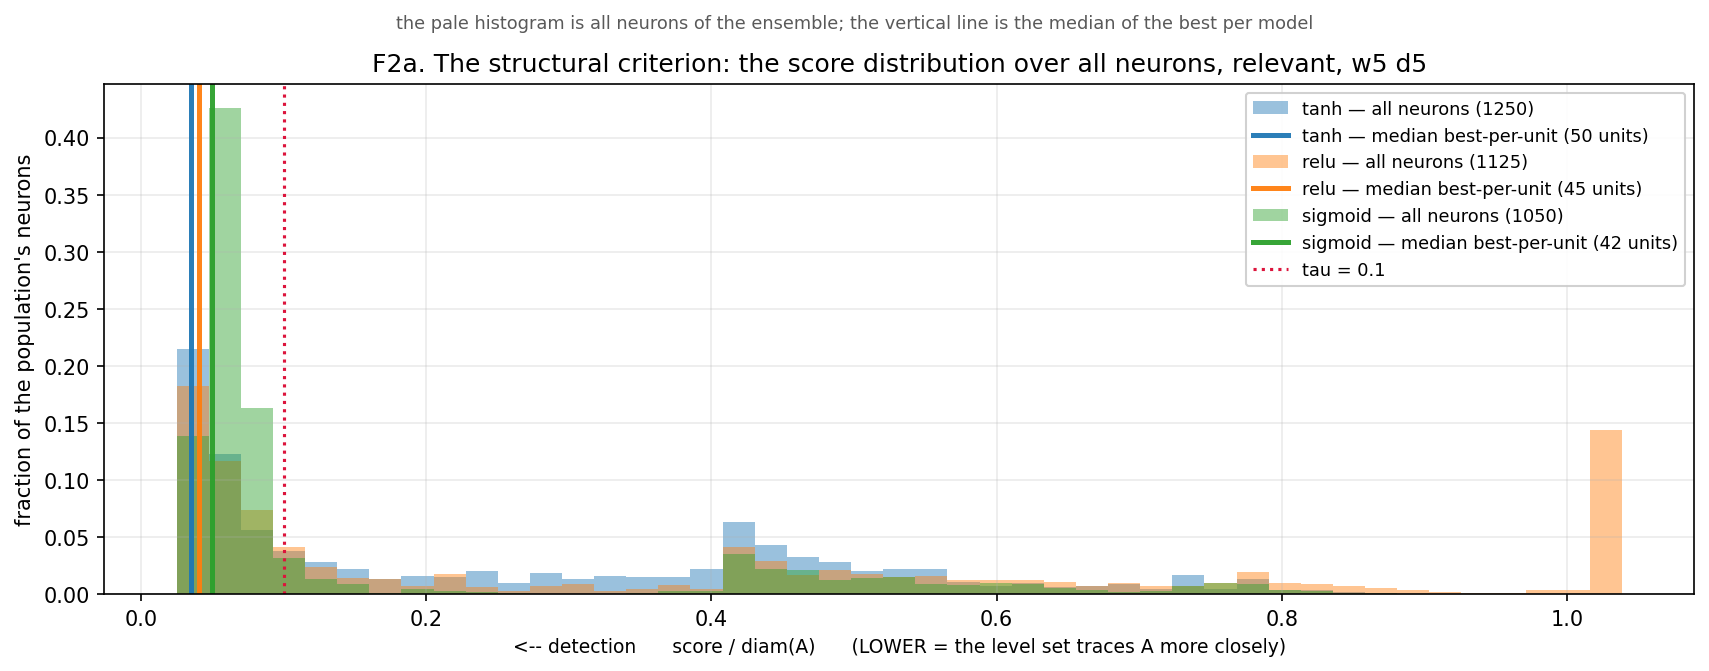

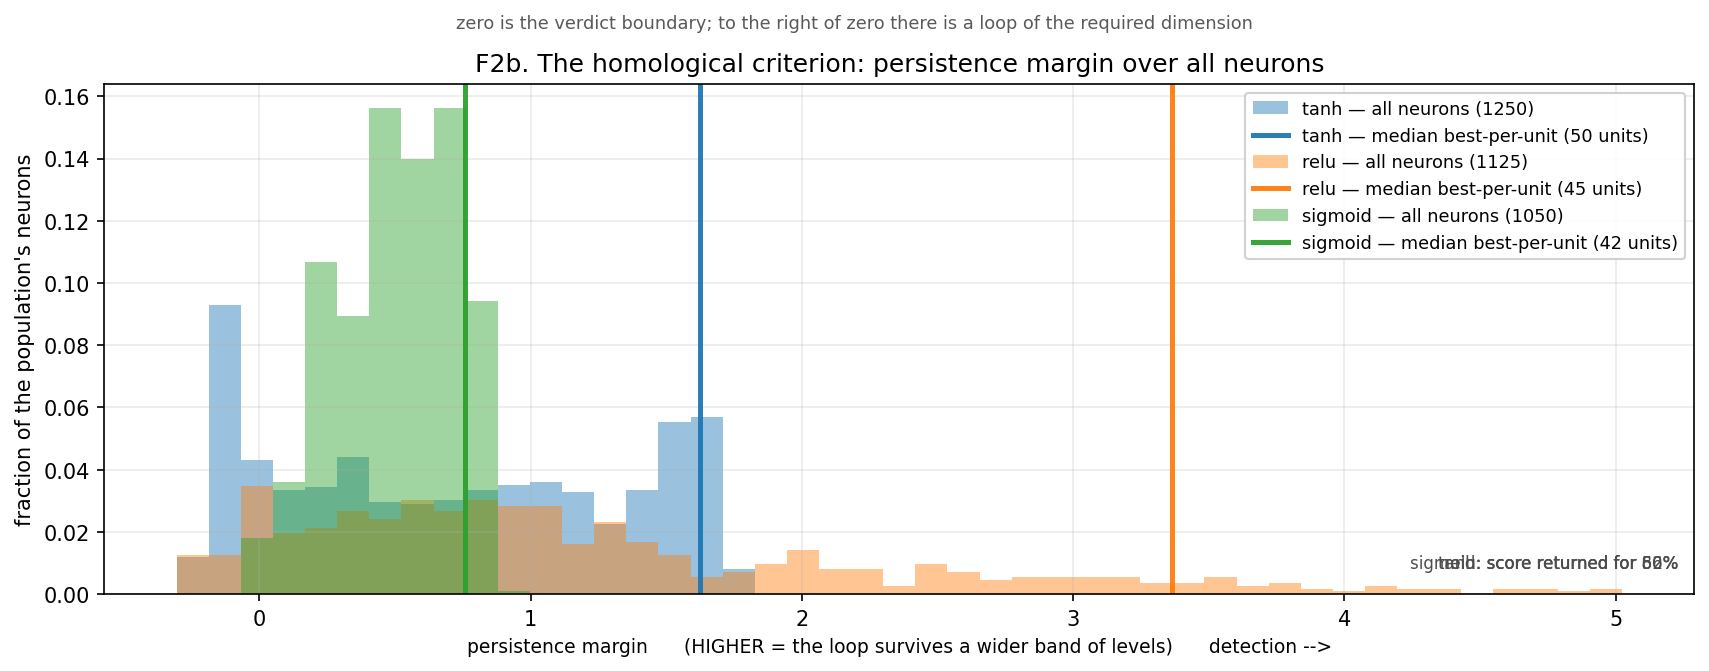

sensitivity of the fraction to the threshold, relevant:
  τ = 0.05:  tanh 0.254  relu 0.197  sigmoid 0.226
  τ = 0.10:  tanh 0.419  relu 0.390  sigmoid 0.741
  τ = 0.15:  tanh 0.485  relu 0.445  sigmoid 0.776

the shape of the distribution: where the neurons stand relative to the threshold
  tanh    : score < 0.05 for 0.254; in [0.05, 0.10] for 0.166
  relu    : score < 0.05 for 0.197; in [0.05, 0.10] for 0.193
  sigmoid : score < 0.05 for 0.226; in [0.05, 0.10] for 0.515

sigmoid against the tanh ladder of continued training (the same cell, different duration):


  tanh, rung x1  , epoch    43:  fraction 0.4269  best 0.0363
  tanh, rung x10 , epoch   439:  fraction 0.5127  best 0.0266
  tanh, rung end , epoch  2999:  fraction 0.4702  best 0.0292
  sigmoid, gate,       epoch   262:  fraction 0.7410  best 0.0499
  relu   , gate,       epoch    47:  fraction 0.3902  best 0.0405

dead neurons and the fraction of witnesses among the living:
  relevant    tanh    : field constant on the feature for 0.000; fraction of witnesses of all 0.419, among the living 0.419; homological fraction 0.5280
  relevant    relu    : field constant on the feature for 0.256; fraction of witnesses of all 0.390, among the living 0.524; homological fraction 0.4658
  relevant    sigmoid : field constant on the feature for 0.000; fraction of witnesses of all 0.741, among the living 0.741; homological fraction 0.7857
  irrelevant  tanh    : field constant on the feature for 0.000; fraction of witnesses of all 0.000, among the living 0.000; homological fraction 0.0016
  irrele

In [41]:
from visualization.calibration_plots import plot_populations

POP = [(NAMES[t], {"dataset": REL, "tag": t, "role": "target"}, c)
       for t, c in zip(ACT_TAGS, ("tab:blue", "tab:orange", "tab:green"))]
plot_populations(scores_act, "structural", POP, threshold=aw.TAU,
                 title="F2a. The structural criterion: the score distribution over all neurons, "
                       "relevant, w5 d5",
                 caption="the pale histogram is all neurons of the ensemble; "
                         "the vertical line is the median of the best per model",
                 save_path=FIG / "F2a_activation_populations.png")
show(FIG / "F2a_activation_populations.png")

# The same slice by the second criterion. Its direction is the opposite (higher = better);
# plot_populations takes it from calibration.DIRECTIONS by itself.
plot_populations(scores_act, "homological", POP,
                 title="F2b. The homological criterion: persistence margin over all neurons",
                 caption="zero is the verdict boundary; to the right of zero there is a loop of the required dimension",
                 save_path=FIG / "F2b_activation_homological.png")
show(FIG / "F2b_activation_homological.png")

print("sensitivity of the fraction to the threshold, relevant:")
for tau in (0.05, 0.10, 0.15):
    line = "  ".join(
        f"{NAMES[t]} "
        f"{(df_act[(df_act.dataset_type == REL) & (df_act.tag == t) & (df_act.feature_role == 'target')].score <= tau).mean():.3f}"
        for t in ACT_TAGS)
    print(f"  τ = {tau:.2f}:  {line}")

print("\nthe shape of the distribution: where the neurons stand relative to the threshold")
for tag in ACT_TAGS:
    b = df_act[(df_act.dataset_type == REL) & (df_act.tag == tag)
               & (df_act.feature_role == "target")]
    print(f"  {NAMES[tag]:8s}: score < 0.05 for {(b.score < 0.05).mean():.3f}; "
          f"in [0.05, 0.10] for {b.score.between(0.05, 0.10).mean():.3f}")

print("\nsigmoid against the tanh ladder of continued training (the same cell, different duration):")
ot_f = aw.load_overtraining(EXT.results_dir)
for r in aw.paired_rungs(ot_f, REL, "tanh_w5_d5", n_boot=500).itertuples():
    print(f"  tanh, rung {r.rung:4s}, epoch {r.median_epoch:5.0f}:  "
          f"fraction {r.fraction:.4f}  best {r.median_best:.4f}")
for tag in ("sigmoid_w5_d5", "relu_w5_d5"):
    t = df_act[(df_act.dataset_type == REL) & (df_act.tag == tag)
               & (df_act.feature_role == "target")]
    print(f"  {NAMES[tag]:7s}, gate,       epoch "
          f"{t.groupby('model_path').train_stopped_epoch.first().median():5.0f}:  "
          f"fraction {t.witness.mean():.4f}  best {t.groupby('model_path').score.min().median():.4f}")

print("\ndead neurons and the fraction of witnesses among the living:")
for ds, name in ((REL, "relevant"), (IRR, "irrelevant")):
    for tag in ACT_TAGS:
        b = df_act[(df_act.dataset_type == ds) & (df_act.tag == tag)
                   & (df_act.feature_role == "target")]
        dead = (b.field_grad_norm_on_feature < 1e-9).mean()
        print(f"  {name:11s} {NAMES[tag]:8s}: field constant on the feature for {dead:.3f}; "
              f"fraction of witnesses of all {b.witness.mean():.3f}, "
              f"among the living {b.witness.mean() / max(1e-9, 1 - dead):.3f}; "
              f"homological fraction {b.hom_witness.fillna(False).mean():.4f}")


### What F2 shows

**Outcome 2 is confirmed: the `sigmoid` distribution is not shifted to the left but pressed against the threshold.**
More than half of its neurons — **51.5%** — fall into the narrow band [0.05, 0.10], that is, they pass `τ` only just;
for `tanh` 16.6% are in the same band. And in the region of really good values, below 0.05, `sigmoid` **no longer
wins**: 22.6% against 25.4% for `tanh`.

The direct check of this is to move the threshold. If the fraction of 0.741 rests on the cluster right at the
threshold, at a stricter threshold it must fall apart:

| threshold | tanh | relu | sigmoid |
|---|---|---|---|
| τ = 0.15 | 0.485 | 0.445 | **0.776** |
| τ = 0.10 | 0.419 | 0.390 | **0.741** |
| τ = 0.05 | **0.254** | 0.197 | 0.226 |

At `τ = 0.05` the order **flips**: `sigmoid` goes from the best to worse than `tanh`.

**Outcome 3 falls away.** The ladder of E gives for `tanh` in the same cell: the gate (43 epochs) — a fraction of
0.427, the best 0.0363; `×10` (439 epochs) — 0.513 and 0.0266. That is, sixfold continued training raises the
fraction of `tanh` from 0.427 to 0.513, while `sigmoid` at its 262 epochs gives 0.741 — four times more than duration
gives. And the main thing: for `tanh` continued training **improves** the best neuron (0.0363 → 0.0266), while
`sigmoid` at a comparable duration stands at 0.0499. The difference in the best neuron is not explained by time.

**But outcome 1 does not fall away entirely, and this refines the conclusion.** The second figure shows that the
homological criterion — which knows neither about `τ` nor about where `A` stands — also puts `sigmoid` higher: the
fraction of neurons with a loop of the required dimension is **0.786** against 0.528 for `tanh` and 0.466 for `relu`.
That is, sigmoid neurons **really do have a closed level curve more often**, and this is not an artefact of the
threshold.

Putting the two figures together, we get the precise statement: **`sigmoid` has more closed level curves, but they
lie around the circle more loosely.** Many loops passing `A` at a distance just under `τ`, and not one hugging it
tightly. Neither "better" nor "worse" — a different distribution, and the threshold `τ` cuts it in an unlucky place.

**`relu` turned out to have a peculiarity of its own, and it is about the denominator.** For **25.6%** of its neurons
the norm of the field's gradient on the target feature is zero to machine precision — these are dead ReLUs, they do
not activate on this region at all. They give a peak at a score ≈ 1.0 on the first figure and cannot witness in
principle, exactly like the neurons of layer 0. If the fraction is counted over the **living** neurons, `relu` gives
**0.524** against 0.419 for `tanh` — that is, in truth it is not worse but better. On the irrelevant dataset there are
even more dead ones, 29.7%.

**One warning about the homological criterion on ReLU.** On the irrelevant dataset the fraction of its firings is
0.0150 for `relu` against 0.0016 for `tanh` — an order of magnitude more. A piecewise linear field gives closed
polylines where a smooth one gives nothing. This does not change the structural verdict (zero witnesses), but when
transferring the homological criterion to non-smooth activations the threshold will have to be recalibrated.

---

## Summary of F

**1. The main result of the experiment does not depend on the activation.** The relevant circle is detected by all
three (`p_superior` 0.995–1.000 against their own floor, a witness exists in 96–100% of models), the irrelevant one by
**none**: zero witnesses for all three, both on the target and on the null placements. This is exactly the check for
which the part was done, and `tanh` is in no way special in it.

**2. Raw scores must not be compared between activations — the floor is the scale.** By the median of the best neuron
the order is `tanh` < `relu` < `sigmoid` (0.0349 / 0.0405 / 0.0499), while by the ratio of the target to its own floor
the order is **the reverse**: `relu` 0.133 < `tanh` 0.199 < `sigmoid` 0.263. For `relu` the floor is 1.7 times higher,
i.e. it is harder for a piecewise linear field to hit an arbitrary circle by chance, and hitting the right one counts
for more. This is the same transfer rule that already worked along width.

**3. `sigmoid` has more closed level curves, but they lie more loosely.** Its witness fraction is 0.741 against 0.419
for `tanh`, and the homological criterion confirms this independently (0.786 against 0.528) — that is, it really does
have more loops. But its best neuron is worse (0.0499 against 0.0349), half of the neurons stand in the band
[0.05, 0.10] right under `τ`, and at `τ = 0.05` the order between activations flips. This is not explained by training
duration: the ladder of E raises the fraction of `tanh` only to 0.513 and at the same time improves the best neuron.

**4. A quarter of `relu`'s neurons are dead on the target feature** (`|∇f| = 0` for 25.6% on relevant, 29.7% on
irrelevant). They cannot witness for the same reason as the neurons of layer 0, and they should drop out of the
denominator. With the correction `relu` gives a fraction of **0.524** against 0.419 for `tanh` — that is, by both honest
quantities, the fraction among the living and the ratio to the floor, ReLU turns out to be **stronger** than the smooth
activation, not weaker. The homological criterion, however, gives an order of magnitude more false loops on it.

**5. Trainability differs, and this is also a result.** Out of fifty attempts the task is solved by 50 (`tanh`), 45
(`relu`) and 42 (`sigmoid`), and `sigmoid` spends six times more epochs. One has to report by the actual N, which is
what is done here.

### What F does not show

* **One cell, one width, one depth.** Everything above is about `w5 d5`. It must not be transferred to other
  architectures without a check, all the more so since the fraction for `relu` depends on the fraction of dead neurons,
  and that surely depends on width.
* **The null features are chosen for `tanh`.** They were chosen so as to give a lower estimate on tanh networks; for other
  activations the lower estimate would be other placements. So the target/floor ratio is comparable within an activation
  but not between activations — especially on the irrelevant dataset.
* **The level grid for ReLU is chosen linear for the sake of comparability.** For a non-negative heavy-tailed field there
  is an exponential variant, and it was not tried.
* **The homological threshold on non-smooth activations is not calibrated.**

---

# Summary of experiment 2

The detailed analysis is **`reports/exp2_arch_sweep.md`**, not this notebook.

**The pool.** 30 cells, 1,500 models, 184,050 rows on a common box (`N_A = 44.222`), plus the separately computed
over-training rungs and two other activations. The reference cell reproduced experiment 1 to the sixth decimal
(0.034946), 49 models of 50 with a witness, 41.9% witnesses among all neurons. The theorem controls hold exactly:
**0 witnesses out of 45,450 rows on layer 0 and 0 out of 2,250 at width ≤ 2.**

---

## 1. Irrelevant topology is produced neither by capacity, nor by width, nor by time

The circle in the two datasets is bitwise the same; the only difference is whether the task needs it. On the
irrelevant dataset there is no detection **at any excess**: 0 witnesses out of 16,050 target rows in fourteen cells of
sixteen. All seven firings live in the two widest cells (`w20 d5` and `w40 d5`) and on the first two layers; three
components of seven are clipped by the box.

Three independent checks say one and the same thing.

* **Doubling the width does not strengthen the signal.** The rate goes 4/50 → 3/50, and the null placements start
  firing **more often** than the target: 8/100. The local slope of the target returns from −0.58 to −0.37 — there is no
  "acceleration" from which a crossing of `τ` outside the pool would follow.
* **The best firing on this dataset belongs to a null, not to the target.** 0.0667 against 0.0780, and its component is
  entirely inside the box.
* **Continued training up to three thousand epochs creates nothing.** Zero witnesses in all fifteen (cell, rung) pairs,
  and the homological fraction does not grow anywhere either.

The second criterion comes to the same verdict independently: the best `persistence_margin` on the target is −0.017
against +1.74 on the relevant task.

**The floor is a lower estimate, and that is how it must be stated.** The null placements were chosen by hand from
considerations of covering the task, and those that give a low score were kept. So the correct statement is "the score
on the irrelevant circle lies **above** this lower estimate"; one cannot claim that the distributions on null and
irrelevant features differ.

## 2. Relevant topology is carried by the whole network, not by a distinguished neuron

The fraction of witnesses **does not depend** on width (0.385–0.428 as the width grows 13.3-fold, a slope of
+0.021 [−0.009, +0.053]), while their number grows in proportion to the network — from six to eighty-two. Each added
neuron picks up the circle with roughly the same probability as those already there; there is no idle width. Width also
makes the ensemble more homogeneous: the spread of the best score falls eightfold (σ 0.024 → 0.003).

**Width buys not only attempts.** The multiplicity reference is taken from the measured floor of the same cells: the
target falls as `N^(−0.315)`, the floor as `N^(−0.117)`, the intervals do not overlap.

**Multiplicity is counted by the width of a layer, not by the number of neurons.** At an equal number of neurons the
floor is lower for the architecture that is wider: 0.253 against 0.219 at `N = 15`, 0.177 against 0.206 at `N = 50`,
0.198 → 0.246 along the equal-budget diagonal. Plausibly because the neurons of one layer are parallel attempts, while
the neurons of the next layer are functions of them.

**At depth 1 the encoding must be distributed.** In `w24 d1` not one of the twenty-four neurons can witness by the
theorem, and the data give exactly zero — but **the output of the same network witnesses the circle in all fifty
models**. The zero is a statement about neurons, not about the network.

## 3. The feature is built gradually, and the construction has a length

The fraction of witnesses grows from layer to layer; within a model the number of witnesses does not fall even once in
96–100% of models. What grows is the whole population of the layer, not its tail. The floor and the irrelevant circle
have no such growth at all.

**The curve of the fraction by layer is not a straight line but a step, and its break stands at about layer √d.** The
fraction of witnesses does not go smoothly: two or three layers of almost nothing, then a sharp rise, then a shelf near
one. At `d = 5` this is `0.000 → 0.012 → 0.328 → 0.816 → 0.940`, and **the break is the stretch where the curve passes
from "almost nothing" to "almost everything"**. Numerically its position is given by **the half-height**: the point
where the curve crosses 0.5 (at `d = 5` — layer 2.35).

The question was this: as depth grows, does the break stand at one and the same **layer** (the feature is always
assembled in so many transformations) or at one and the same **fraction of depth** (the network stretches the
construction in proportion to its size)? Neither:

| depth | 2 | 3 | 5 | 8 | 10 |
|---|---|---|---|---|---|
| half-height, layer index | 1.37 | 1.61 | 2.35 | 2.62 | 3.05 |
| half-height, fraction of depth | 0.68 | 0.54 | 0.47 | 0.33 | 0.31 |
| **layer / √d** | 0.97 | 0.93 | 1.05 | 0.93 | 0.97 |

As depth grows fivefold, the absolute half-height grows 2.2-fold, and the relative one falls by as much: both hypotheses
miss equally and in opposite directions, and halfway between them lies the square root. The rule was noticed at depths
up to the eighth and confirmed at the tenth (prediction 3.16, observation 3.05), i.e. it is no longer a fit to the
existing points.

Hence the transfer rule: **a statement about a specific layer is valid only within the depth at which it was
measured.** "On layer 2 the fraction is such and such" is about `d = 5`; at `d = 10` the second layer still stands
before the break.

**The construction takes about four transformations and does not continue beyond that.** At `w5 d5` it runs to the last
layer, at `w5 d8` it ends at the fifth, at `w5 d10` at the sixth or seventh. Hence a refinement of the conclusion about
depth: the fraction over the whole network is by definition the mean of the per-layer fractions, so in a deep network it
is higher not because the feature is singled out better but because more layers stand after saturation. **Depth
increases the extent of the feature, not its quality** — which agrees both with the worse best neuron at `d = 8, 10`
and with the worse head at `d = 10` (68%).

**The two criteria diverge on the last layers, and this is the most interesting observation of part C.** At `d = 10` the
structural fraction falls towards the end (0.960 → 0.956 → 0.932), while the homological one grows to one
(0.976 → 0.996 → 1.000); at no depth does the homological curve dip anywhere. The closed level curves on deep layers do
not disappear — there become more of them — but their **geometry** changes: they stop resembling our circle while
continuing to solve the task.

## 4. Continued training improves the needed feature and does not create an unneeded one

The rungs are taken from **one run**, so the comparison is within-model and the variance over initialisations is
excluded from it.

* **Continued training improves the score on all capable cells**, the paired difference nowhere covers zero: from
  −0.0055 at `w3 d5` to **−0.0728** at `w3 d2`.
* **The observed correlation "trained longer — worse" was selection, not causality.** Within `w3 d5` it equalled +0.70;
  the paired effect has the opposite sign. Slow runs are worse because they got a bad initialisation.
* **The confound "width against duration" acts AGAINST the conclusions of part B.** Wide networks stop fourteen times
  earlier than narrow ones, and stopping training early worsens the score. So the measured advantage of width is a lower
  estimate.
* **The minimal network lacks time, not capacity.** At `w3 d2` — six neurons — at the gate a witness exists in 41% of
  models, after continued training in **100%**, and the best score falls from 0.1025 to 0.0327, level with the
  reference.
* **The effect is not an artefact of the instrument.** The field moves radically (the norm of the weights up to sixfold,
  the fraction saturated up to 0.76), but the strongest movement of the field happens in the control cell `w24 d1`,
  where the score moves least.

## 5. The verdict does not depend on the activation function

The relevant circle is detected by all three activations (`p_superior` 0.995–1.000 against their own floor), the
irrelevant one by **none**. But the numbers must not be compared between activations: by the median of the best the
order is `tanh` < `relu` < `sigmoid`, while by the ratio to their own floor it is **the reverse** (`relu` 0.133 <
`tanh` 0.199 < `sigmoid` 0.263).

`sigmoid` really does have more closed level curves (homological fraction 0.786 against 0.528), but they lie around the
circle more loosely: half of the neurons stand in the band [0.05, 0.10] right under `τ`, and at `τ = 0.05` the order
between activations flips. A quarter of `relu`'s neurons are **dead** on the target feature; with the correction for the
denominator it gives 0.524 against 0.419 for `tanh`.

---

## What carries over to the next experiments

1. **The unit of observation and the unit of resampling** — a (model, feature) pair by its best neuron, a bootstrap over
   models, never over neurons.
2. **Multiplicity is measured by the floor of the same cells, not by a law**, and is counted by **the width of a layer**,
   not by the total number of neurons.
3. **Keep both degenerate classes of neurons in the pool** — layer 0 and width ≤ 2 are the only theorem-based check of
   the instrument's validity. A third has been added to them: dead ReLUs.
4. **Statements about a specific layer are valid only within their depth** (the √d rule).
5. **Compute the network's head as `sigmoid(model(x))`**, not as the raw logit.
6. **Along any axis of architectures, report the training duration** — it changes together with the architecture
   several-fold.
7. **Scores are not comparable between activations**, and null features chosen for one activation need not be a lower
   estimate for another.

## What does not carry over

* **`N^(−0.28)` from experiment 1** — obtained from the sweep over the number of levels on the minimum over null neurons;
  it is not a law about the number of neurons.
* **The "instrument ceiling" of 0.0343** — in this pool 4,461 neurons out of 30,300 are below it, the minimum is 0.0147.
  It is the overhead of a particular probe. A by-product, not something the architecture sweep looked for.
* **The absolute values of the fractions and of the floor** — they are tied to this task, this box and `N_A = 44.222`.
* **"The length of the construction ≈ 4 layers"** — measured at three depths at one width.

## Limits of applicability

* **Nothing about necessity.** Observed multiplicity is not a claim that the neurons are needed. The causal question
  requires ablation, which is not here.
* **A high fraction at the output is weak evidence of encoding**, because the decision boundary on `simple_relevant` is
  the target. The middle layers are the informative ones.
* **The continuity filter has been checked on seven elements** and under conditions where the separation is partly
  tautological.
* **On the irrelevant dataset the movements of the score cannot be interpreted** — the control cell wanders there more
  than the target ones. Only the count of witnesses can be interpreted.
* **One feature shape, one task, two additional activations on one cell.**

---

# Budget

> **The estimate refers to the main run of the pool.** Later the cells `w40 d5` and `w5 d10` were added to it (and, for
> parts E and F, the over-training rungs and the other activations): they were computed in a separate run on the
> server, by the spec `exp2_extended` with a bitwise identical evaluation configuration. With them the pool has 30 cells
> and 184,050 rows.

26 cells (14 architectures; widths 1 and 2 exist only on `simple_irrelevant`), **50 models** in each, 3 features per
neuron, both criteria. The cost of a row was measured on the real evaluation path at R = 200 with the structural and the
homological criterion (delaunay, `max_sample_points = 7000`): **386 ms on one thread** — the mode in which the shards
work. On two threads the same row costs 327 ms: BLAS gives 18%, and we give that up deliberately, because a shard is a
job for one core, and the speed-up comes from the pool, not from threads within a shard.

> **A correction after the actual run.** 386 ms is an estimate from a small probe, and it is about six times too low. In fact 109,050 rows took 5.2 hours on 20 cores, that is, about **3.4 s per row on one thread**; the estimates below must be read with this multiplier.

| stage | locally (14 cores) | `c1.32` (32 vCPU) |
|---|---|---|
| trainability pre-check | ~10 min | ~10 min |
| training (~1250 runs) | **~20–25 min** | ~20–25 min |
| criteria evaluation (109,050 rows) | **~50 min** | ~22 min |
| **total** | **~1 h 25 min** | **~55 min** |

Evaluation in a single process takes 11.7 h; it parallelises honestly. Training is cheap almost everywhere — the gate
fires at 12–230 epochs, which is seconds per model — but the two depth-1 cells on `simple_relevant` take ~1900 epochs
per model, that is, about **20 minutes each in one process**. A cell is the indivisible unit of parallelism for
training, so it is exactly these two that set the time of the stage, and adding workers beyond 26 is pointless.

The most expensive cell of the evaluation is `w20 d5`, 15,000 rows per dataset; sharding cuts it into chunks of ~800
rows, so it does not set the time of the stage.

**About the hardware.** Measured: the epoch time is 12.1 ms at w5 d5 and 12.6 ms at w20 d5 — a twentyfold growth in the
number of neurons changes nothing, the whole cost is dispatch, not arithmetic. The field of a neuron is 1.2% of the cost
of evaluation; the other 99% is the sweep over levels with connected components and the Chamfer distance, work on the
grid. So **GPU configurations are useless both for training and for evaluation**; `c1.32` (32 vCPU) is taken, not
`gt4.1` / `g1.1`.